PDF.yr - size (1 and 5000) and shape

/opt/anaconda3/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/anaconda3/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Figure size 1000x800 with 0 Axes>

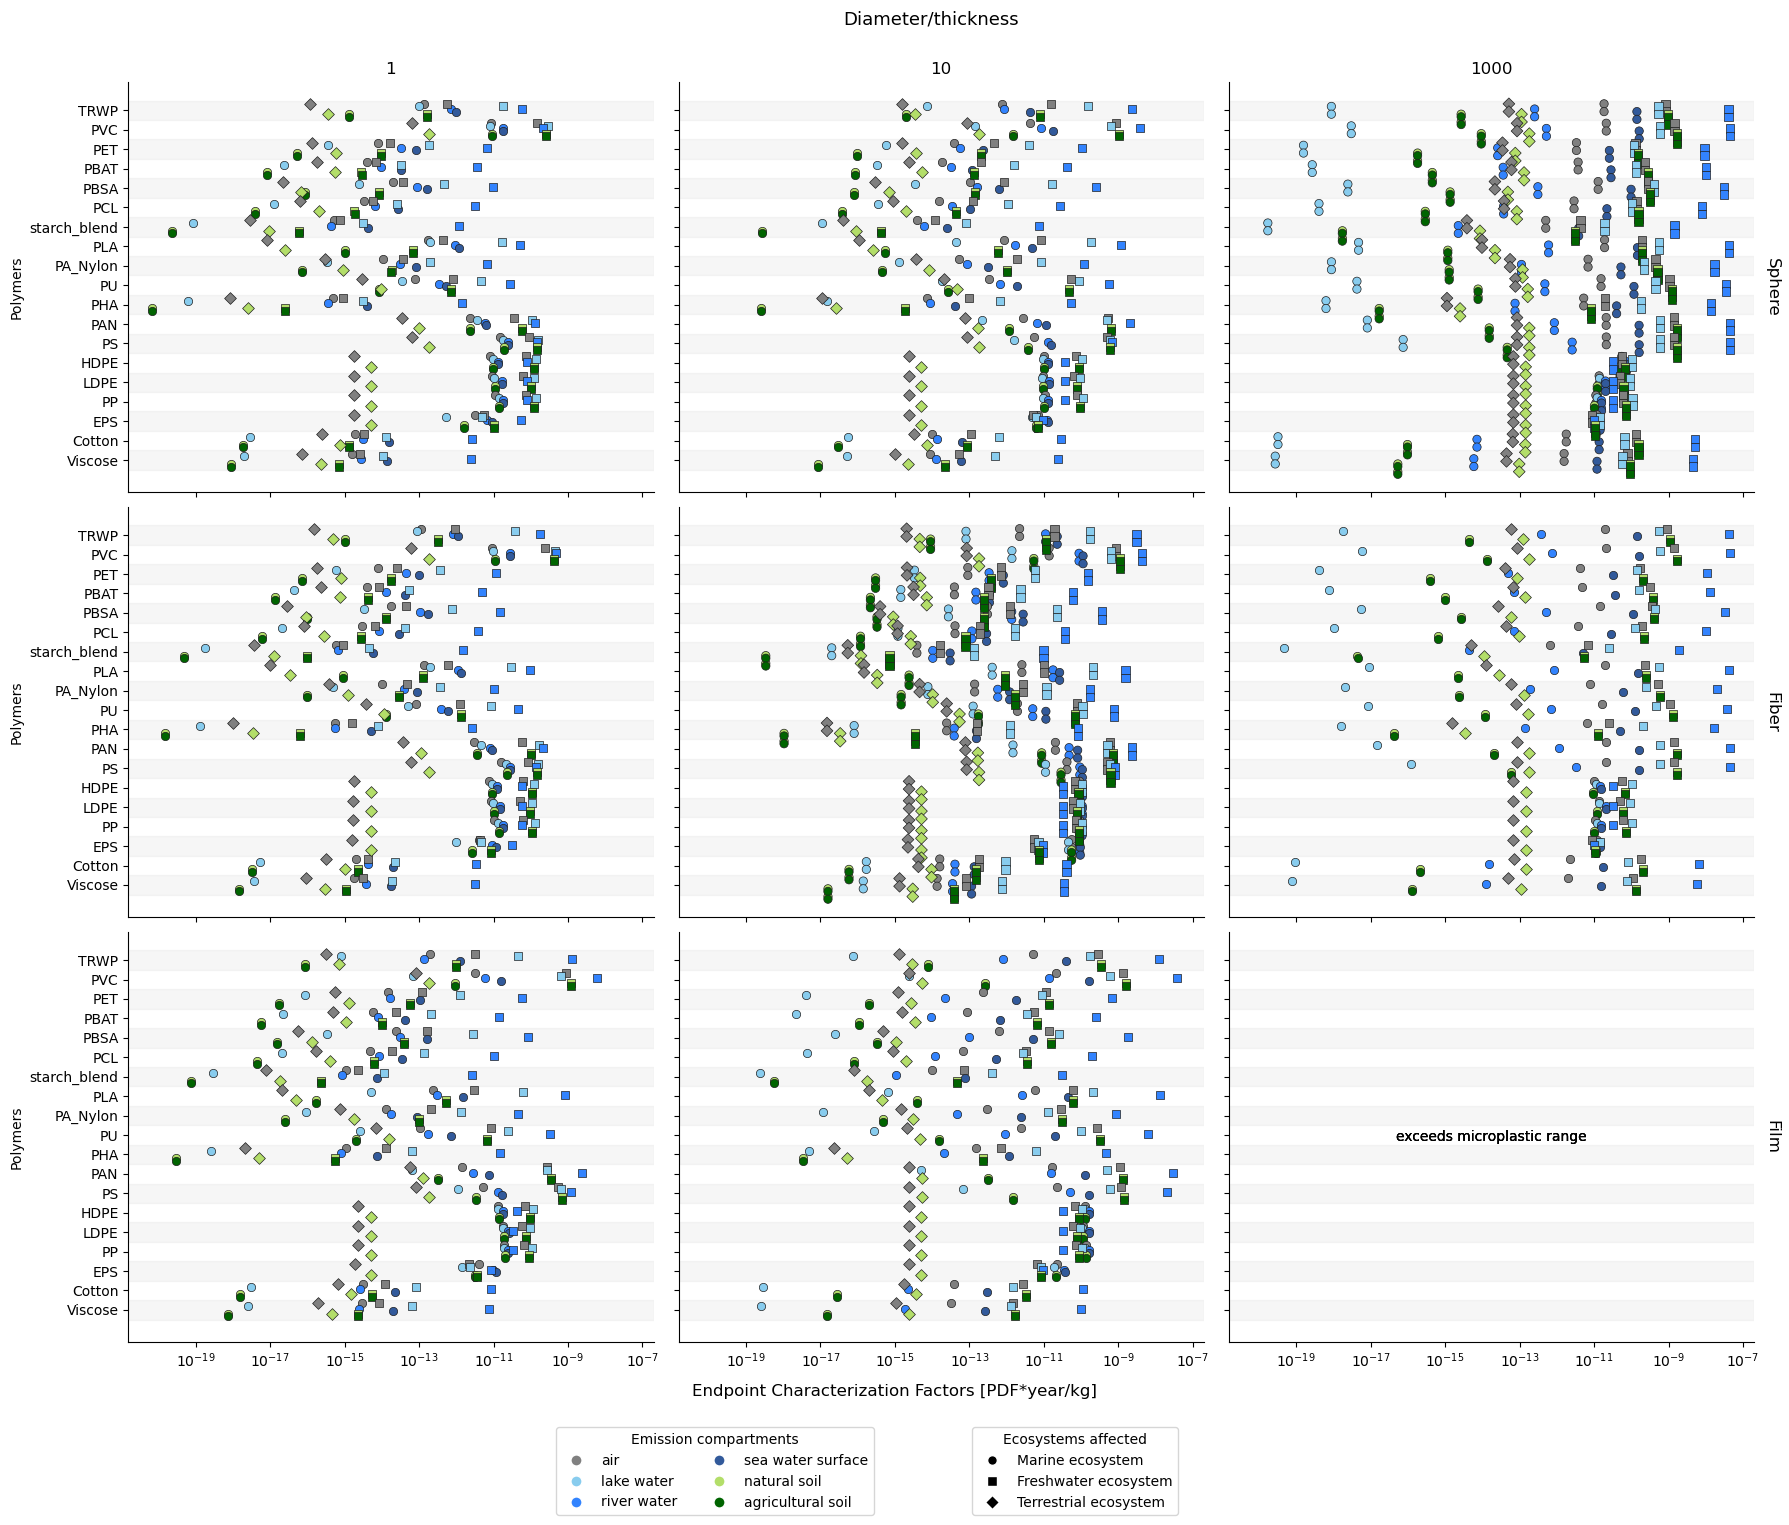

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import plotly.io as pio

# Read the Excel file
file_path = "results/SI_C.xlsx"
sheet_name = "CF_end_PDF_yr"

# Read the specified sheet
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Define filter conditions
size_filter = [1, 10, 1000]
shape_filter = ["Sphere", "Fiber", "Film"]
region_filter = "World" #region to be updated
emission_compartment_filter = [
    "continental air",
    "continental riverwater",
    "continental lakewater",
    "continental seawater surface",
    "continental natural soil",
    "continental agricultural soil"
]

df_filtered = df[
    (df["size"].isin(size_filter)) &
    (df["shape"].isin(shape_filter)) &
    (df["region"] == region_filter) &
    (df["emission_compartment"].isin(emission_compartment_filter))
].copy()  # Use .copy() to avoid SettingWithCopyWarning

# Spécifier l'ordre des polymères
polymers_order = ['TRWP', 'PVC', 'PET', 'PBAT', 'PBSA', 'PCL','starch_blend', 'PLA', 'PA_Nylon', 'PU', 'PHA', 'PAN', 'PS', 
                  'HDPE', 'LDPE', 'PP', 'EPS', 'Cotton','Viscose']
df_filtered['polymer'] = pd.Categorical(df_filtered['polymer'], categories=polymers_order, ordered=True)

# Spécifier l'ordre des tailles pour l'affichage
size_order = size_filter
df_filtered['size'] = pd.Categorical(df_filtered['size'], categories=size_order, ordered=True)

# Spécifier l'ordre des shapes pour l'affichage
shape_order = ["Sphere", "Fiber", "Film"]
df_filtered['shape'] = pd.Categorical(df_filtered['shape'], categories=shape_order, ordered=True)

# Palette pour les compartiments
compartment_palette = {"continental air": "grey", "continental lakewater": "#88ccee", "continental riverwater": "#3283FE", 
                       "continental seawater surface": "#325A9B",
                       "continental natural soil": "#b3de69", "continental agricultural soil": "darkgreen"}

markers = {
    'marine_geom_mean': 'o',
    'freshwater_geom_mean': 's', 
    'terrestrial_geom_mean': 'D'
}

# Create mapping for ecosystem display names
ecosystem_display_names = {
    'marine_geom_mean': 'Marine',
    'freshwater_geom_mean': 'Freshwater',
    'terrestrial_geom_mean': 'Terrestrial'
}

# Before creating FacetGrid, adjust the figure size and subplot params
plt.figure(figsize=(10, 8))
#plt.subplots_adjust(top=0.92)  

# Create FacetGrid with rows for shapes and columns for sizes
g = sns.FacetGrid(df_filtered, row='shape', col='size', height=6, aspect=1, 
                  sharey=True, sharex=True, margin_titles=True)

# Boucle sur chaque subplot
for ax in g.axes.flat:
    # Get current row and column indices
    row_idx, col_idx = np.where(g.axes == ax)
    shape = shape_order[row_idx[0]]
    size = size_order[col_idx[0]]
    
    subset = df_filtered[(df_filtered['shape'] == shape) & (df_filtered['size'] == size)]
    
    # Ajouter des bandes alternées sur l'arrière-plan
    for i, polymer in enumerate(polymers_order):
        if i % 2 == 0:
            ax.axhspan(i - 0.5, i + 0.5, color='lightgrey', alpha=0.2)
    
    # Loop through each ecosystem column
    for eco_col, marker in markers.items():
        # Filter rows where this ecosystem has data
        eco_data = subset[subset[eco_col].notna() & (subset[eco_col] != 0)].copy()
        
        if not eco_data.empty:
            # Create a temporary column for CF_endpoint using this ecosystem's values
            eco_data_temp = eco_data.copy()
            eco_data_temp['CF_endpoint_temp'] = eco_data_temp[eco_col]
            
            # Plot this ecosystem
            sns.swarmplot(
                data=eco_data_temp, 
                x='CF_endpoint_temp', 
                y='polymer', 
                hue='emission_compartment',
                dodge=True, 
                palette=compartment_palette, 
                hue_order=list(compartment_palette.keys()),
                marker=marker, 
                s=6, 
                edgecolor="auto", 
                linewidth=0.5, 
                ax=ax, 
                legend=False
            )
        else:
            # Add text annotation when no data
            ax.text(0.5, 0.5, "exceeds microplastic range", 
               ha='center', va='center', 
               transform=ax.transAxes,  # Use axes coordinates (0-1)
               fontsize=10, fontweight='normal',
               color='black', style='normal',
               bbox=dict(boxstyle="round,pad=0.2", facecolor='none', alpha=0.8, edgecolor='none',linewidth=0))

    
    ax.set_xscale('log')
    
    # Only add xlabel to bottom row
    if row_idx[0] == len(shape_order) - 1:
        ax.set_xlabel("")
    else:
        ax.set_xlabel("")
    
    # Only add ylabel to first column
    if col_idx[0] == 0:
        ax.set_ylabel("Polymers")
    else:
        ax.set_ylabel("")
    
    # Set titles
    if row_idx[0] == 0:
        ax.set_title(f"Size: {size}")
    
    # Remove top and right spines for cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Définir les labels des axes et les titres
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=12)

#plt.subplots_adjust(bottom=0.25, top=0.85)  # More space at the top
# Add "Diameter/thickness" label above the size labels
g.fig.text(0.52, 0.98, "Diameter/thickness",  # Adjust y-position based on your layout
         ha='center', va='bottom', 
         fontsize=13, color='black',
         transform=g.fig.transFigure)  # Use figure coordinates

# Traduction des noms de compartiments et écosystèmes
compartment_labels = {"continental air": "air", "continental lakewater": "lake water", "continental riverwater": "river water", 
                      "continental seawater surface": "sea water surface", "continental natural soil": "natural soil", "continental agricultural soil": "agricultural soil"}
ecosystem_labels = {'marine_geom_mean': 'Marine ecosystem', 
                    'freshwater_geom_mean': 'Freshwater ecosystem', 
                    'terrestrial_geom_mean': 'Terrestrial ecosystem'}

# Création de la première légende (compartiments)
legend_elements_compartments = []
for compartment, color in compartment_palette.items():
    legend_elements_compartments.append(Line2D([0], [0], marker='o', color='w', label=compartment_labels[compartment],
                                              markerfacecolor=color, markersize=8))

# Création de la deuxième légende (écosystèmes)
legend_elements_ecosystems = []
for ecosystem, marker in markers.items():
    legend_elements_ecosystems.append(Line2D([0], [0], marker=marker, color='white', label=ecosystem_labels[ecosystem],
                                            markerfacecolor='black', markersize=7))

# Créer deux légendes séparées côte à côte
# Première légende (compartiments) - à gauche
legend1 = g.fig.legend(handles=legend_elements_compartments, title="Emission compartments", 
                       loc='lower center', bbox_to_anchor=(0.40, 0.15), 
                       ncol=2, frameon=True, fancybox=True, shadow=False)

# Deuxième légende (écosystèmes) - à droite  
legend2 = g.fig.legend(handles=legend_elements_ecosystems, title="Ecosystems affected", 
                       loc='lower center', bbox_to_anchor=(0.60, 0.15), 
                       ncol=1, frameon=True, fancybox=True, shadow=False)

# Titre général
g.fig.suptitle("", y=1.02)

# Ajouter un titre à l'axe x en bas
plt.figtext(0.5, 0.22, "Endpoint Characterization Factors [PDF*year/kg]", ha='center', fontsize=12)

# Ajuster l'espace pour éviter le chevauchement
plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.95)

# Afficher le graphique
plt.savefig('figures/Figure 3.pdf', bbox_inches='tight', transparent=False)
plt.show()

In [3]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# Load the data from Excel
file_path = 'results/SI_C.xlsx'
df = pd.read_excel(file_path, sheet_name='FF_d')

# Define the polymer, sizes, and shapes you want to plot
selected_polymer = 'EPS'  # Change to your polymer of interest
selected_sizes = [1, 10, 100, 1000]  # Sizes as integers
selected_shapes = ['Sphere', 'Fiber', 'Film']
selected_region = 'North America'

# Filter data for the selected polymer
df_filtered = df[(df['polymer'] == selected_polymer) &
    (df['region'] == selected_region)].copy()

# Define the emission compartments in the desired order
emission_compartments_order = [
    'continental air',
    "continental riverwater",
    'continental lakewater',
    'continental seawater surface',
    'continental natural soil',
    'continental agricultural soil'
]

# DEFINE DESIRED ORDER FOR RECEIVING COMPARTMENTS (legend and bar order)
desired_order = [
    "continental air",
    "continental riverwater",
    "continental lakewater",
    "continental seawater surface",
    "continental seawater column",
    "continental freshwater sediments",
    "continental lake sediments",
    "continental marine sediments",
    "continental natural soil",
    "continental agricultural soil",
    "global air",
    "global riverwater",
    "global lakewater",
    "global seawater surface",
    "global seawater column",
    "global freshwater sediments",
    "global lake sediments",
    "global marine sediments",
    "global natural soil",
    "global agricultural soil"
]

# Create a grid of subplots based on sizes and shapes
num_rows = len(selected_shapes)
num_cols = len(selected_sizes)

# Create the figure with subplots (no titles initially)
fig = make_subplots(
    rows=num_rows, 
    cols=num_cols,
    vertical_spacing=0.05,
    horizontal_spacing=0.05,
    subplot_titles=[''] * (num_rows * num_cols),  # Empty titles
    shared_xaxes=False,
    shared_yaxes=True
)

# Define colors for all compartments (including seawater column)
colors = {
    "continental air": '#E2E2E2', 
    "global air": '#E2E2E2',
    "continental riverwater": "rgb(136, 204,238)", 
    "global riverwater": "rgb(136, 204,238)",
    "continental lakewater": "#3283FE", 
    "global lakewater": "#3283FE",
    "continental seawater surface": "#325A9B", 
    "global seawater surface": "#325A9B",
    "continental seawater column": "#1E3F66",
    "global seawater column": "#1E3F66",
    "continental freshwater sediments": "rgb(241, 226, 204)", 
    "global freshwater sediments": "rgb(241, 226, 204)",
    "continental lake sediments": "rgb(229, 196, 148)", 
    "global lake sediments": "rgb(229, 196, 148)",
    "continental marine sediments": "rgb(166,118,29)", 
    "global marine sediments": "rgb(166,118,29)",
    "continental natural soil": "rgb(179, 222, 105)", 
    "global natural soil": "rgb(179, 222, 105)",
    "continental agricultural soil": "darkgreen", 
    "global agricultural soil": "darkgreen"
}

# Define patterns for continental (striped) vs global (solid)
patterns = {}
for comp in colors.keys():
    if 'continental' in comp:
        patterns[comp] = "/"
    else:
        patterns[comp] = ""

# Loop through shapes (rows) and sizes (columns)
for row_idx, shape in enumerate(selected_shapes, 1):
    for col_idx, size in enumerate(selected_sizes, 1):
        # Filter data for specific size and shape
        plot_data = df_filtered[
            (df_filtered['size'] == size) & 
            (df_filtered['shape'] == shape)
        ].copy()
        
        # Filter only the emission compartments we want
        plot_data = plot_data[plot_data['emission_compartment'].isin(emission_compartments_order)]
        
        # Handle no data case with Option 3 styling
        if plot_data.empty:
            # Add transparent bars to establish axes
            fig.add_trace(go.Bar(
                x=emission_compartments_order,
                y=[0] * len(emission_compartments_order),
                showlegend=False,
                marker_color='rgba(0,0,0,0)',  # Transparent
                hoverinfo='skip'
            ), row=row_idx, col=col_idx)
            
            # Add "Exceeds microplastic size range" annotation
            fig.add_annotation(
                dict(
                    x=0.5,
                    y=0.5,
                    xref="x domain",
                    yref="y domain",
                    text="Exceeds<br>microplastic<br>size range",
                    showarrow=False,
                    font=dict(size=12, color="gray"),
                    opacity=0.8,
                    align="center",
                    valign="middle"
                ),
                row=row_idx, col=col_idx
            )
            
            # Set up axes for consistency
            if row_idx == num_rows:  # Last row - show x labels
                xaxis_labels = emission_compartments_order 
                fig.update_xaxes(
                    ticktext=xaxis_labels,
                    tickvals=emission_compartments_order,
                    tickangle=-45,
                    tickfont=dict(size=9, color='black'),
                    row=row_idx,
                    col=col_idx
                )
            else:
                fig.update_xaxes(
                    showticklabels=False,
                    row=row_idx,
                    col=col_idx
                )
            
            fig.update_yaxes(
                title_text="Mass Fraction (%)" if col_idx == 1 else "",
                range=[0, 100],
                row=row_idx,
                col=col_idx,
                title_font=dict(color='black', size=12)
            )
            
            continue  # Skip the rest for this subplot
        
        # Calculate mass fraction (normalized percentage)
        plot_data_normalized = plot_data.copy()
        
        # Group by emission compartment and normalize FF values within each group
        normalized_groups = []
        for emission_comp in emission_compartments_order:
            group_data = plot_data_normalized[plot_data_normalized['emission_compartment'] == emission_comp].copy()
            if not group_data.empty:
                total_ff = group_data['ff_geom_mean'].sum()
                if total_ff > 0:
                    group_data['Mass Fraction'] = (group_data['ff_geom_mean'] / total_ff) * 100
                else:
                    group_data['Mass Fraction'] = 0
                normalized_groups.append(group_data)
        
        if normalized_groups:
            plot_data_normalized = pd.concat(normalized_groups, ignore_index=True)
        else:
            continue
        
        # Create pivot table with Mass Fraction
        pivot_data = plot_data_normalized.pivot_table(
            index='receiving_compartment',
            columns='emission_compartment',
            values='Mass Fraction',
            aggfunc='sum'
        ).reset_index()
        
        # Get only the emission compartments that actually exist in this data
        existing_emissions = emission_compartments_order
        
        # Create the columns list with receiving_compartment first, then existing emissions
        columns_to_keep = ['receiving_compartment'] + emission_compartments_order
        pivot_data = pivot_data[columns_to_keep]
        
        # Melt the data for plotting
        melted_data = pivot_data.melt(
            id_vars=['receiving_compartment'],
            var_name='emission_compartment',
            value_name='Mass Fraction'
        )
        
        # Fill NaN values with 0 for plotting
        melted_data['Mass Fraction'] = melted_data['Mass Fraction'].fillna(0)
        
        # --- ORDER THE RECEIVING COMPARTMENTS ---
        # Get compartments that actually exist in this data
        compartments_in_data = melted_data['receiving_compartment'].unique()
        
        # Create order list for this specific plot (only compartments that exist)
        order_for_this_plot = [comp for comp in desired_order if comp in compartments_in_data][::-1]
        
        # Convert to categorical with desired order
        melted_data['receiving_compartment'] = pd.Categorical(
            melted_data['receiving_compartment'], 
            categories=order_for_this_plot,
            ordered=True
        )
        
        # Sort the data by the desired order
        melted_data = melted_data.sort_values('receiving_compartment', ascending=True)

        # Convert to categorical with desired order for x-axis
        melted_data['emission_compartment'] = pd.Categorical(
            melted_data['emission_compartment'],
            categories=existing_emissions,
            ordered=True
        )
        # Sort by emission compartment (maintaining receiving compartment groups)
        melted_data = melted_data.sort_values(['emission_compartment', 'receiving_compartment'])

        
        # Create bar chart
        bar_fig = px.bar(
            melted_data,
            x="emission_compartment",
            y="Mass Fraction",
            color="receiving_compartment",
            pattern_shape="receiving_compartment",
            color_discrete_map=colors,
            pattern_shape_map=patterns,
            category_orders={"emission_compartment": existing_emissions}
        )
        
        # Add traces to the subplot
        for trace in bar_fig['data']:
            # Hide legend for all but first subplot
            if not (row_idx == 1 and col_idx == 1):
                trace.showlegend = False
            
            # Add trace to the correct subplot position
            fig.add_trace(trace, row=row_idx, col=col_idx)
        
        # Update x-axis - only show labels on last row
        if row_idx == num_rows:  # Last row
            xaxis_labels = existing_emissions
            fig.update_xaxes(
                ticktext=xaxis_labels,
                tickvals=existing_emissions,
                tickangle=-45,
                tickfont=dict(size=9, color='black'),
                row=row_idx,
                col=col_idx
            )
        else:
            # Remove all x-axis labels for non-last rows
            fig.update_xaxes(
                showticklabels=False,
                row=row_idx,
                col=col_idx
            )
        
        # Update y-axis - only show label on first column
        fig.update_yaxes(
            title_text="Mass Fraction (%)" if col_idx == 1 else "",
            range=[0, 100],
            row=row_idx,
            col=col_idx,
            title_font=dict(color='black', size=12)
        )

# Update layout with higher title position
fig.update_layout(
    #title=f"<i>Mass Fraction Distribution for {selected_polymer} polymer<br>by size and shape</i>",
    legend_title="Receiving compartments",
    font=dict(size=12),
    title_font=dict(size=14, color='black'),
    legend=dict(
        traceorder='reversed',
        font=dict(size=9, color='black'),
        x=1.12,
        y=0.5,
        xanchor='left',
        yanchor='middle',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1,
        title=dict(
        side='top',  # This makes title appear at top (centered horizontally by default)
        font=dict(size=12))  # Adjust size if needed
    ),
    width=250 * num_cols + 200,
    height=300 * num_rows + 50,
    #title_x=0.5,
    #title_xanchor='center',
    #title_y=0.98,  # Moved title higher (default is 0.98, try 0.99 or 1.0)
    barmode='stack',
    showlegend=True,
    margin=dict(t=80, b=150, l=80, r=180)  # Increased top margin for "Diameter/thickness" label
)

# Add "Diameter/thickness" label above the size labels
fig.add_annotation(
    dict(
        x=0.5,
        y=1.05,  # Above the size labels
        xref='paper',
        yref='paper',
        text="Diameter/thickness",
        showarrow=False,
        font=dict(size=13, color='black'),
        xanchor='center',
        yanchor='bottom'
    )
)

# Add size labels on top of each column
for col_idx, size in enumerate(selected_sizes, 1):
    fig.add_annotation(
        dict(
            x=(col_idx - 0.5) / num_cols,
            y=1.02,  # Moved down slightly to make room for "Diameter/thickness"
            xref='paper',
            yref='paper',
            text=f"{size} μm",
            showarrow=False,
            font=dict(size=12, color='black'),
            xanchor='center',
            yanchor='bottom'
        )
    )

# Add shape labels on the right of each row
for row_idx, shape in enumerate(selected_shapes, 1):
    y_pos = 1 - ((row_idx - 0.5) / num_rows)
    
    fig.add_annotation(
        dict(
            x=1.03,
            y=y_pos,
            xref='paper',
            yref='paper',
            text=f"{shape}",
            showarrow=False,
            font=dict(size=12, color='black'),
            xanchor='left',
            yanchor='middle'
        )
    )

# Add x-axis label annotation (only at the bottom)
fig.add_annotation(
    dict(
        x=0.5,
        y=-0.15,
        xref='paper',
        yref='paper',
        text="Emission compartments",
        showarrow=False,
        font=dict(size=12, color='black'),
        xanchor='center',
        yanchor='top'
    )
)

# Show the figure
fig.show()

# Save as PDF
pio.write_image(fig, "figures/Figure S.4.pdf")

In [4]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# Load the data from Excel
file_path = 'results/SI_C.xlsx'
df = pd.read_excel(file_path, sheet_name='FF_d')

# Define the polymer, sizes, and shapes you want to plot
selected_polymer = 'PET'  # Change to your polymer of interest
selected_sizes = [1, 10, 100, 1000]  # Sizes as integers
selected_shapes = ['Sphere', 'Fiber', 'Film']
selected_region = 'North America'

# Filter data for the selected polymer
df_filtered = df[(df['polymer'] == selected_polymer) &
    (df['region'] == selected_region)].copy()

# Define the emission compartments in the desired order
emission_compartments_order = [
    'continental air',
    "continental riverwater",
    'continental lakewater',
    'continental seawater surface',
    'continental natural soil',
    'continental agricultural soil'
]

# DEFINE DESIRED ORDER FOR RECEIVING COMPARTMENTS (legend and bar order)
desired_order = [
    "continental air",
    "continental riverwater",
    "continental lakewater",
    "continental seawater surface",
    "continental seawater column",
    "continental freshwater sediments",
    "continental lake sediments",
    "continental marine sediments",
    "continental natural soil",
    "continental agricultural soil",
    "global air",
    "global riverwater",
    "global lakewater",
    "global seawater surface",
    "global seawater column",
    "global freshwater sediments",
    "global lake sediments",
    "global marine sediments",
    "global natural soil",
    "global agricultural soil"
]

# Create a grid of subplots based on sizes and shapes
num_rows = len(selected_shapes)
num_cols = len(selected_sizes)

# Create the figure with subplots (no titles initially)
fig = make_subplots(
    rows=num_rows, 
    cols=num_cols,
    vertical_spacing=0.05,
    horizontal_spacing=0.05,
    subplot_titles=[''] * (num_rows * num_cols),  # Empty titles
    shared_xaxes=False,
    shared_yaxes=True
)

# Define colors for all compartments (including seawater column)
colors = {
    "continental air": '#E2E2E2', 
    "global air": '#E2E2E2',
    "continental riverwater": "rgb(136, 204,238)", 
    "global riverwater": "rgb(136, 204,238)",
    "continental lakewater": "#3283FE", 
    "global lakewater": "#3283FE",
    "continental seawater surface": "#325A9B", 
    "global seawater surface": "#325A9B",
    "continental seawater column": "#1E3F66",
    "global seawater column": "#1E3F66",
    "continental freshwater sediments": "rgb(241, 226, 204)", 
    "global freshwater sediments": "rgb(241, 226, 204)",
    "continental lake sediments": "rgb(229, 196, 148)", 
    "global lake sediments": "rgb(229, 196, 148)",
    "continental marine sediments": "rgb(166,118,29)", 
    "global marine sediments": "rgb(166,118,29)",
    "continental natural soil": "rgb(179, 222, 105)", 
    "global natural soil": "rgb(179, 222, 105)",
    "continental agricultural soil": "darkgreen", 
    "global agricultural soil": "darkgreen"
}

# Define patterns for continental (striped) vs global (solid)
patterns = {}
for comp in colors.keys():
    if 'continental' in comp:
        patterns[comp] = "/"
    else:
        patterns[comp] = ""

# Loop through shapes (rows) and sizes (columns)
for row_idx, shape in enumerate(selected_shapes, 1):
    for col_idx, size in enumerate(selected_sizes, 1):
        # Filter data for specific size and shape
        plot_data = df_filtered[
            (df_filtered['size'] == size) & 
            (df_filtered['shape'] == shape)
        ].copy()
        
        # Filter only the emission compartments we want
        plot_data = plot_data[plot_data['emission_compartment'].isin(emission_compartments_order)]
        
        # Handle no data case with Option 3 styling
        if plot_data.empty:
            # Add transparent bars to establish axes
            fig.add_trace(go.Bar(
                x=emission_compartments_order,
                y=[0] * len(emission_compartments_order),
                showlegend=False,
                marker_color='rgba(0,0,0,0)',  # Transparent
                hoverinfo='skip'
            ), row=row_idx, col=col_idx)
            
            # Add "Exceeds microplastic size range" annotation
            fig.add_annotation(
                dict(
                    x=0.5,
                    y=0.5,
                    xref="x domain",
                    yref="y domain",
                    text="Exceeds<br>microplastic<br>size range",
                    showarrow=False,
                    font=dict(size=12, color="gray"),
                    opacity=0.8,
                    align="center",
                    valign="middle"
                ),
                row=row_idx, col=col_idx
            )
            
            # Set up axes for consistency
            if row_idx == num_rows:  # Last row - show x labels
                xaxis_labels = emission_compartments_order 
                fig.update_xaxes(
                    ticktext=xaxis_labels,
                    tickvals=emission_compartments_order,
                    tickangle=-45,
                    tickfont=dict(size=9, color='black'),
                    row=row_idx,
                    col=col_idx
                )
            else:
                fig.update_xaxes(
                    showticklabels=False,
                    row=row_idx,
                    col=col_idx
                )
            
            fig.update_yaxes(
                title_text="Mass Fraction (%)" if col_idx == 1 else "",
                range=[0, 100],
                row=row_idx,
                col=col_idx,
                title_font=dict(color='black', size=12)
            )
            
            continue  # Skip the rest for this subplot
        
        # Calculate mass fraction (normalized percentage)
        plot_data_normalized = plot_data.copy()
        
        # Group by emission compartment and normalize FF values within each group
        normalized_groups = []
        for emission_comp in emission_compartments_order:
            group_data = plot_data_normalized[plot_data_normalized['emission_compartment'] == emission_comp].copy()
            if not group_data.empty:
                total_ff = group_data['ff_geom_mean'].sum()
                if total_ff > 0:
                    group_data['Mass Fraction'] = (group_data['ff_geom_mean'] / total_ff) * 100
                else:
                    group_data['Mass Fraction'] = 0
                normalized_groups.append(group_data)
        
        if normalized_groups:
            plot_data_normalized = pd.concat(normalized_groups, ignore_index=True)
        else:
            continue
        
        # Create pivot table with Mass Fraction
        pivot_data = plot_data_normalized.pivot_table(
            index='receiving_compartment',
            columns='emission_compartment',
            values='Mass Fraction',
            aggfunc='sum'
        ).reset_index()
        
        # Get only the emission compartments that actually exist in this data
        existing_emissions = emission_compartments_order
        
        # Create the columns list with receiving_compartment first, then existing emissions
        columns_to_keep = ['receiving_compartment'] + emission_compartments_order
        pivot_data = pivot_data[columns_to_keep]
        
        # Melt the data for plotting
        melted_data = pivot_data.melt(
            id_vars=['receiving_compartment'],
            var_name='emission_compartment',
            value_name='Mass Fraction'
        )
        
        # Fill NaN values with 0 for plotting
        melted_data['Mass Fraction'] = melted_data['Mass Fraction'].fillna(0)
        
        # --- ORDER THE RECEIVING COMPARTMENTS ---
        # Get compartments that actually exist in this data
        compartments_in_data = melted_data['receiving_compartment'].unique()
        
        # Create order list for this specific plot (only compartments that exist)
        order_for_this_plot = [comp for comp in desired_order if comp in compartments_in_data][::-1]
        
        # Convert to categorical with desired order
        melted_data['receiving_compartment'] = pd.Categorical(
            melted_data['receiving_compartment'], 
            categories=order_for_this_plot,
            ordered=True
        )
        
        # Sort the data by the desired order
        melted_data = melted_data.sort_values('receiving_compartment', ascending=True)

        # Convert to categorical with desired order for x-axis
        melted_data['emission_compartment'] = pd.Categorical(
            melted_data['emission_compartment'],
            categories=existing_emissions,
            ordered=True
        )
        # Sort by emission compartment (maintaining receiving compartment groups)
        melted_data = melted_data.sort_values(['emission_compartment', 'receiving_compartment'])

        
        # Create bar chart
        bar_fig = px.bar(
            melted_data,
            x="emission_compartment",
            y="Mass Fraction",
            color="receiving_compartment",
            pattern_shape="receiving_compartment",
            color_discrete_map=colors,
            pattern_shape_map=patterns,
            category_orders={"emission_compartment": existing_emissions}
        )
        
        # Add traces to the subplot
        for trace in bar_fig['data']:
            # Hide legend for all but first subplot
            if not (row_idx == 1 and col_idx == 1):
                trace.showlegend = False
            
            # Add trace to the correct subplot position
            fig.add_trace(trace, row=row_idx, col=col_idx)
        
        # Update x-axis - only show labels on last row
        if row_idx == num_rows:  # Last row
            xaxis_labels = existing_emissions
            fig.update_xaxes(
                ticktext=xaxis_labels,
                tickvals=existing_emissions,
                tickangle=-45,
                tickfont=dict(size=9, color='black'),
                row=row_idx,
                col=col_idx
            )
        else:
            # Remove all x-axis labels for non-last rows
            fig.update_xaxes(
                showticklabels=False,
                row=row_idx,
                col=col_idx
            )
        
        # Update y-axis - only show label on first column
        fig.update_yaxes(
            title_text="Mass Fraction (%)" if col_idx == 1 else "",
            range=[0, 100],
            row=row_idx,
            col=col_idx,
            title_font=dict(color='black', size=12)
        )

# Update layout with higher title position
fig.update_layout(
    #title=f"<i>Mass Fraction Distribution for {selected_polymer} polymer<br>by size and shape</i>",
    legend_title="Receiving compartments",
    font=dict(size=12),
    title_font=dict(size=14, color='black'),
    legend=dict(
        traceorder='reversed',
        font=dict(size=9, color='black'),
        x=1.12,
        y=0.5,
        xanchor='left',
        yanchor='middle',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1,
        title=dict(
        side='top',  # This makes title appear at top (centered horizontally by default)
        font=dict(size=12))  # Adjust size if needed
    ),
    width=250 * num_cols + 200,
    height=300 * num_rows + 50,
    #title_x=0.5,
    #title_xanchor='center',
    #title_y=0.98,  # Moved title higher (default is 0.98, try 0.99 or 1.0)
    barmode='stack',
    showlegend=True,
    margin=dict(t=80, b=150, l=80, r=180)  # Increased top margin for "Diameter/thickness" label
)

# Add "Diameter/thickness" label above the size labels
fig.add_annotation(
    dict(
        x=0.5,
        y=1.05,  # Above the size labels
        xref='paper',
        yref='paper',
        text="Diameter/thickness",
        showarrow=False,
        font=dict(size=13, color='black'),
        xanchor='center',
        yanchor='bottom'
    )
)

# Add size labels on top of each column
for col_idx, size in enumerate(selected_sizes, 1):
    fig.add_annotation(
        dict(
            x=(col_idx - 0.5) / num_cols,
            y=1.02,  # Moved down slightly to make room for "Diameter/thickness"
            xref='paper',
            yref='paper',
            text=f"{size} μm",
            showarrow=False,
            font=dict(size=12, color='black'),
            xanchor='center',
            yanchor='bottom'
        )
    )

# Add shape labels on the right of each row
for row_idx, shape in enumerate(selected_shapes, 1):
    y_pos = 1 - ((row_idx - 0.5) / num_rows)
    
    fig.add_annotation(
        dict(
            x=1.03,
            y=y_pos,
            xref='paper',
            yref='paper',
            text=f"{shape}",
            showarrow=False,
            font=dict(size=12, color='black'),
            xanchor='left',
            yanchor='middle'
        )
    )

# Add x-axis label annotation (only at the bottom)
fig.add_annotation(
    dict(
        x=0.5,
        y=-0.15,
        xref='paper',
        yref='paper',
        text="Emission compartments",
        showarrow=False,
        font=dict(size=12, color='black'),
        xanchor='center',
        yanchor='top'
    )
)

# Show the figure
fig.show()

# Save as PDF
pio.write_image(fig, "figures/Figure S.5.pdf")

In [ ]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# Load the data from Excel
file_path = 'results/SI_C.xlsx'
df = pd.read_excel(file_path, sheet_name='FF_d')

# Define parameters
selected_polymers = ['EPS', 'PET']  # Two polymers
selected_shapes = ['Sphere']  # Fixed shape
selected_sizes = [1, 100]  # Two sizes for each polymer

desired_order = ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 
                 'North America', 'Northern regions', 'Oceania', 'Southeast Asia']

# Get all unique regions from the data
all_regions = [r for r in desired_order if r in df['region'].unique()]
all_regions

print(df.groupby('region').size())
print(df.groupby('region').size())

# Define the emission compartments in the desired order
emission_compartments_order = [
    'continental air',
    "continental riverwater",
    "continental lakewater",
    "continental seawater surface",
    "continental natural soil",
    "continental agricultural soil"
]

# DEFINE DESIRED ORDER FOR RECEIVING COMPARTMENTS
desired_order = [
    "continental air",
    "continental riverwater",
    "continental lakewater",
    "continental seawater surface",
    "continental seawater column",
    "continental freshwater sediments",
    "continental lake sediments",
    "continental marine sediments",
    "continental natural soil",
    "continental agricultural soil",
    "global air",
    "global riverwater",
    "global lakewater",
    "global seawater surface",
    "global seawater column",
    "global freshwater sediments",
    "global lake sediments",
    "global marine sediments",
    "global natural soil",
    "global agricultural soil"
]

legend_labels = {
    "continental air": "Air",
    "continental riverwater": "Riverwater",
    "continental lakewater": "Lakewater",
    "continental seawater surface": "Seawater surface",
    "continental seawater column": "Seawater column",
    "continental freshwater sediments": "Freshwater sediments",
    "continental lake sediments": "Lake sediments",
    "continental marine sediments": "Marine sediments",
    "continental natural soil": "Natural soil",
    "continental agricultural soil": "Agricultural soil",
    "global air": "Air",
    "global riverwater": "Riverwater",
    "global lakewater": "Lakewater",
    "global seawater surface": "Seawater surface",
    "global seawater column": "Seawater column",
    "global freshwater sediments": "Freshwater sediments",
    "global lake sediments": "Lake sediments",
    "global marine sediments": "Marine sediments",
    "global natural soil": "Natural soil",
    "global agricultural soil": "Agricultural soil"
}

# Create combinations for rows: EPS 1, EPS 1000, PET 1, PET 1000
row_combinations = []
for polymer in selected_polymers:
    for size in selected_sizes:
        row_combinations.append({
            'polymer': polymer,
            'size': size,
            'label': f"{polymer} {size}μm"
        })

num_rows = len(row_combinations)  # 4 rows
num_cols = len(all_regions)  # 8 columns

# Create the figure with subplots
fig = make_subplots(
    rows=num_rows, 
    cols=num_cols,
    vertical_spacing=0.05,
    horizontal_spacing=0.03,
    subplot_titles=[''] * (num_rows * num_cols),  # Empty titles initially
    shared_xaxes=False,
    shared_yaxes=True
)

# # Add legend group headers
# fig.add_trace(
#     go.Bar(
#         x=[None],
#         y=[None],
#         name="Continental",
#         marker=dict(color="white"),
#         showlegend=True,
#         legendgroup="Continental"
#     )
# )

# fig.add_trace(
#     go.Bar(
#         x=[None],
#         y=[None],
#         name="Global",
#         marker=dict(color="white"),
#         showlegend=True,
#         legendgroup="Global"
#     )
# )

# Define colors for all compartments
colors = {
    "continental air": '#E2E2E2', 
    "global air": '#E2E2E2',
    "continental riverwater": "rgb(136, 204,238)", 
    "global riverwater": "rgb(136, 204,238)",
    "continental lakewater": "#3283FE", 
    "global lakewater": "#3283FE",
    "continental seawater surface": "#325A9B", 
    "global seawater surface": "#325A9B",
    "continental seawater column": "#1E3F66",
    "global seawater column": "#1E3F66",
    "continental freshwater sediments": "rgb(241, 226, 204)", 
    "global freshwater sediments": "rgb(241, 226, 204)",
    "continental lake sediments": "rgb(229, 196, 148)", 
    "global lake sediments": "rgb(229, 196, 148)",
    "continental marine sediments": "rgb(166,118,29)", 
    "global marine sediments": "rgb(166,118,29)",
    "continental natural soil": "rgb(179, 222, 105)", 
    "global natural soil": "rgb(179, 222, 105)",
    "continental agricultural soil": "darkgreen", 
    "global agricultural soil": "darkgreen"
}

# Define patterns for continental (striped) vs global (solid)
patterns = {}
for comp in colors.keys():
    if 'continental' in comp:
        patterns[comp] = "/"
    else:
        patterns[comp] = ""

# Loop through row combinations (rows) and regions (columns)
for row_idx, combo in enumerate(row_combinations, 1):
    polymer = combo['polymer']
    size = combo['size']
    
    for col_idx, region in enumerate(all_regions, 1):
        
        # Filter data for specific polymer, region, size, and shape
        plot_data = df[
            (df['polymer'] == polymer) &
            (df['region'] == region) &
            (df['size'] == size) & 
            (df['shape'] == selected_shapes[0])
        ].copy()
        
        # Filter only the emission compartments we want
        plot_data = plot_data[plot_data['emission_compartment'].isin(emission_compartments_order)]
        
        # Handle no data case
        if plot_data.empty:
            # Add transparent bars to establish axes
            fig.add_trace(go.Bar(
                x=emission_compartments_order,
                y=[0] * len(emission_compartments_order),
                showlegend=False,
                marker_color='rgba(0,0,0,0)',  # Transparent
                hoverinfo='skip'
            ), row=row_idx, col=col_idx)
            
            # Add "No data" annotation
            fig.add_annotation(
                dict(
                    x=0.5,
                    y=0.5,
                    xref="x domain",
                    yref="y domain",
                    text="No data",
                    showarrow=False,
                    font=dict(size=10, color="gray"),
                    opacity=0.8,
                    align="center"
                ),
                row=row_idx, col=col_idx
            )
            
            # Set up axes for consistency
            if row_idx == num_rows:  # Last row - show x labels
                fig.update_xaxes(
                    ticktext=emission_compartments_order,
                    tickvals=emission_compartments_order,
                    tickangle=-45,
                    tickfont=dict(size=10, color='black'),
                    row=row_idx,
                    col=col_idx
                )
            else:
                fig.update_xaxes(
                    showticklabels=False,
                    row=row_idx,
                    col=col_idx
                )
            
            fig.update_yaxes(
                title_text="Mass Fraction (%)" if col_idx == 1 else "",
                range=[0, 100],
                row=row_idx,
                col=col_idx,
                title_font=dict(color='black', size=12)
            )
            
            continue
        
        # Calculate mass fraction (normalized percentage)
        plot_data_normalized = plot_data.copy()
        
        # Group by emission compartment and normalize FF values within each group
        normalized_groups = []
        for emission_comp in emission_compartments_order:
            group_data = plot_data_normalized[plot_data_normalized['emission_compartment'] == emission_comp].copy()
            if not group_data.empty:
                total_ff = group_data['ff_geom_mean'].sum()
                if total_ff > 0:
                    group_data['Mass Fraction'] = (group_data['ff_geom_mean'] / total_ff) * 100
                else:
                    group_data['Mass Fraction'] = 0
                normalized_groups.append(group_data)
        
        if normalized_groups:
            plot_data_normalized = pd.concat(normalized_groups, ignore_index=True)
        else:
            continue
        
        # Create pivot table with Mass Fraction
        pivot_data = plot_data_normalized.pivot_table(
            index='receiving_compartment',
            columns='emission_compartment',
            values='Mass Fraction',
            aggfunc='sum'
        ).reset_index()
        
        # Get only the emission compartments that actually exist in this data
        existing_emissions = [comp for comp in emission_compartments_order 
                            if comp in plot_data['emission_compartment'].unique()]
        
        # Create the columns list with receiving_compartment first, then existing emissions
        columns_to_keep = ['receiving_compartment'] + existing_emissions
        pivot_data = pivot_data[columns_to_keep]
        
        # Melt the data for plotting
        melted_data = pivot_data.melt(
            id_vars=['receiving_compartment'],
            var_name='emission_compartment',
            value_name='Mass Fraction'
        )
        
        # Fill NaN values with 0 for plotting
        melted_data['Mass Fraction'] = melted_data['Mass Fraction'].fillna(0)
        
        # --- ORDER THE RECEIVING COMPARTMENTS ---
        compartments_in_data = melted_data['receiving_compartment'].unique()
        order_for_this_plot = [comp for comp in desired_order if comp in compartments_in_data][::-1]
        
        melted_data['receiving_compartment'] = pd.Categorical(
            melted_data['receiving_compartment'], 
            categories=order_for_this_plot,
            ordered=True
        )
        
        melted_data = melted_data.sort_values('receiving_compartment', ascending=True)

        # Convert to categorical with desired order for x-axis
        melted_data['emission_compartment'] = pd.Categorical(
            melted_data['emission_compartment'],
            categories=existing_emissions,
            ordered=True
        )
        melted_data = melted_data.sort_values(['emission_compartment', 'receiving_compartment'])
        
        # Create bar chart
        bar_fig = px.bar(
            melted_data,
            x="emission_compartment",
            y="Mass Fraction",
            color="receiving_compartment",
            pattern_shape="receiving_compartment",
            color_discrete_map=colors,
            pattern_shape_map=patterns,
            category_orders={"emission_compartment": existing_emissions}
        )
        
       

        # Add traces to the subplot
        for trace in bar_fig['data']:
            original_name = trace.name
        
            # Assign legend group
            group = "Continental" if "continental" in original_name else "Global"
            trace.legendgroup = group
        
            # Rename legend entries
            trace.name = legend_labels[original_name]
        
            # Add group title
            trace.legendgrouptitle = dict(text=group, font=dict(size=12, color='black'))
        
            # Hide legend for all but first subplot
            if not (row_idx == 1 and col_idx == 1):
                trace.showlegend = False
        
            fig.add_trace(trace, row=row_idx, col=col_idx)
        
        # Update x-axis - only show labels on last row
        if row_idx == num_rows:  # Last row
            fig.update_xaxes(
                ticktext=['A', 'RW', 'LW', 'SW', 'NS', 'AS'],
                tickvals=existing_emissions,
                tickangle=-45,
                tickfont=dict(size=12, color='black'),
                row=row_idx,
                col=col_idx
            )
        else:
            fig.update_xaxes(
                showticklabels=False,
                row=row_idx,
                col=col_idx
            )
        
        # Update y-axis - only show label on first column
        fig.update_yaxes(
            title_text="Mass Fraction (%)" if col_idx == 1 else "",
            range=[0, 100],
            row=row_idx,
            col=col_idx,
            title_font=dict(color='black', size=12)
        )

# Update layout
fig.update_layout(
    legend_title="Receiving compartments",
    font=dict(size=14),
    legend=dict(
        #traceorder='reversed',
        font=dict(size=12, color='black'),
        x=1.02,
        y=0.5,
        xanchor='left',
        yanchor='middle',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1,
        title=dict(
            side='top',
            font=dict(size=12)
        )
    ),
    width=180 * num_cols + 200,  # Adjusted for 8 columns
    height=300 * num_rows + 50,   # Adjusted for 4 rows (slightly reduced height per row)
    barmode='stack',
    showlegend=True,
    margin=dict(t=100, b=80, l=160, r=200)
)

# Add row labels on the left (EPS 1μm, EPS 1000μm, PET 1μm, PET 1000μm)
for row_idx, combo in enumerate(row_combinations, 1):
    y_pos = 1 - ((row_idx - 0.5) / num_rows)
    
    fig.add_annotation(
        dict(
            x=-0.05,
            y=y_pos,
            xref='paper',
            yref='paper',
            text=f"<b>{combo['label']}</b>",
            showarrow=False,
            font=dict(size=14, color='black'),
            xanchor='right',
            yanchor='middle'
        )
    )

# Add region labels on top of each column
for col_idx, region in enumerate(all_regions, 1):
    fig.add_annotation(
        dict(
            x=(col_idx - 0.5) / num_cols,
            y=1.02,
            xref='paper',
            yref='paper',
            text=f"<b>{region}</b>",
            showarrow=False,
            font=dict(size=14, color='black'),
            xanchor='center',
            yanchor='bottom'
        )
    )

# Add main title

# fig.add_annotation(
#     dict(
#         x=0.5,
#         y=1.08,
#         xref='paper',
#         yref='paper',
#         text=f"<b>Mass Fraction Distribution: Shape = {selected_shapes[0]}</b>",
#         showarrow=False,
#         font=dict(size=14, color='black'),
#         xanchor='center',
#         yanchor='bottom'
#     )
# )


# Add x-axis label annotation (only at the bottom)
fig.add_annotation(
    dict(
        x=0.5,
        y=-0.03,
        xref='paper',
        yref='paper',
        text="Emission compartments",
        showarrow=False,
        font=dict(size=14, color='black'),
        xanchor='center',
        yanchor='top'
    )
)

# Show the figure
fig.show()

# Save as PDF
pio.write_image(fig, "figures/Figure 2.pdf")

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import plotly.io as pio

# =============================================================================
# Dataframes with CFs from Corella-Puertas et al., 2023 and Saadi et al., 2025
# =============================================================================

df_PDF_year_Corella_Puertas = pd.read_csv(
    "previous marilca cfs/corella2023_PDF_year.csv",
    sep=';',
    encoding='unicode_escape'
)

df_PDF_year_Saadi = pd.read_csv(
    "previous marilca cfs/Saadi2025_PDF_year.csv",
    sep=',',
    encoding='unicode_escape'
)

df_PDF_year_Saadi = df_PDF_year_Saadi.rename(
    columns={'ï»¿polymer': 'polymer'}
)

df_PDF_year_Louvet = pd.read_excel(
    'previous marilca cfs/Louvet2026.xlsx',
    sheet_name='2.4.CF_end_PDF_year_add_eco'
)

polymers = [
    'EPS', 'PP', 'LDPE', 'HDPE', 'PS', 'PAN', 'PHA',
    'PA_Nylon', 'PLA', 'starch_blend', 'PBAT',
    'PET', 'PVC', 'TRWP', 'Cotton'
]

# =============================================================================
# Saadi et al. (2025) - swC
# =============================================================================

df_PDF_year_Saadi_swC = df_PDF_year_Saadi[
    ['polymer', 'size', 'CF_end_lower', 'CF_end', 'CF_end_upper']
].copy()

# =============================================================================
# Saadi et al. (2025) - fwC
# =============================================================================

df_PDF_year_Saadi_fwC = df_PDF_year_Saadi[
    ['polymer', 'size', 'CF_end_fw_lower', 'CF_end_fw', 'CF_end_fw_upper']
].copy()

df_PDF_year_Saadi_fwC = df_PDF_year_Saadi_fwC.rename(columns={
    'CF_end_fw': 'CF_end',
    'CF_end_fw_lower': 'CF_end_lower',
    'CF_end_fw_upper': 'CF_end_upper'
})

# =============================================================================
# Louvet et al. (2026) - sw C
# =============================================================================

df_PDF_year_Louvet_swC = df_PDF_year_Louvet[
    (df_PDF_year_Louvet['region'] == 'World') &
    (df_PDF_year_Louvet['compartment'] == 'sw_C') &
    (df_PDF_year_Louvet['polymer'].isin(polymers))
].copy()

df_PDF_year_Louvet_swC.loc[:, 'size'] = (
    df_PDF_year_Louvet_swC['size']
    .replace({
        '1um': 1,
        '10um': 10,
        '100um': 100,
        '1000um': 1000,
        '5000um': 5000
    })
    .infer_objects(copy=False)
)

df_PDF_year_Louvet_swC = df_PDF_year_Louvet_swC.rename(
    columns={'CF endpoint [PDF*year/kg]': 'CF_end'}
)

# =============================================================================
# Louvet et al. (2026) - soil
# =============================================================================

df_PDF_year_Louvet_terr = df_PDF_year_Louvet[
    (df_PDF_year_Louvet['region'] == 'World') &
    (df_PDF_year_Louvet['compartment'] == 'agr_soil_C') &
    (df_PDF_year_Louvet['polymer'].isin(polymers))
].copy()

df_PDF_year_Louvet_terr.loc[:, 'size'] = (
    df_PDF_year_Louvet_terr['size']
    .replace({
        '1um': 1,
        '10um': 10,
        '100um': 100,
        '1000um': 1000,
        '5000um': 5000
    })
    .infer_objects(copy=False)
)

df_PDF_year_Louvet_terr = df_PDF_year_Louvet_terr.rename(
    columns={'CF endpoint [PDF*year/kg]': 'CF_end'}
)

# =============================================================================
# Louvet et al. (2026) - riverwater
# =============================================================================

df_PDF_year_Louvet_rwC = df_PDF_year_Louvet[
    (df_PDF_year_Louvet['region'] == 'World') &
    (df_PDF_year_Louvet['compartment'] == 'rw_C') &
    (df_PDF_year_Louvet['polymer'].isin(polymers))
].copy()

df_PDF_year_Louvet_rwC.loc[:, 'size'] = (
    df_PDF_year_Louvet_rwC['size']
    .replace({
        '1um': 1,
        '10um': 10,
        '100um': 100,
        '1000um': 1000,
        '5000um': 5000
    })
    .infer_objects(copy=False)
)

df_PDF_year_Louvet_rwC = df_PDF_year_Louvet_rwC.rename(
    columns={'CF endpoint [PDF*year/kg]': 'CF_end'}
)

# =============================================================================
# This study (New)
# =============================================================================

file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_name = "CF_end_PDF_yr"

df = pd.read_excel(file_path, sheet_name=sheet_name)
df = df[~df['elementary_flowname'].str.contains('default', case=False, na=False)]

size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"

# =============================================================================
# This study - seawater emission
# =============================================================================

emission_compartment_filter = ["continental seawater surface"]

df_PDF_year_New_swC = df[
    (df["size"].isin(size_filter)) &
    (df["shape"].isin(shape_filter)) &
    (df["region"] == region_filter) &
    (df["emission_compartment"].isin(emission_compartment_filter)) &
    (df["polymer"].isin(polymers))
].copy()

df_PDF_year_New_swC = df_PDF_year_New_swC[
    ['polymer', 'size', 'total_geom_mean', 'total_ll_95', 'total_ul_95']
]

df_PDF_year_New_swC = df_PDF_year_New_swC.rename(columns={
    'total_geom_mean': 'CF_end',
    'total_ll_95': 'CF_end_lower',
    'total_ul_95': 'CF_end_upper'
})

# =============================================================================
# This study - terrestrial
# =============================================================================

emission_compartment_filter = ["continental natural soil"]

df_PDF_year_New_terr = df[
    (df["size"].isin(size_filter)) &
    (df["shape"].isin(shape_filter)) &
    (df["region"] == region_filter) &
    (df["emission_compartment"].isin(emission_compartment_filter)) &
    (df["polymer"].isin(polymers))
].copy()

df_PDF_year_New_terr = df_PDF_year_New_terr[
    ['polymer', 'size', 'total_geom_mean', 'total_ll_95', 'total_ul_95']
]

df_PDF_year_New_terr = df_PDF_year_New_terr.rename(columns={
    'total_geom_mean': 'CF_end',
    'total_ll_95': 'CF_end_lower',
    'total_ul_95': 'CF_end_upper'
})

# =============================================================================
# This study - riverwater
# =============================================================================

emission_compartment_filter = ["continental riverwater"]

df_PDF_year_New_rwC = df[
    (df["size"].isin(size_filter)) &
    (df["shape"].isin(shape_filter)) &
    (df["region"] == region_filter) &
    (df["emission_compartment"].isin(emission_compartment_filter)) &
    (df["polymer"].isin(polymers))
].copy()

df_PDF_year_New_rwC = df_PDF_year_New_rwC[
    ['polymer', 'size', 'total_geom_mean', 'total_ll_95', 'total_ul_95']
]

df_PDF_year_New_rwC = df_PDF_year_New_rwC.rename(columns={
    'total_geom_mean': 'CF_end',
    'total_ll_95': 'CF_end_lower',
    'total_ul_95': 'CF_end_upper'
})

/var/folders/dk/y_33q_hj5yqgz652xn7q13cm0000gn/T/ipykernel_89152/4092496670.py:73: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

/var/folders/dk/y_33q_hj5yqgz652xn7q13cm0000gn/T/ipykernel_89152/4092496670.py:99: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

/var/folders/dk/y_33q_hj5yqgz652xn7q13cm0000gn/T/ipykernel_89152/4092496670.py:125: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in

In [7]:
import matplotlib.pyplot as plt
import numpy as np

def plot_ecosystem_comparison(Nadim_df_marine, New_df_marine, Louvet_df_marine,
                              Nadim_df_terrestrial, New_df_terrestrial, Louvet_df_terrestrial,
                              Nadim_df_freshwater, New_df_freshwater, Louvet_df_freshwater):
    """
    Generate 3 graphs side by side for different ecosystems
    """
    
    # Create figure with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(27, 11), sharey=True)
    
    # Define ecosystems in order: Marine, Freshwater, Terrestrial (last)
    ecosystems = ['Marine', 'Freshwater', 'Terrestrial']
    ecosystem_titles = ['Emission to continental seawater', 'Emission to continental freshwater', 'Emission to continental natural soil']
    
    # Data dictionaries in the new order
    data_dicts = [
        {'Nadim': Nadim_df_marine, 'New': New_df_marine, 'Louvet': Louvet_df_marine, 'skip_saadi': False},
        {'Nadim': Nadim_df_freshwater, 'New': New_df_freshwater, 'Louvet': Louvet_df_freshwater, 'skip_saadi': False},
        {'Nadim': Nadim_df_terrestrial, 'New': New_df_terrestrial, 'Louvet': Louvet_df_terrestrial, 'skip_saadi': True}
    ]
    
    # Définir un ordre de polymères (same for all plots)
    polymer_order = ['EPS', 'PP', 'LDPE', 'HDPE', 'PS', 'PAN', 'PHA', 'PA_Nylon', 'PLA', 'PET', 'PVC', 'TRWP', 'Cotton']
   # polymer_order = ['EPS', 'PP', 'LDPE', 'HDPE', 'PS', 'PA_Nylon', 'PET', 'PVC','PU']
    
    # Dictionnaire pour les couleurs des sources
    color_map = {
        'Nadim': '#2c7bb6',
        'New': '#d7191c',
        'Louvet': '#fdae61'
    }
    
    # Dictionnaire des tailles de markers par taille de particule
    size_marker_map = {
        1: 2,
        10: 3,
        100: 4,
        1000: 5,
        5000: 6
    }

    # Loop through each ecosystem
    for idx, (ax, ecosystem, title, data_dict) in enumerate(zip(axes, ecosystems, ecosystem_titles, data_dicts)):
        
        # Get dataframes for this ecosystem
        Nadim_df = data_dict['Nadim']
        New_df = data_dict['New']
        Louvet_df = data_dict['Louvet']
        skip_saadi = data_dict['skip_saadi']

        # Désactiver la grille horizontale
        ax.grid(False, axis='y')

        # Espacement vertical pour chaque polymère
        line_spacing = 90
        polymer_y_positions = np.arange(len(polymer_order)) * line_spacing

        # Espacement vertical pour chaque taille
        size_offsets = {
            1: -10,
            10: -5,
            100: 0,
            1000: 5,
            5000: 10
        }

        # Décalage vertical pour chaque source
        source_offsets = {
            'Nadim': -25,
            'New': +25,
            'Louvet': 0
        }

        # Ajouter des bandes alternées (gris plus clair et blanc)
        for i in range(len(polymer_order)):
            color = 'whitesmoke' if i % 2 == 0 else 'white'
            ax.axhspan(polymer_y_positions[i] - line_spacing / 2, 
                      polymer_y_positions[i] + line_spacing / 2, 
                      facecolor=color)

        # Parcourir chaque polymère
        for i, polymer in enumerate(polymer_order):
            # Filtrer pour les trois ensembles de données
            Nadim_polymer = Nadim_df[Nadim_df['polymer'] == polymer]
            Louvet_polymer = Louvet_df[Louvet_df['polymer'] == polymer]
            New_polymer = New_df[New_df['polymer'] == polymer]
            
            # Trier les tailles
            sizes = [1, 10, 100, 1000, 5000]

            for size in sizes:
                # Tracer les données pour Nadim (Saadi et al.)
                if not skip_saadi:  # Only skip for terrestrial
                    if not Nadim_polymer[Nadim_polymer['size'] == size].empty:
                        nadim_data = Nadim_polymer[Nadim_polymer['size'] == size]
                        label_nadim = 'Saadi et al. (2025)' if i == 0 and idx == 2 else ""
                        ax.errorbar(nadim_data['CF_end'], 
                                   polymer_y_positions[i] + size_offsets[size] + source_offsets['Nadim'], 
                                   xerr=[nadim_data['CF_end'] - nadim_data['CF_end_lower'], 
                                         nadim_data['CF_end_upper'] - nadim_data['CF_end']], 
                                   fmt='o', color=color_map['Nadim'], 
                                   markersize=size_marker_map[size], 
                                   label=label_nadim)

                # Tracer les données pour Louvet
                if not Louvet_polymer[Louvet_polymer['size'] == size].empty:
                    Louvet = Louvet_polymer[Louvet_polymer['size'] == size]
                    marker_area = size_marker_map[size] ** 2
                    label_louvet = 'Louvet et al. (2026)' if i == 0 and idx == 2 else ""
                    ax.scatter(Louvet['CF_end'], 
                              polymer_y_positions[i] + size_offsets[size] + source_offsets['Louvet'], 
                              color=color_map['Louvet'], s=marker_area, 
                              label=label_louvet)

                # Tracer les données pour New (This study)
                if not New_polymer[New_polymer['size'] == size].empty:
                    New_data = New_polymer[New_polymer['size'] == size]
                    label_new = 'This study' if i == 0 and idx == 2 else ""
                    ax.errorbar(New_data['CF_end'], 
                               polymer_y_positions[i] + size_offsets[size] + source_offsets['New'], 
                               xerr=[New_data['CF_end'] - New_data['CF_end_lower'], 
                                     New_data['CF_end_upper'] - New_data['CF_end']], 
                               fmt='o', color=color_map['New'], 
                               markersize=size_marker_map[size], 
                               label=label_new)
        
        # Échelle logarithmique pour l'axe des x
        ax.set_xscale('log')
        ax.set_xlim([1e-18, 1e-5])
        
        # Add ecosystem title
        ax.set_title(title, fontsize=14, pad=20)
        
        # Add x label only for middle plot (freshwater)
        if idx == 1:  # Middle plot (freshwater)
            ax.set_xlabel('Endpoint Characterization Factors [PDF*year/kg emitted]', fontsize=12, labelpad=15)
        else:
            ax.set_xlabel('')
    
    # Add y label and ticks only to first plot (marine)
    axes[0].set_ylabel('Polymers', fontsize=12, labelpad=15)
    axes[0].set_yticks(polymer_y_positions + size_offsets[100])
    axes[0].set_yticklabels(polymer_order)
    
    # Add legend only to the last plot (terrestrial, index 2)
    # Create legend elements
    source_legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map['New'], 
                  markersize=10, label='This study'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map['Louvet'], 
                  markersize=10, label='Louvet et al. (2026)'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map['Nadim'], 
                  markersize=10, label='Saadi et al. (2025)')
    ]
    
    # Create size legend elements
    size_legend_elements = []
    for size in [1, 10, 100, 1000, 5000]:
        size_legend_elements.append(
            plt.Line2D([0], [0], marker='o', color='k', markersize=size_marker_map[size], 
                      label=f'{size} µm')
        )
    
    # Add combined legend ONLY to last plot (terrestrial)
    axes[2].legend(handles=source_legend_elements + size_legend_elements, 
                  title='Source of CFs\nand polymer size', 
                  loc='lower right', fontsize=9, title_fontsize=10)
    
    # Adjust layout
    plt.tight_layout()
    
    # Save the figure
    plt.savefig(path_graphs + 'Figure S.7.pdf', bbox_inches='tight', transparent=True)
    
    # Show the plot
    plt.show()


/opt/anaconda3/lib/python3.12/site-packages/matplotlib/cbook.py:1762: FutureWarning:

Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead



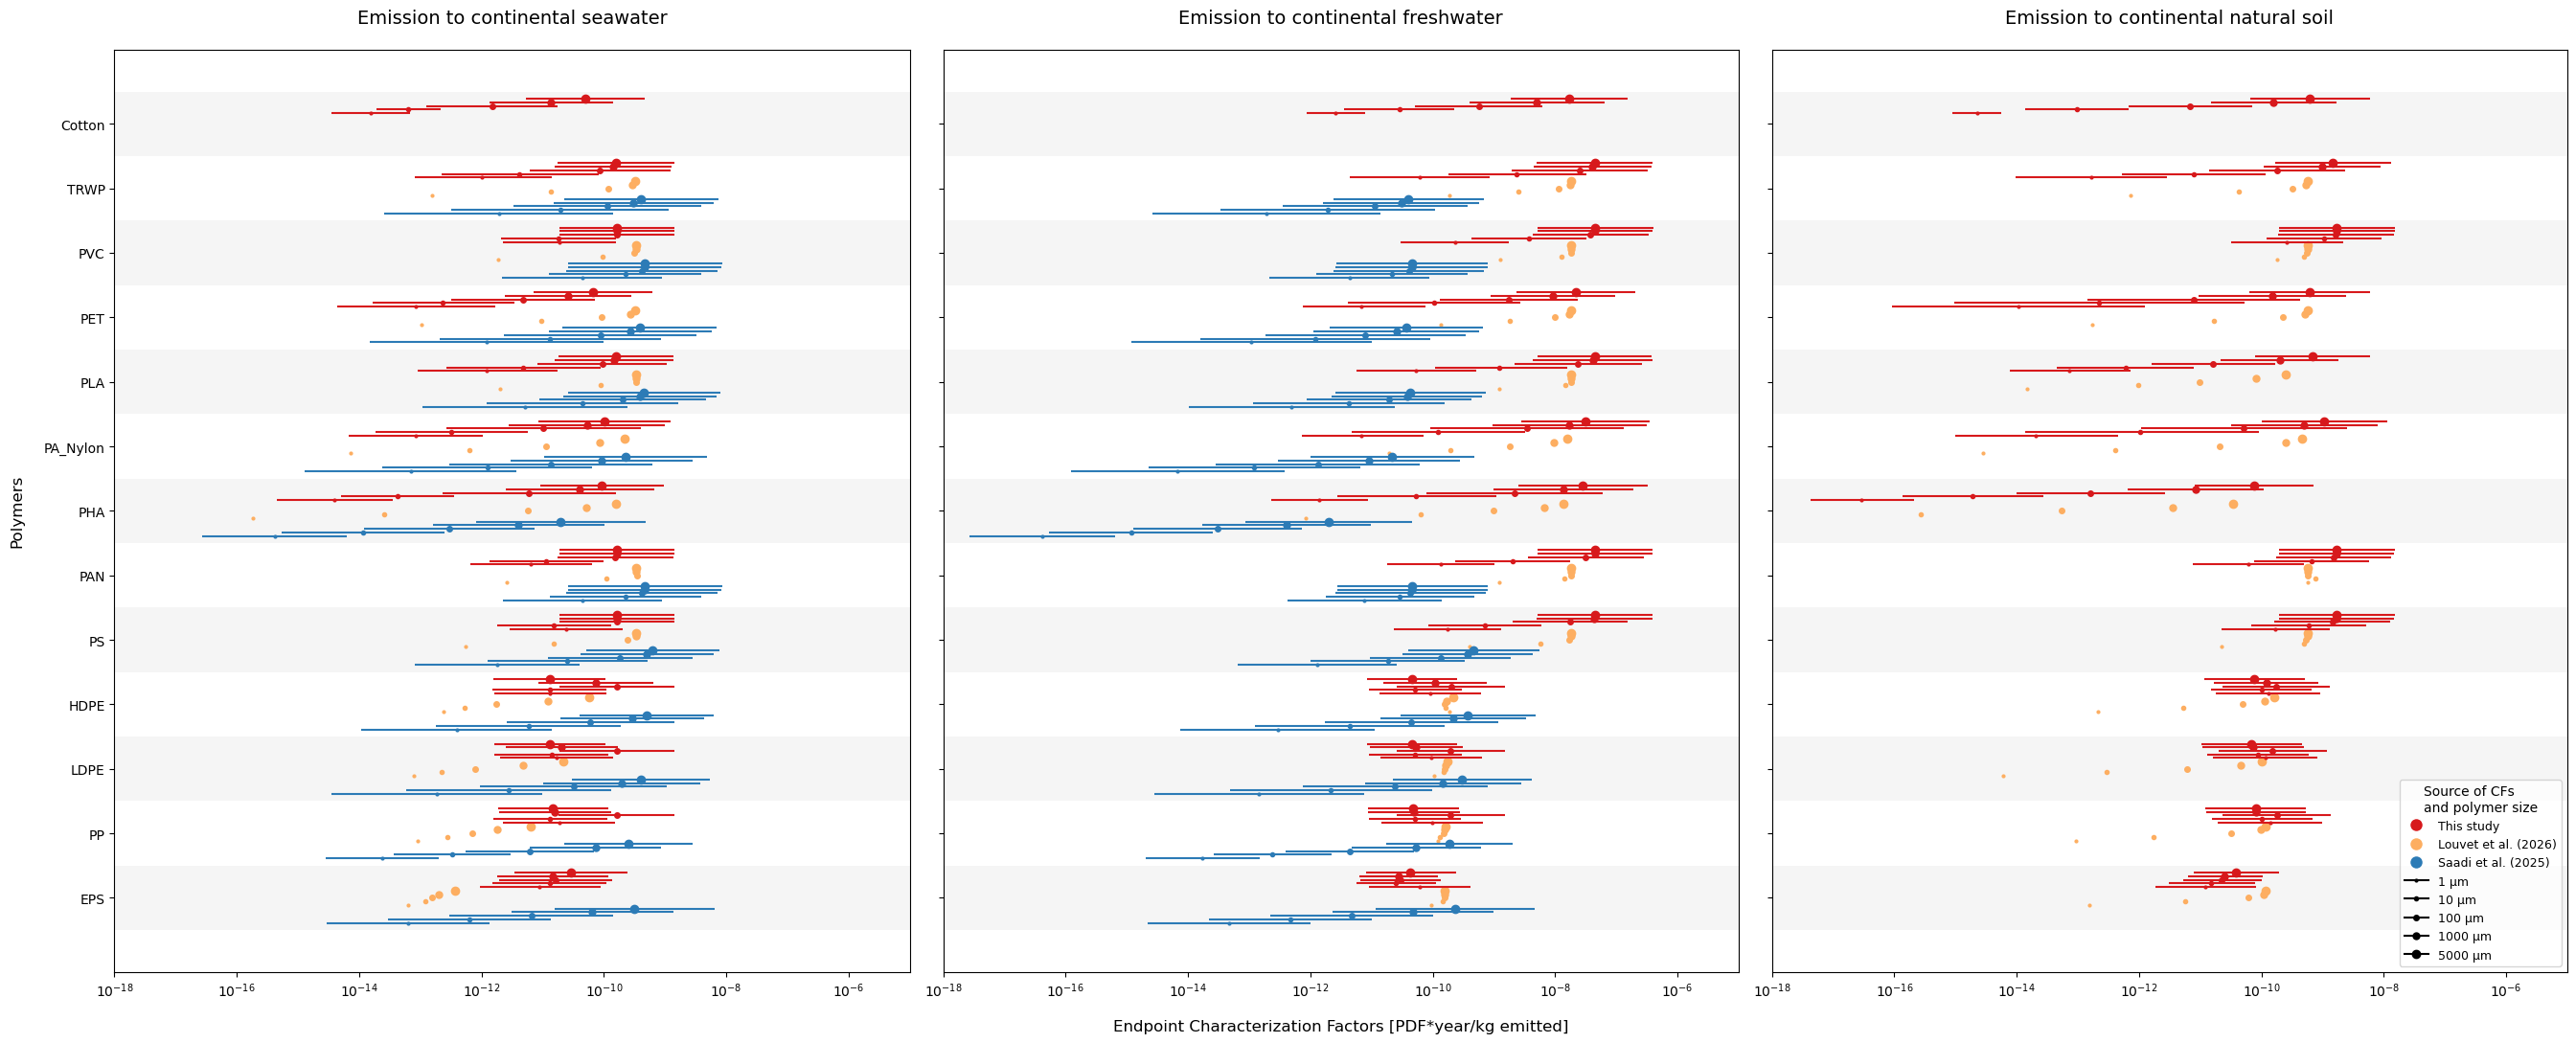

In [8]:
plot_ecosystem_comparison(df_PDF_year_Saadi_swC, df_PDF_year_New_swC, df_PDF_year_Louvet_swC, #marine df
                          df_PDF_year_Saadi_swC, df_PDF_year_New_terr, df_PDF_year_Louvet_terr, #nat soil df
                         df_PDF_year_Saadi_fwC, df_PDF_year_New_rwC, df_PDF_year_Louvet_rwC) #fw df

Regionalisation effect

CFs as a function of size and density


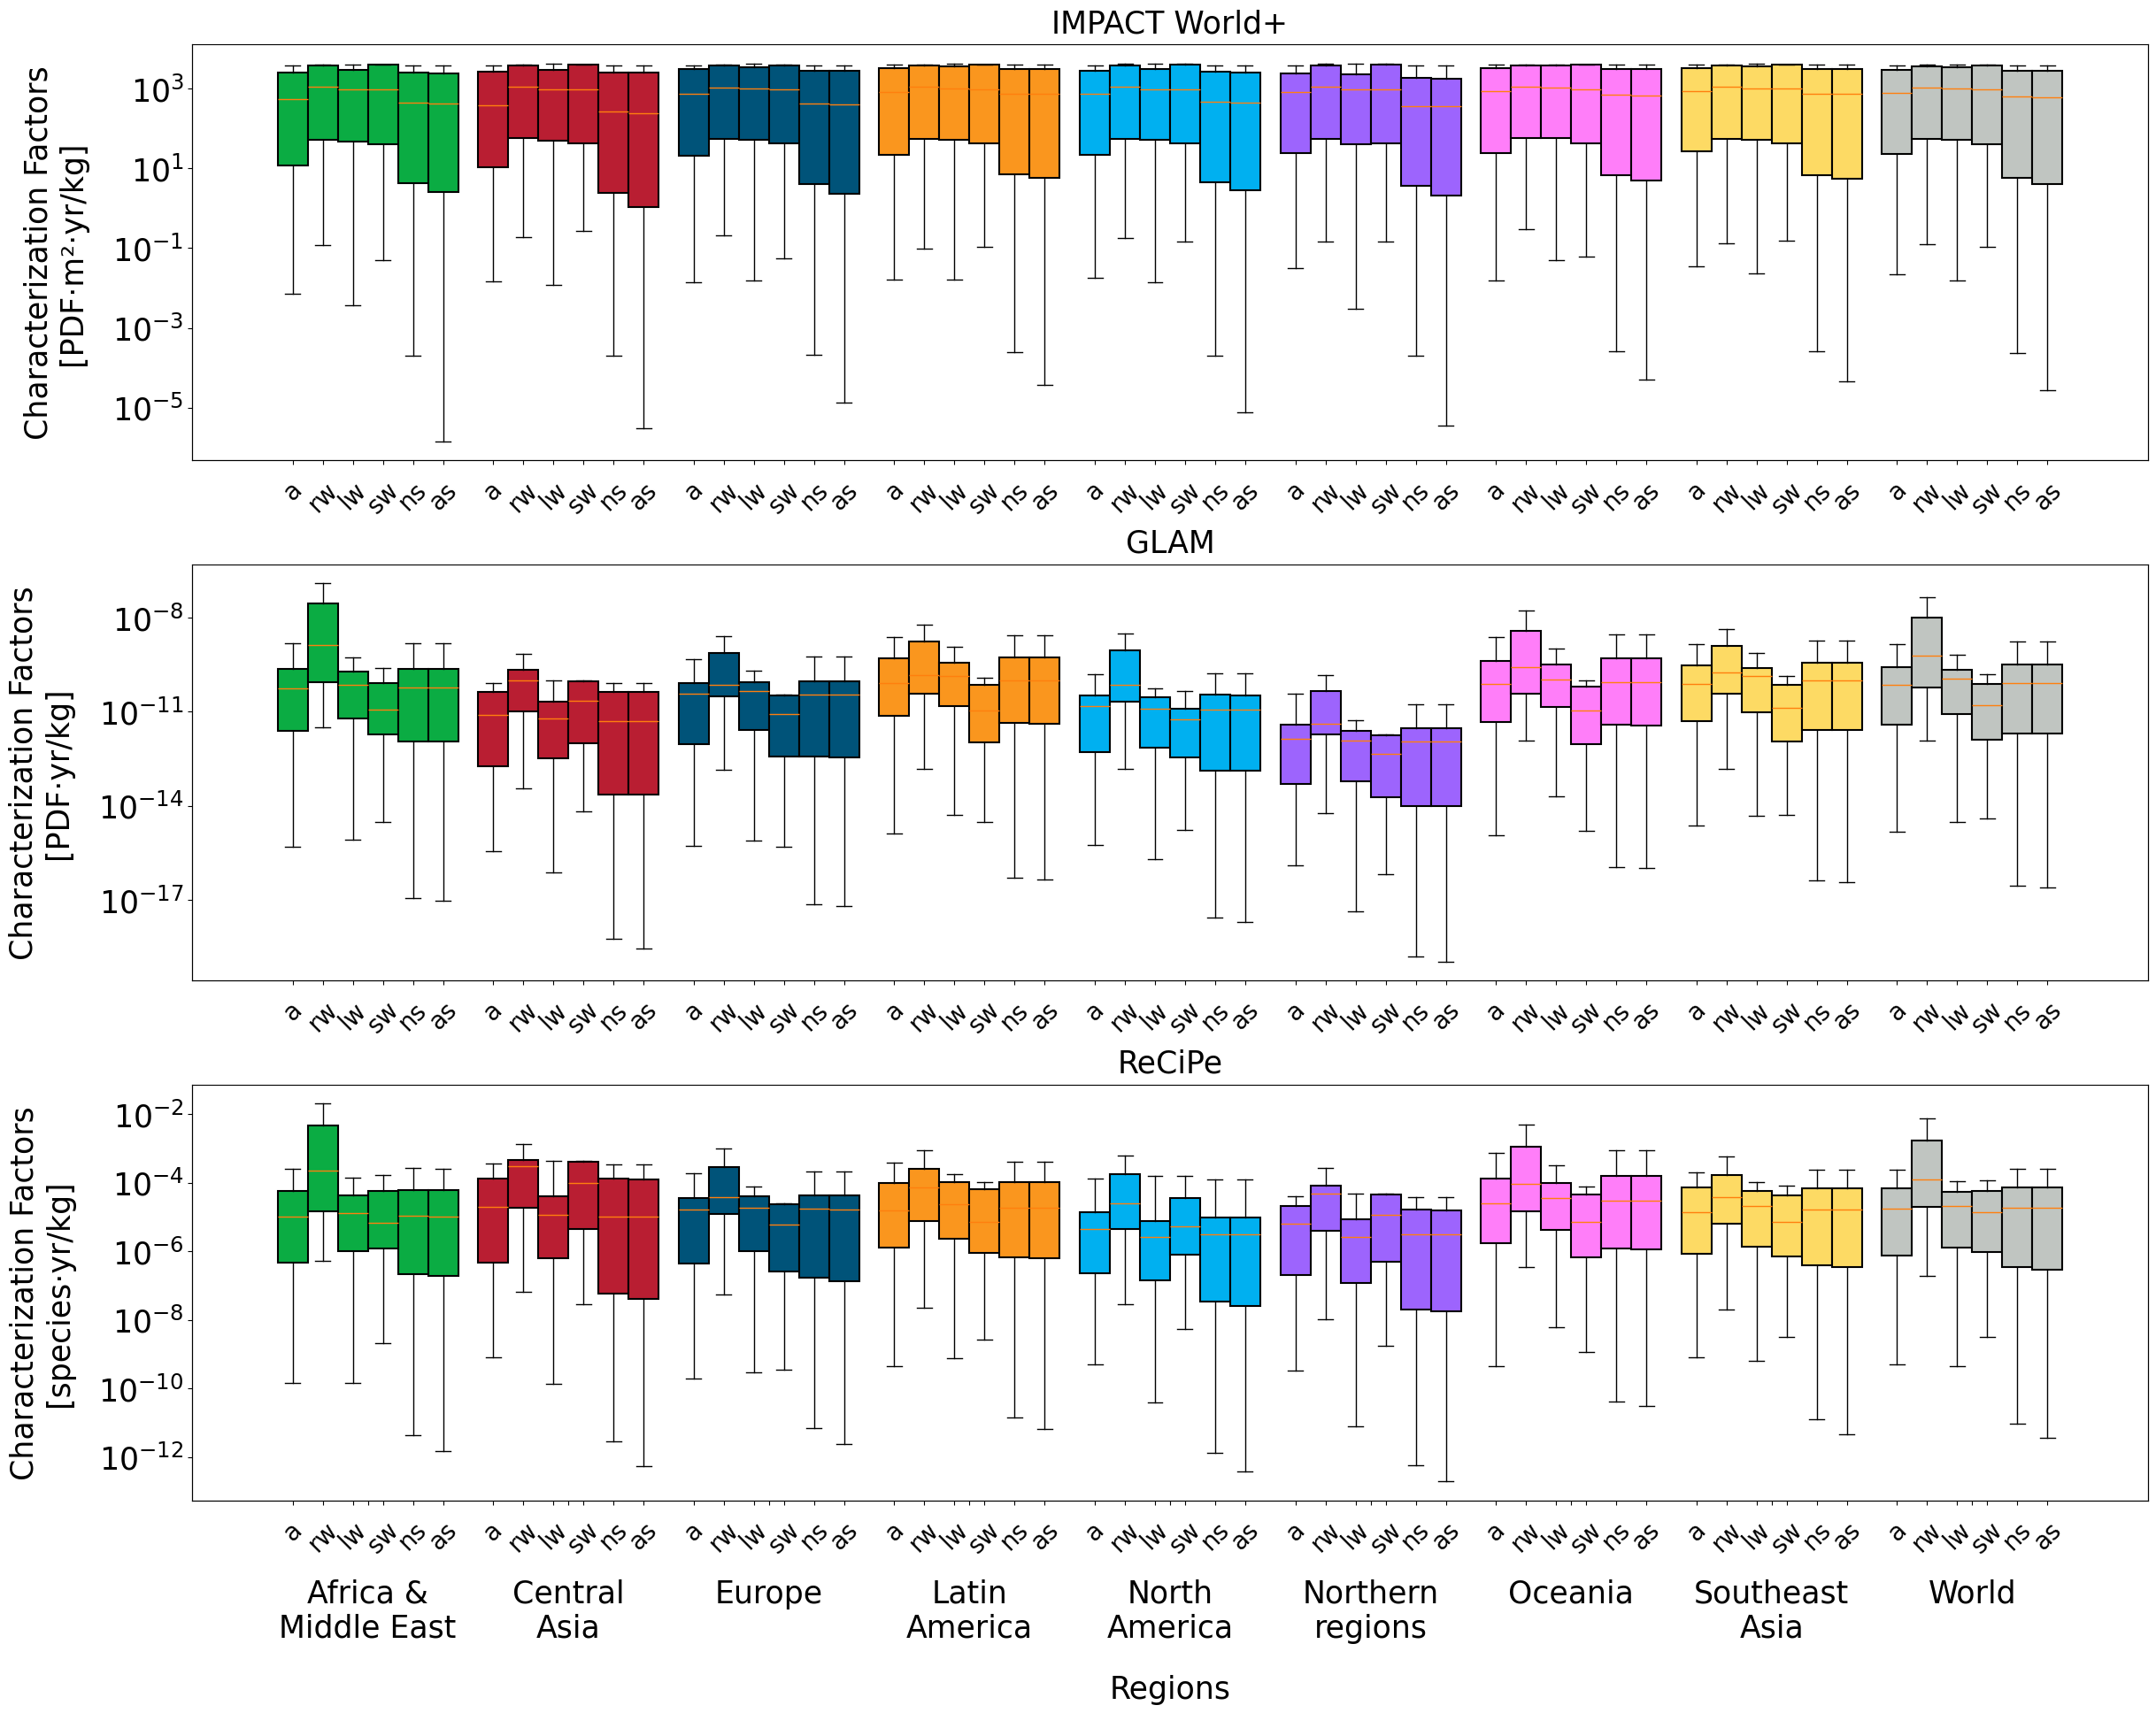

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# File paths
file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_name = "CF_end_PDF_yr"

# Load the specific sheet from the Excel file
df_orig = pd.read_excel(file_path, sheet_name=sheet_name)

CF_end_PDF_year_world_dens_added_eco_all_dens = df_orig

sheet_name = "CF_end_PDF_m2_yr"

# Load the specific sheet from the Excel file
df_orig_iw = pd.read_excel(file_path, sheet_name=sheet_name)

CF_end_PDF_m2_year_world_dens_added_eco_all_dens = df_orig_iw

sheet_name = "CF_end_species_yr"

# Load the specific sheet from the Excel file
df_orig_recipe = pd.read_excel(file_path, sheet_name=sheet_name)

CF_end_species_year_world_dens_added_eco_all_dens = df_orig_recipe


def plot_three_methods(df_glam, df_impact, df_recipe, titlefile="figures/Figure_4_combined.pdf"):
    """
    Create three vertically stacked boxplots for GLAM (PDF/yr), IMPACT World+ (PDF·m²/yr),
    and ReCiPe (species/yr) with identical styling.
    
    Parameters:
    df_glam : DataFrame for GLAM (PDF/yr) – originally CF_end_PDF_year_world_dens_added_eco_all_dens
    df_impact : DataFrame for IMPACT World+ (PDF·m²/yr) – originally CF_end_PDF_m2_year_world_dens_added_eco_all_dens
    df_recipe : DataFrame for ReCiPe (species/yr) – originally CF_end_species_year_world_dens_added_eco_all_dens
    titlefile : output file path
    """
    
    selected_compartments = [
        'continental air',
        'continental riverwater',
        'continental lakewater',
        'continental seawater surface',
        'continental natural soil',
        'continental agricultural soil'
    ]
    
    region_order = ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 
                    'North America', 'Northern regions', 'Oceania', 'Southeast Asia', 'World']
    
    compartment_order = [
        'continental air',
        'continental riverwater',
        'continental lakewater',
        'continental seawater surface',
        'continental natural soil',
        'continental agricultural soil'
    ]
    
    rename_regions = {
        'North America': 'North\nAmerica', 
        'Latin America': 'Latin\nAmerica', 
        'Europe': 'Europe', 
        'Africa & Middle East': 'Africa &\nMiddle East',
        'Central Asia': 'Central\nAsia',
        'Southeast Asia': 'Southeast\nAsia',
        'Northern regions': 'Northern\nregions', 
        'Oceania': 'Oceania', 
        'World': 'World'
    }
    
    rename_compartments = {
        'continental air': 'a',
        'continental lakewater': 'lw',
        'continental riverwater': 'rw',
        'continental seawater surface': 'sw',
        'continental natural soil': 'ns',
        'continental agricultural soil': 'as'
    }
    
    region_color_dict = {
        'North\nAmerica': '#00b0f0',
        'Latin\nAmerica': '#fa961e',
        'Europe': '#005379',
        'Africa &\nMiddle East': '#0bac43',
        'Central\nAsia': '#b91e32',
        'Southeast\nAsia': '#fdda64',
        'Northern\nregions': '#9d64fd',
        'Oceania': '#ff7ef9',
        'World': '#C0C5C1'
    }
    
    # Pre‑process each dataframe (filter compartments, rename, sort)
    def prepare_data(df):
        df_filtered = df[df['emission_compartment'].isin(selected_compartments)].copy()
        df_filtered['region'] = pd.Categorical(
            df_filtered['region'].replace(rename_regions), 
            categories=[rename_regions[reg] for reg in region_order], 
            ordered=True
        )
        df_filtered['emission_compartment'] = pd.Categorical(
            df_filtered['emission_compartment'].replace(rename_compartments),
            categories=[rename_compartments[comp] for comp in compartment_order], 
            ordered=True
        )
        df_sorted = df_filtered.sort_values(by=['region', 'emission_compartment'])
        return df_sorted
    
    df_glam_prep = prepare_data(df_glam)
    df_impact_prep = prepare_data(df_impact)
    df_recipe_prep = prepare_data(df_recipe)
    
    # Helper to create a single subplot (no region x‑ticks, no title, returns ax)
    def create_subplot(ax, df, ylabel, title=None, show_region_labels=False):
        num_regions = len(df['region'].cat.categories)
        num_compartments = len(df['emission_compartment'].cat.categories)
        
        # Group data
        grouped_data = []
        group_labels = []
        for region in df['region'].cat.categories:
            for compartment in df['emission_compartment'].cat.categories:
                subset = df[(df['region'] == region) & (df['emission_compartment'] == compartment)]
                if len(subset) > 0:
                    grouped_data.append(subset['total_geom_mean'].values)
                    group_labels.append(f"{region}_{compartment}")
        
        # Positions
        positions = []
        for region_idx in range(num_regions):
            for comp_idx in range(num_compartments):
                offset = (comp_idx - (num_compartments - 1) / 2) * 0.15
                positions.append(region_idx + offset)
        
        # Boxplot
        boxes = ax.boxplot(grouped_data, positions=positions, 
                           widths=0.15, showfliers=True, whis=1000, patch_artist=True)
        
        for i, (box, label) in enumerate(zip(boxes['boxes'], group_labels)):
            region = label.split('_')[0]
            box.set_facecolor(region_color_dict[region])
            box.set_edgecolor('black')
            box.set_linewidth(1.5)
        
        ax.set_yscale('log')
        ax.set_ylabel(ylabel, fontsize=25, labelpad=20)
        ax.tick_params(axis='y', labelsize=25)
        
        # Region x‑ticks (only on bottom subplot if requested)
        if show_region_labels:
            ax.set_xticks(range(num_regions))
            ax.set_xticklabels([rename_regions[reg] for reg in region_order], fontsize=25)
            ax.tick_params(axis='x', labelsize=25, pad=60)
            ax.set_xlabel('Regions', fontsize=25, labelpad=25)
        else:
            ax.set_xticks([])
            ax.set_xlabel('')
        
        # Second x‑axis for compartment labels (always at bottom)
        ax2 = ax.twiny()
        all_compartment_ticks = []
        all_compartment_labels = []
        compartment_labels = [rename_compartments[comp] for comp in compartment_order]
        for region_idx in range(num_regions):
            for comp_idx in range(num_compartments):
                offset = (comp_idx - (num_compartments - 1) / 2) * 0.15
                all_compartment_ticks.append(region_idx + offset)
                all_compartment_labels.append(compartment_labels[comp_idx])
        
        ax2.set_xticks(all_compartment_ticks)
        ax2.set_xticklabels(all_compartment_labels, fontsize=23, rotation=45, ha='right', va='top')
        ax2.tick_params(axis='x', labelsize=20, pad=10, rotation=45)
        ax2.xaxis.set_ticks_position('bottom')
        ax2.xaxis.set_label_position('bottom')
        ax2.spines['bottom'].set_position(('outward', 0))
        ax2.set_xlim(ax.get_xlim())
        ax2.spines['top'].set_visible(False)
        
        if title:
            ax.set_title(title, fontsize=25, pad=10)
        
        return ax
    
    # Create figure with 3 subplots
    fig, axes = plt.subplots(3, 1, figsize=(25, 20))
    
    # Top: IMPACT World+ (PDF·m²/yr)
    create_subplot(axes[0], df_impact_prep, 
                   ylabel='Characterization Factors\n[PDF·m²·yr/kg]', 
                   title='IMPACT World+', show_region_labels=False)
    
    # Middle: GLAM (PDF/yr)
    create_subplot(axes[1], df_glam_prep, 
                   ylabel='Characterization Factors\n[PDF·yr/kg]', 
                   title='GLAM', show_region_labels=False)
    
    # Bottom: ReCiPe (species/yr) – region labels only here
    create_subplot(axes[2], df_recipe_prep, 
                   ylabel='Characterization Factors\n[species·yr/kg]', 
                   title='ReCiPe', show_region_labels=True)
    
    # Adjust layout
    plt.tight_layout(pad=3.0)
    plt.subplots_adjust(hspace=0.25)  # Reduce vertical gap between subplots
    plt.savefig(titlefile, dpi=500, bbox_inches='tight', transparent=True)
    plt.show()


# ===================== USE THE FUNCTION =====================
# After loading your three dataframes as:
# df_glam = CF_end_PDF_year_world_dens_added_eco_all_dens
# df_impact = CF_end_PDF_m2_year_world_dens_added_eco_all_dens
# df_recipe = CF_end_species_year_world_dens_added_eco_all_dens

plot_three_methods(
    df_glam=CF_end_PDF_year_world_dens_added_eco_all_dens,
    df_impact=CF_end_PDF_m2_year_world_dens_added_eco_all_dens,
    df_recipe=CF_end_species_year_world_dens_added_eco_all_dens,
    titlefile="figures/Figure 4.pdf"
)

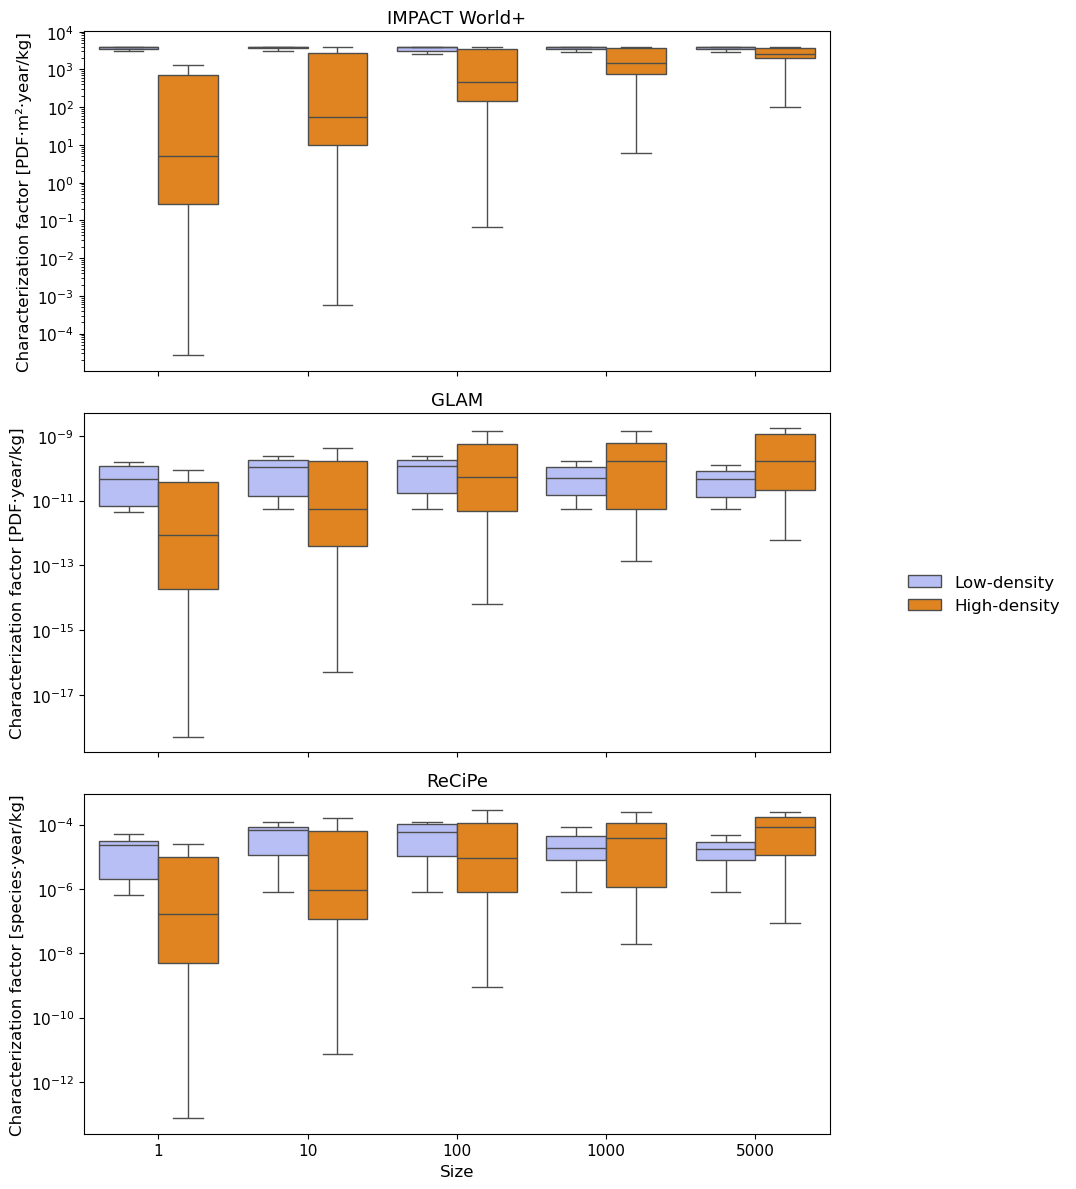

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------
# Paths and settings
# ------------------------------
file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_names = [
    "CF_end_PDF_m2_yr",
    "CF_end_PDF_yr",
    "CF_end_species_yr"
]

# Custom titles for each subplot (in the same order)
custom_titles = ["IMPACT World+", "GLAM", "ReCiPe"]

# Corresponding y‑axis labels (lowercase, with m^2)
ylabels = {
    "CF_end_PDF_m2_yr": "Characterization factor [PDF·m²·year/kg]",
    "CF_end_PDF_yr": "Characterization factor [PDF·year/kg]",
    "CF_end_species_yr": "Characterization factor [species·year/kg]"
}

# ------------------------------
# Mappings and filters
# ------------------------------
density_mapping = {
    'EPS': 'low-density',
    'PP': 'low-density',
    'LDPE': 'low-density',
    'HDPE': 'low-density',
    'PS': 'high-density',
    'PAN': 'high-density',
    'PHA': 'high-density',
    'PA': 'high-density',
    'PA_Nylon': 'high-density',
    'PLA': 'high-density',
    'starch_blend': 'high-density',
    'PBAT': 'high-density',
    'PET': 'high-density',
    'PVC': 'high-density',
    'TRWP': 'high-density',
}

size_filter = [1, 10, 100, 1000, 5000]
region_filter = "World"
polymers = [
    'EPS', 'PP', 'LDPE', 'HDPE', 'PS', 'PAN', 'PHA', 'PA_Nylon',
    'PLA', 'starch_blend', 'PBAT', 'PET', 'PVC', 'TRWP'
]

# ------------------------------
# Create vertically stacked subplots (3 rows, 1 column)
# ------------------------------
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True, sharey=False)

# Loop over sheets, axes, and titles
for ax, sheet, title in zip(axes, sheet_names, custom_titles):
    # Load sheet
    df = pd.read_excel(file_path, sheet_name=sheet)

    # Apply filters
    df_filtered = df[
        (df["size"].isin(size_filter)) &
        (df["region"] == region_filter) &
        (df["polymer"].isin(polymers))
    ].copy()

    # Keep relevant columns and rename
    df_plot = df_filtered[['polymer', 'size', 'total_geom_mean',
                           'total_ll_95', 'total_ul_95']].copy()
    df_plot.rename(columns={
        'total_geom_mean': 'CF_end',
        'total_ll_95': 'CF_end_lower',
        'total_ul_95': 'CF_end_upper',
    }, inplace=True)

    # Add density column
    df_plot['density'] = df_plot['polymer'].map(density_mapping)

    # Draw boxplot on current axis
    sns.boxplot(
        x='size', y='CF_end', data=df_plot,
        hue='density', hue_order=['low-density', 'high-density'],
        showfliers=False, order=[1, 10, 100, 1000, 5000],
        palette=['#AEB8FE', '#FF8600'], ax=ax
    )

    # Logarithmic y‑scale
    ax.set_yscale('log')

    # Labels and custom title
    ax.set_ylabel(ylabels[sheet], fontsize=12)
    ax.set_title(title, fontsize=13)   # <-- custom title applied

    # Tick label sizes
    ax.tick_params(axis='x', labelsize=11)
    ax.tick_params(axis='y', labelsize=11)

    # Remove individual legends
    ax.get_legend().remove()

# Set common x‑label for the bottom subplot only
axes[-1].set_xlabel('Size', fontsize=12)

# ------------------------------
# Global legend (outside to the right)
# ------------------------------
handles, labels = axes[0].get_legend_handles_labels()
labels = ['Low-density', 'High-density']  # nicer labels
fig.legend(handles, labels, loc='center right', bbox_to_anchor=(1.08, 0.5),
           fontsize=12, frameon=False)

# Adjust layout to leave space for the legend on the right
plt.tight_layout(rect=[0, 0, 0.85, 1])

# Save and show
plt.savefig(path_graphs + 'Figure S.10.pdf',
            dpi=1000, bbox_inches='tight', transparent=True)
plt.show()

Found 26 unique polymers in the data:
['PHA', 'starch_blend', 'Lyocell', 'Modal', 'Linen', 'Viscose', 'Rayon', 'Cotton', 'PCL', 'PBAT', 'PA_Nylon', 'PET', 'PBSA', 'PU', 'TRWP', 'PLA', 'PAN', 'default_high_density', 'EPS', 'default_all_density', 'PP', 'PS', 'default_low_density', 'LDPE', 'PVC', 'HDPE']

Found 468 rows after filtering
Unique polymers found: 26
Unique emission compartments found: ['continental natural soil' 'continental riverwater'
 'continental seawater surface']


/var/folders/dk/y_33q_hj5yqgz652xn7q13cm0000gn/T/ipykernel_89152/4002677217.py:74: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.




Creating legend with all 26 polymers


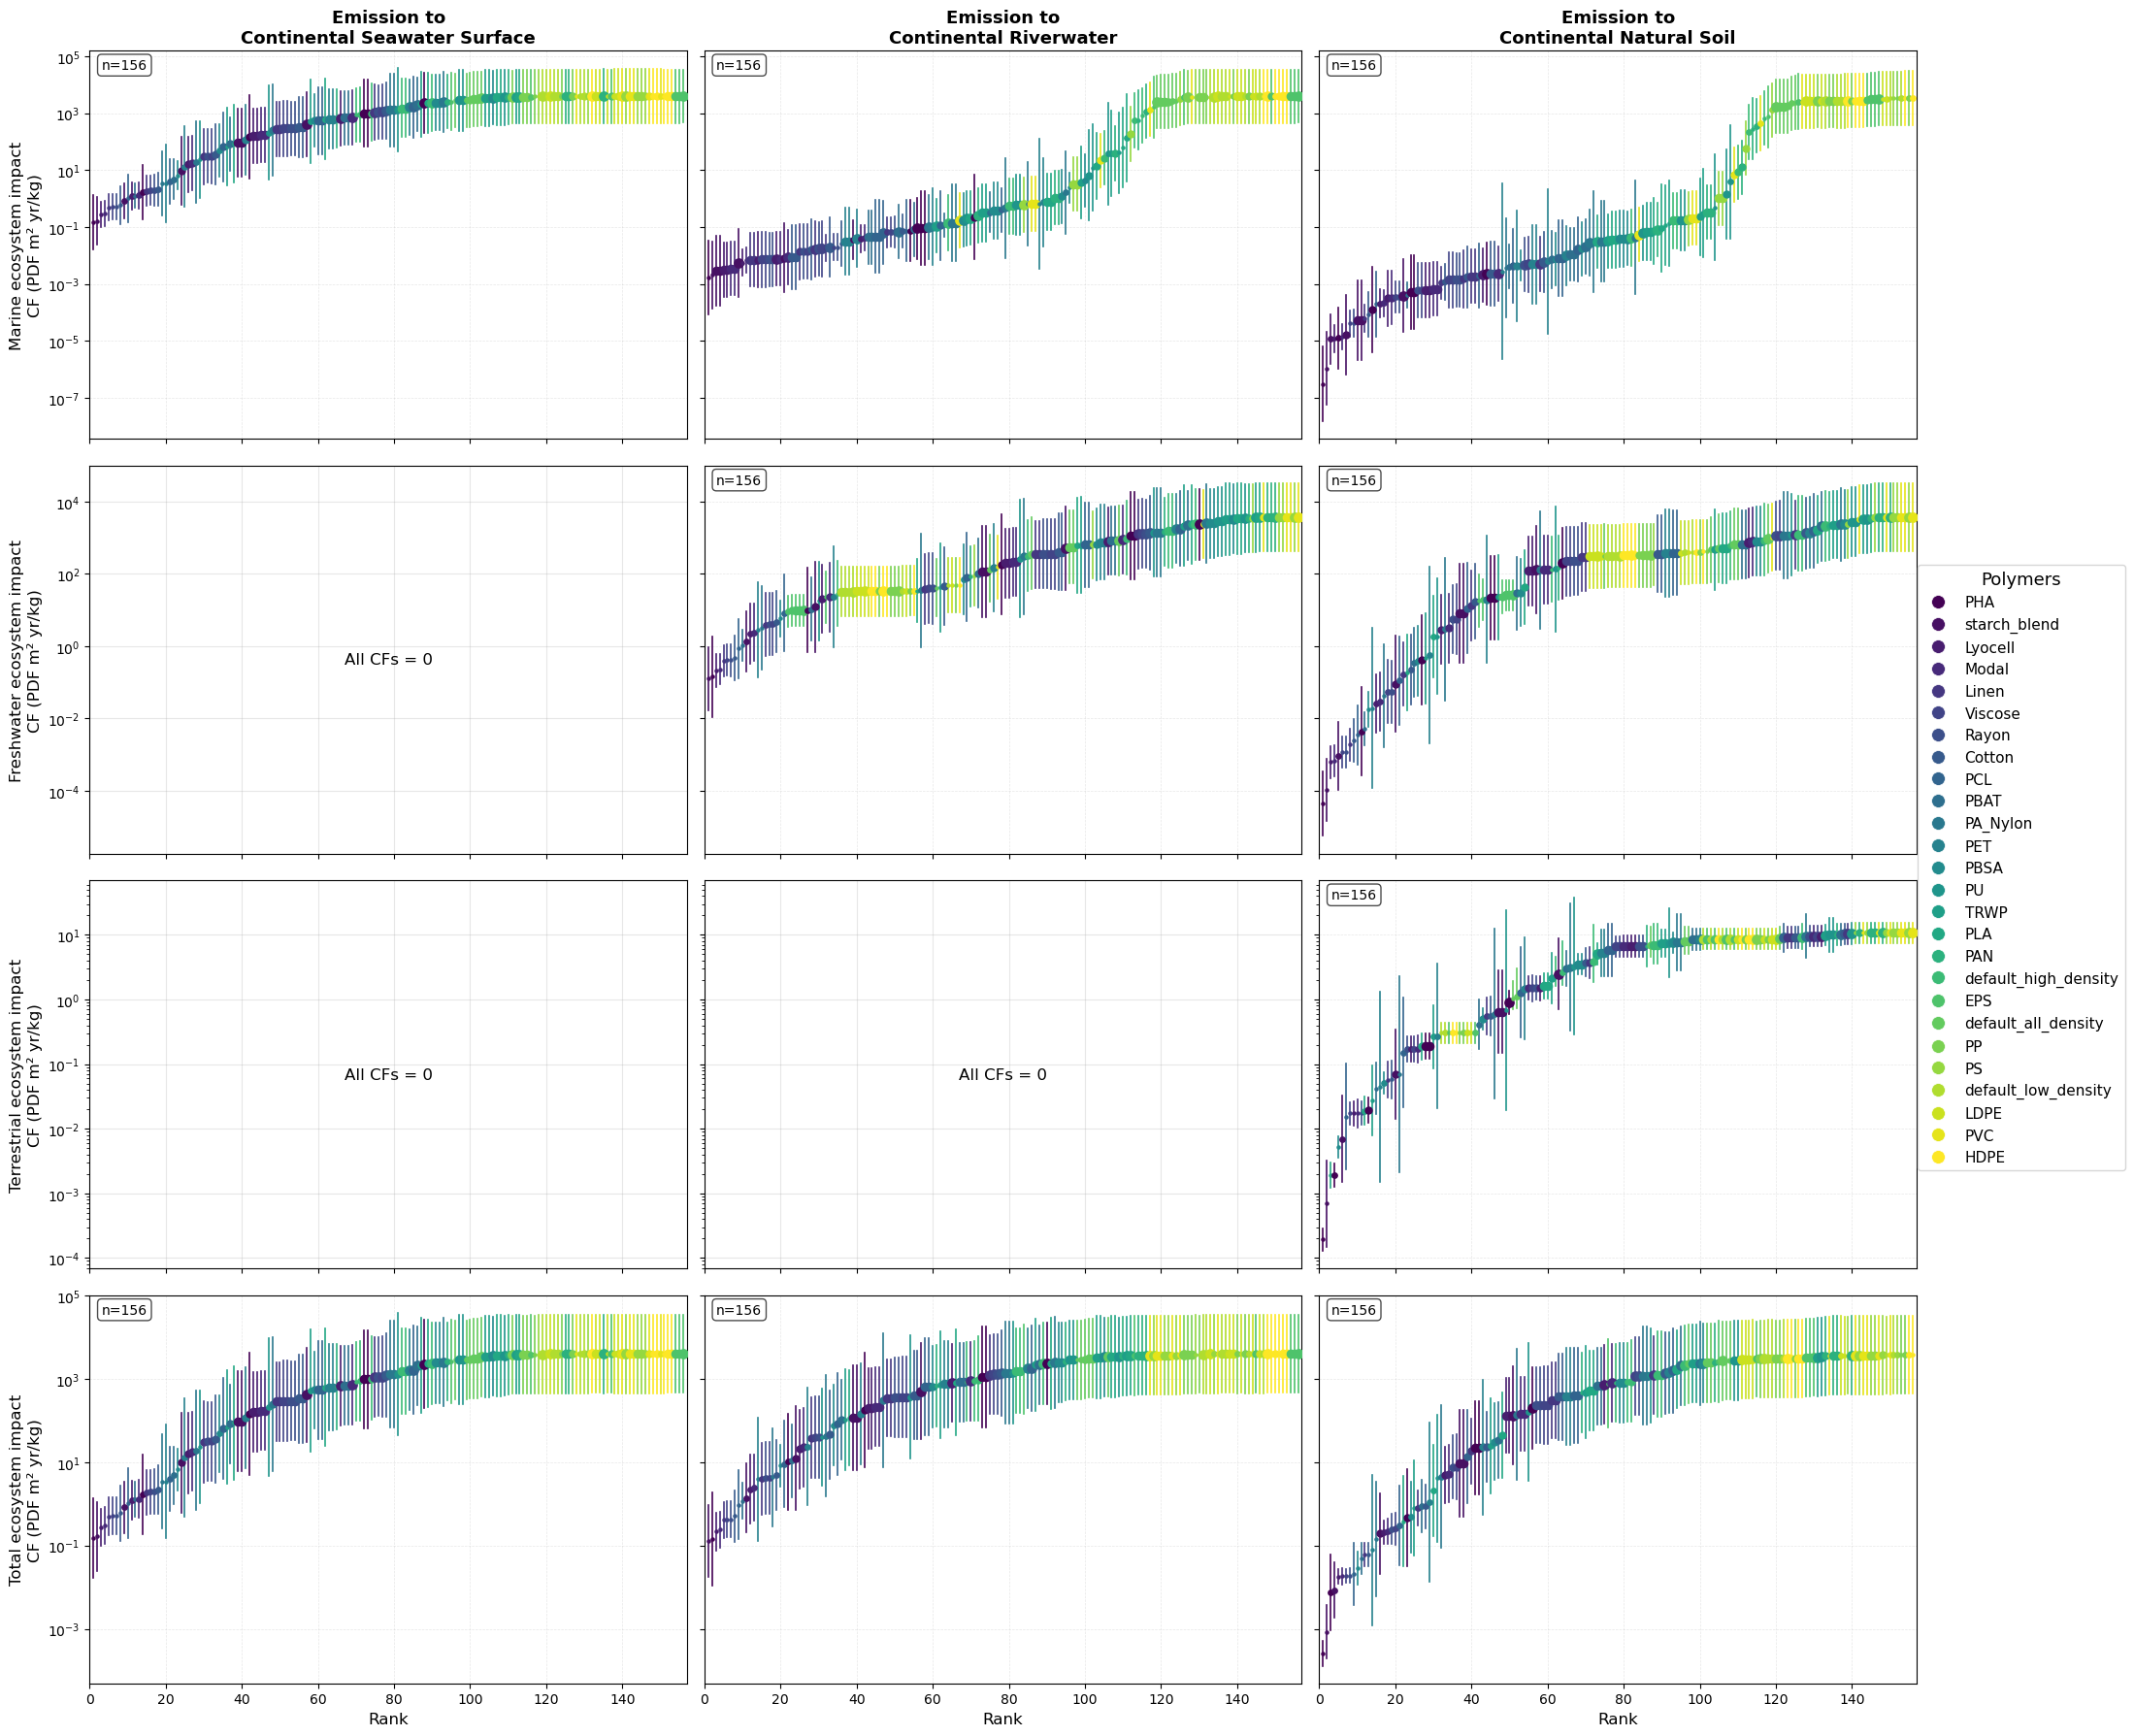

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
import os

# Read the Excel file
file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_name = "CF_end_PDF_m2_yr"

# Read the specified sheet
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "Southeast Asia"  # To be updated
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Define ecosystem impact columns - now with 4 rows
ecosystem_columns = {
    'Marine ecosystem impact': ['marine_geom_mean', 'marine_ll_95', 'marine_ul_95'],
    'Freshwater ecosystem impact': ['freshwater_geom_mean', 'freshwater_ll_95', 'freshwater_ul_95'],
    'Terrestrial ecosystem impact': ['terrestrial_geom_mean', 'terrestrial_ll_95', 'terrestrial_ul_95'],
    'Total ecosystem impact': ['total_geom_mean', 'total_ll_95', 'total_ul_95']  # New row
}

# Apply initial filters (no polymer filter)
filtered_df = df[
    (df['size'].isin(size_filter)) & 
    (df['shape'].isin(shape_filter)) &
    (df['region'] == region_filter) &
    (df['emission_compartment'].isin(emission_compartments))
].copy()

# Get all unique polymers from the filtered data
# Sort polymers by MINIMUM marine CF for continental seawater surface
seawater_data = filtered_df[filtered_df['emission_compartment'] == 'continental seawater surface']
marine_min = seawater_data.groupby('polymer')['marine_geom_mean'].min()
polymers = marine_min.sort_values().index.tolist()
print(f"Found {len(polymers)} unique polymers in the data:")
print(polymers)

# Check if we have data after filtering
if filtered_df.empty:
    print("Warning: No data found after applying filters. Check your filter conditions.")
    print("Available regions:", df['region'].unique())
    print("Available polymers:", df['polymer'].unique())
    print("Available emission compartments:", df['emission_compartment'].unique())
    print("Available sizes:", df['size'].unique())
    print("Available shapes:", df['shape'].unique())
else:
    print(f"\nFound {len(filtered_df)} rows after filtering")
    print(f"Unique polymers found: {len(polymers)}")
    print(f"Unique emission compartments found: {filtered_df['emission_compartment'].unique()}")

# Create color mapping for polymers - use full saturation colors
num_polymers = len(polymers)
if num_polymers > 0:
    # Create a colormap with fully saturated colors
    if num_polymers <= 20:
        # Get colors from tab20 but ensure they're fully saturated
        cmap = cm.get_cmap('tab20')
        # Generate colors with full alpha (opacity)
        colors = [cmap(i % 20) for i in range(num_polymers)]
        # Set alpha to 1.0 for full saturation
        colors = [(r, g, b, 1.0) for r, g, b, a in colors]
    else:
        # For more than 20 polymers, use viridis
        cmap = cm.get_cmap('viridis')
        colors = [cmap(i / max(1, num_polymers-1)) for i in range(num_polymers)]
        colors = [(r, g, b, 1.0) for r, g, b, a in colors]
    
    polymer_colors = dict(zip(polymers, colors))
else:
    polymer_colors = {}
    print("Warning: No polymers found in filtered data!")

# Create marker size mapping for particle sizes
# Sizes: 1, 10, 100, 1000, 5000 um
# Using smaller markers overall since there are many points (115 per graph)
size_marker_map = {
    1: 5,      # Smallest size - smallest marker
    10: 15,      # Slightly larger
    100: 25,     # Medium
    1000: 35,    # Large
    5000: 45     # Largest size - largest marker
}

# Create the figure with 12 subplots (4 rows x 3 columns)
fig, axes = plt.subplots(4, 3, figsize=(22, 20), sharey='row', sharex=True)

# Create more descriptive titles for emission compartments with "Emission to"
emission_titles = {
    "continental seawater surface": "Emission to\nContinental Seawater Surface",
    "continental riverwater": "Emission to\nContinental Riverwater", 
    "continental natural soil": "Emission to\nContinental Natural Soil"
}

# Define plot settings with adjusted sizes
ERROR_BAR_WIDTH = 1.2  # Slightly increased thickness

# Store which axes have data for setting y-labels
has_data_for_row = {0: False, 1: False, 2: False, 3: False}

# Iterate through each ecosystem (rows) and emission compartment (columns)
for row_idx, (ecosystem_name, cf_columns) in enumerate(ecosystem_columns.items()):
    for col_idx, emission_compartment in enumerate(emission_compartments):
        ax = axes[row_idx, col_idx]
        
        # Filter data for this specific subplot
        subplot_data = filtered_df[
            (filtered_df['emission_compartment'] == emission_compartment)
        ].copy()
        
        if subplot_data.empty:
            ax.text(0.5, 0.5, 'No data available', 
                   horizontalalignment='center', verticalalignment='center',
                   transform=ax.transAxes, fontsize=12)
            ax.grid(True, alpha=0.3)
            continue
        
        # Get the relevant columns
        geom_col, ll_col, ul_col = cf_columns
        
        # Check if columns exist
        missing_cols = []
        for col in [geom_col, ll_col, ul_col]:
            if col not in subplot_data.columns:
                missing_cols.append(col)
        
        if missing_cols:
            ax.text(0.5, 0.5, f'Missing columns:\n{", ".join(missing_cols)}', 
                   horizontalalignment='center', verticalalignment='center',
                   transform=ax.transAxes, fontsize=10, color='red')
            ax.grid(True, alpha=0.3)
            continue
        
        # Replace NaN values with a very small positive number for log scale
        # This handles the case where impact is 0
        for col in [geom_col, ll_col, ul_col]:
            subplot_data[col] = subplot_data[col].fillna(1e-30)
            # Ensure no negative values for log scale
            subplot_data[col] = np.where(subplot_data[col] <= 0, 1e-30, subplot_data[col])
        
        # Sort by geometric mean for ranking
        subplot_data = subplot_data.sort_values(by=geom_col, ascending=True)
        
        # Reset index for ranking
        subplot_data = subplot_data.reset_index(drop=True)
        subplot_data['rank'] = subplot_data.index + 1
        
        # Check if all values are effectively 0
        valid_values = subplot_data[geom_col][subplot_data[geom_col] > 1e-10]
        if len(valid_values) == 0:
            ax.text(0.5, 0.5, 'All CFs = 0', 
                   horizontalalignment='center', verticalalignment='center',
                   transform=ax.transAxes, fontsize=12)
            ax.grid(True, alpha=0.3)
            continue
        
        # Mark that this row has at least one plot with data
        has_data_for_row[row_idx] = True
        
        # Plot each polymer with its corresponding color and size based on particle size
        for idx, row in subplot_data.iterrows():
            polymer_name = row['polymer']
            particle_size = row['size']
            color = polymer_colors.get(polymer_name, 'gray')
            
            # Get marker size based on particle size
            marker_size = size_marker_map.get(particle_size, 20)  # Default to 20 if size not in map
            
            # Plot the geometric mean point with size varying by particle size
            ax.scatter(row['rank'], row[geom_col], color=color, s=marker_size, alpha=1.0, zorder=5)
            
            # Plot the uncertainty bars with slightly increased thickness
            lower_bound = min(row[ll_col], row[ul_col])
            upper_bound = max(row[ll_col], row[ul_col])
            
            # Only plot if there's meaningful uncertainty
            if upper_bound > lower_bound * 1.01:  # At least 1% difference
                ax.plot([row['rank'], row['rank']], 
                       [lower_bound, upper_bound], 
                       color=color, alpha=1.0, linewidth=ERROR_BAR_WIDTH, zorder=4)
        
        # Set y-axis to log scale
        ax.set_yscale('log')
        
        # Set labels
        if row_idx == 3:  # Bottom row (4th row for total)
            ax.set_xlabel('Rank', fontsize=12)
        
        # Set titles - only for first row
        if row_idx == 0:
            ax.set_title(emission_titles.get(emission_compartment, emission_compartment), 
                        fontsize=13, fontweight='bold')
        
        ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
        
        # Adjust x-axis limits
        if len(subplot_data) > 0:
            ax.set_xlim(0, len(subplot_data) + 1)
        
        # Add number of data points as text
        non_zero_count = len(valid_values)
        total_count = len(subplot_data)
        
        if non_zero_count == total_count:
            count_text = f'n={total_count}'
        else:
            count_text = f'n={non_zero_count}/{total_count}'
            
        ax.text(0.02, 0.98, count_text, 
                transform=ax.transAxes, fontsize=10, 
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# Now set y-labels for all rows that have data
for row_idx, (ecosystem_name, _) in enumerate(ecosystem_columns.items()):
    if has_data_for_row.get(row_idx, False):
        # Add y-label to the first column of this row
        axes[row_idx, 0].set_ylabel(f'{ecosystem_name}\nCF (PDF m² yr/kg)', fontsize=12)

# Adjust layout to prevent overlap
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# Create a custom legend for polymers - show ALL polymers
if polymer_colors and len(polymers) > 0:
    # Create legend with ALL polymer names
    legend_elements = []
    for polymer in polymers:
        if polymer in polymer_colors:
            legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                         label=polymer, 
                                         markerfacecolor=polymer_colors[polymer], 
                                         markersize=10,  # Increased marker size in legend
                                         markeredgewidth=0.5))
    
    print(f"\nCreating legend with all {len(polymers)} polymers")
    
    # Calculate optimal number of columns for legend
    # More polymers need more columns
    ncol=1
    
    # Create a separate figure for the legend if there are too many polymers
    if len(polymers) > 30:
        print(f"Note: Creating separate legend figure due to large number of polymers ({len(polymers)})")
        
        # Create a standalone legend figure
        legend_fig = plt.figure(figsize=(10, 0.5 * len(polymers) // ncol))
        ax_legend = legend_fig.add_subplot(111)
        ax_legend.axis('off')
        
        # Create legend
        legend = ax_legend.legend(handles=legend_elements, loc='center', 
                                 fontsize=10, title='Polymers', title_fontsize=12,
                                 ncol=ncol, frameon=True)
        
        # Save legend separately
        legend_path = os.path.join(path_graphs, 'CF_polymer_legend.png')
        legend_fig.savefig(legend_path, dpi=300, bbox_inches='tight')
        print(f"Legend saved to: {legend_path}")
        
        # Add a simplified legend to the main figure (first 10 polymers)
        if len(legend_elements) > 10:
            simplified_elements = legend_elements[:10]
            simplified_elements.append(Line2D([0], [0], marker='o', color='w',
                                            label=f'... +{len(polymers)-10} more',
                                            markerfacecolor='gray', markersize=10))
            
            fig.legend(handles=simplified_elements, loc='center right', 
                      fontsize=10, title='Polymers (first 10)', title_fontsize=11,
                      bbox_to_anchor=(1.01, 0.5))
        else:
            fig.legend(handles=legend_elements, loc='center right', 
                      fontsize=10, title='Polymers', title_fontsize=11,
                      bbox_to_anchor=(1.01, 0.5), ncol=1)
    else:
        # Add legend to the main figure
        fig.legend(handles=legend_elements, loc='center right', 
                  fontsize=11, title='Polymers', title_fontsize=13,  # Increased fontsize
                  bbox_to_anchor=(1.001, 0.5), ncol=ncol)

# Add a small legend for particle sizes (optional - can be removed if not needed)
size_legend_elements = []
for size, marker_size in size_marker_map.items():
    size_legend_elements.append(Line2D([0], [0], marker='o', color='w',
                                      label=f'{size} μm',
                                      markerfacecolor='gray',
                                      markersize=marker_size/3))  # Scale down for legend

# Add size legend in a corner (optional - comment out if not wanted)
# fig.legend(handles=size_legend_elements, loc='lower right', 
#           fontsize=9, title='Particle Size', title_fontsize=10,
#           bbox_to_anchor=(0.98, 0.02), ncol=1)

# Adjust figure to make room for legend
plt.subplots_adjust(right=0.90)

# Save the figure
output_path = os.path.join(path_graphs, 'Figure S.9.pdf')
plt.savefig(output_path, dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


Polymers ordered by total FF (highest to lowest):
['PP', 'HDPE', 'PS', 'PVC', 'LDPE', 'EPS', 'PAN', 'TRWP', 'PLA', 'PU', 'PBSA', 'PA_Nylon', 'PBAT', 'PHA', 'PET', 'PCL', 'Cotton', 'Linen', 'Rayon', 'Viscose', 'Modal', 'Lyocell', 'starch_blend']


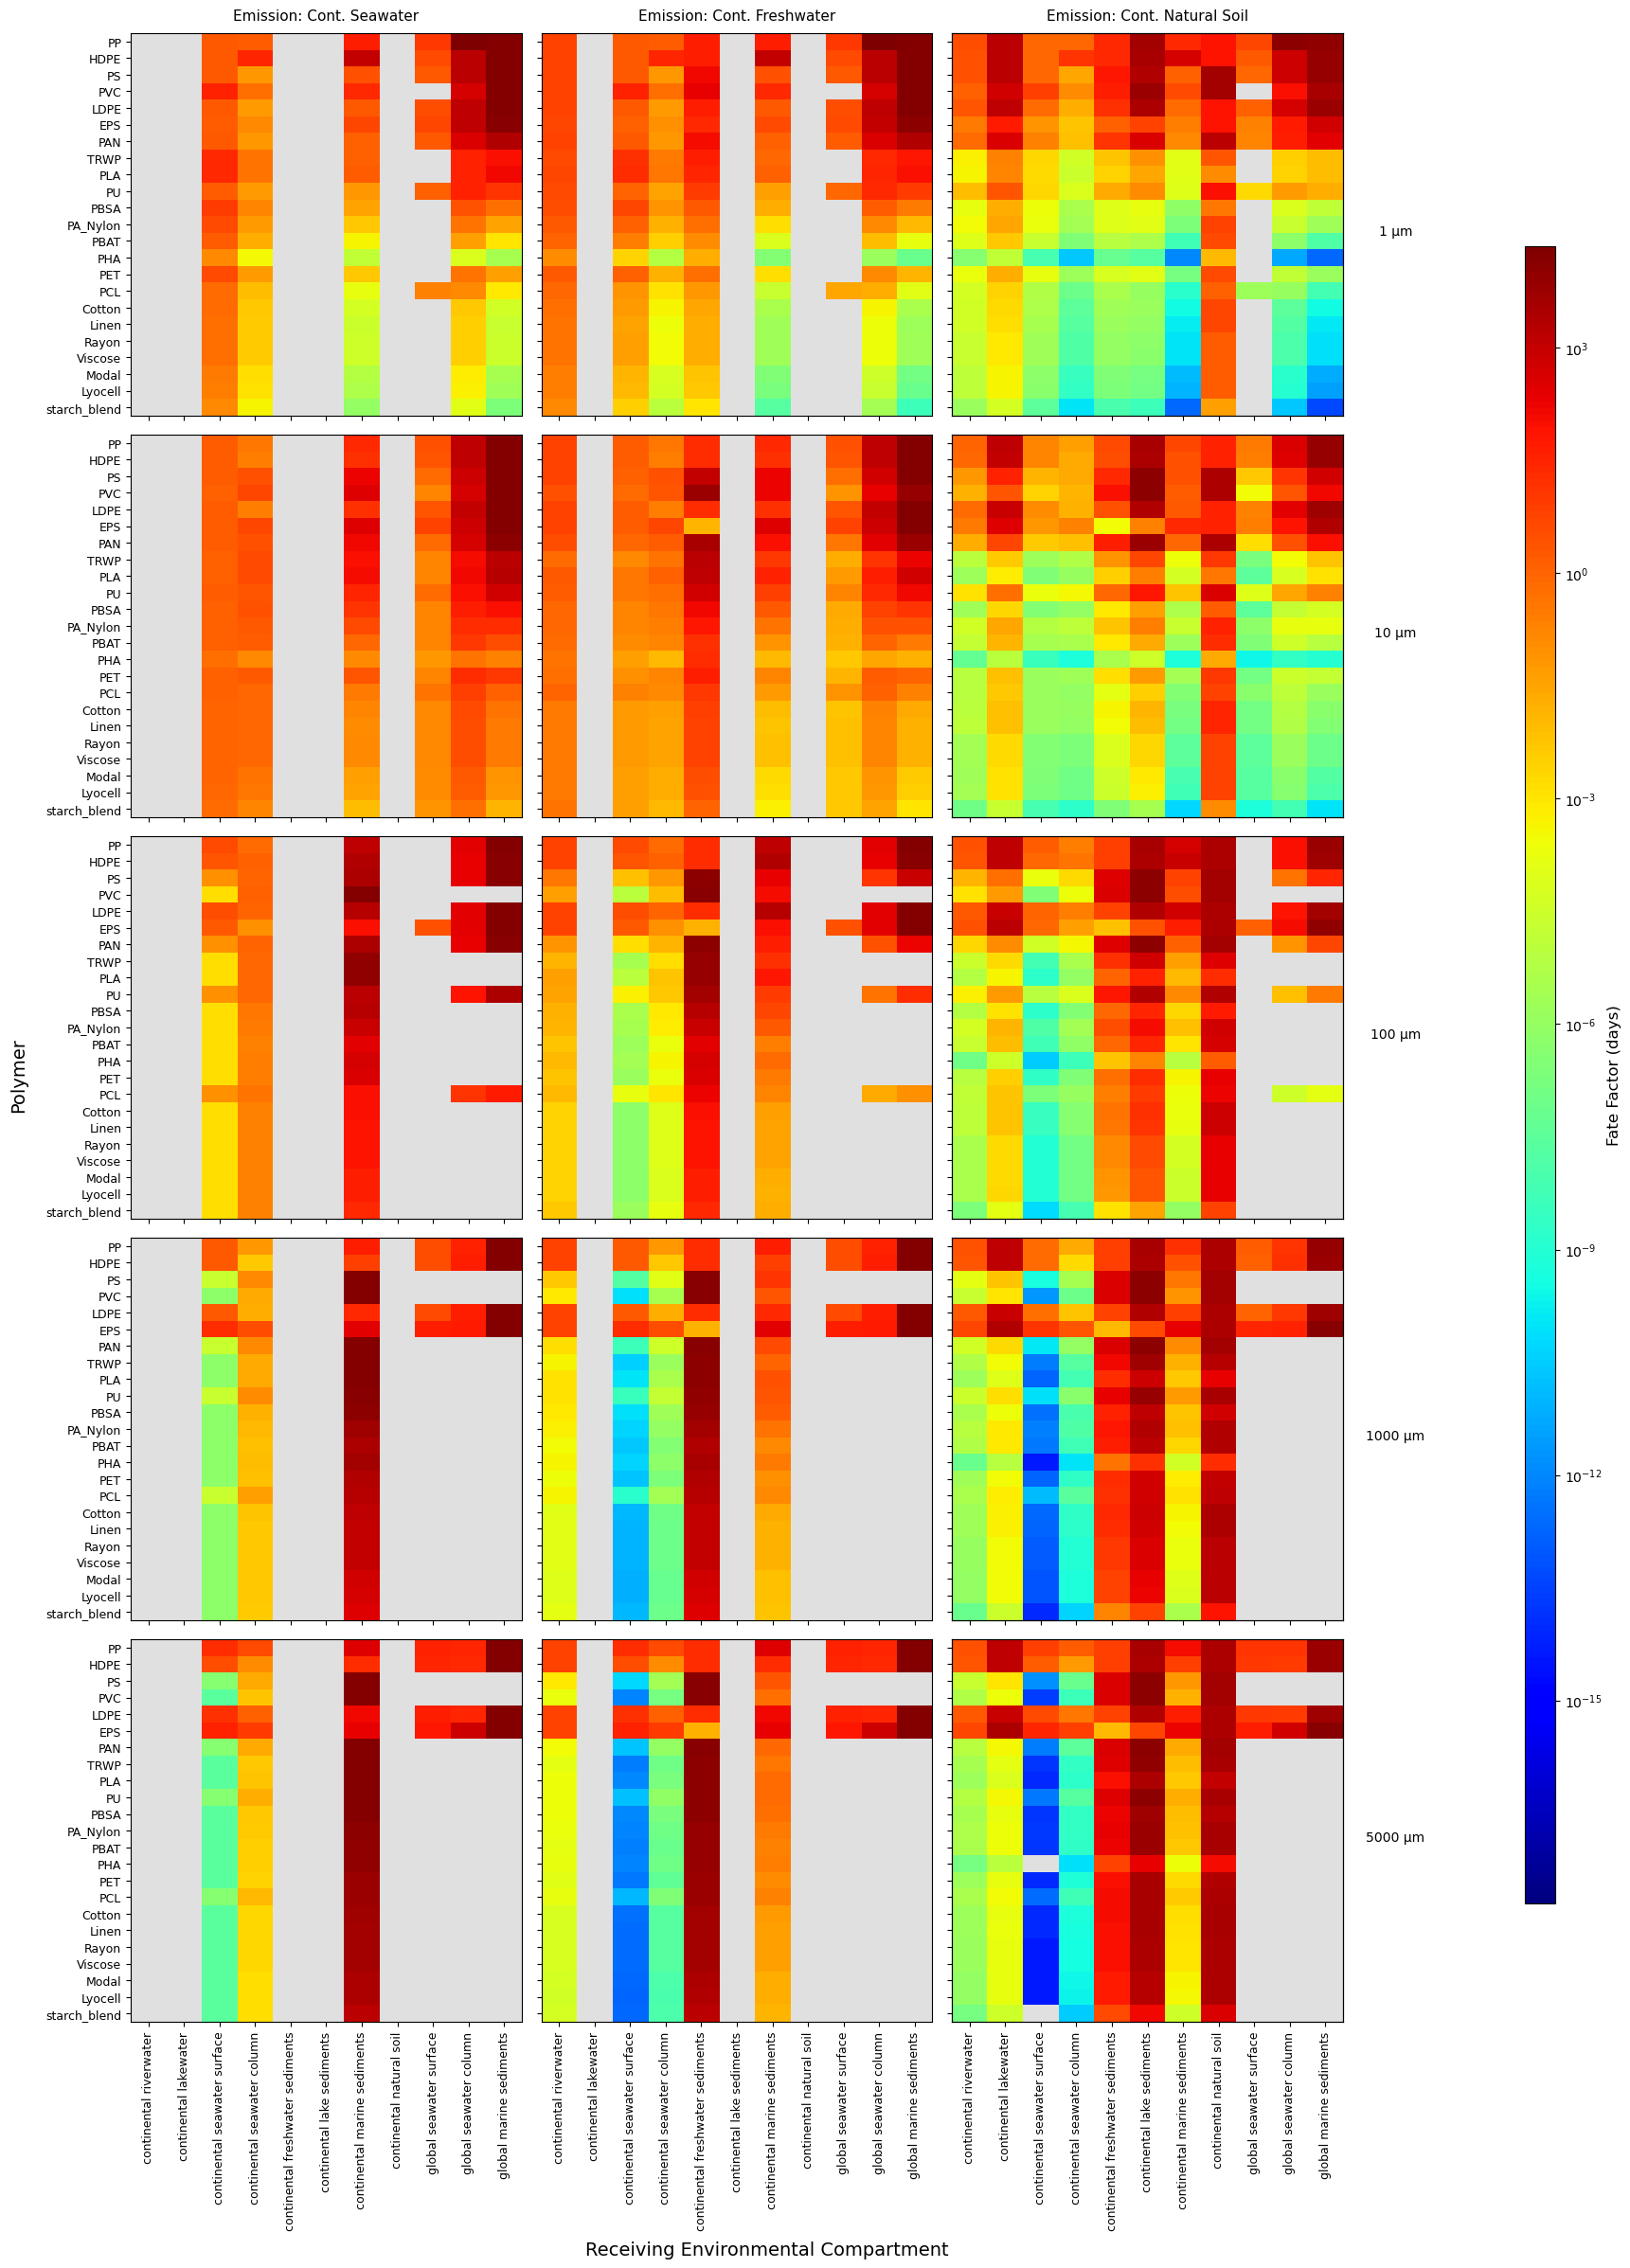

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.colors import LogNorm
import numpy.ma as ma  # Add this line!


# Load and filter data
file_path = 'results/SI_C.xlsx'
df = pd.read_excel(file_path, sheet_name='FF_d')

# Filter for North America, Spheres, and your 5 sizes
df_filtered = df[
    (df['region'] == 'North America') & 
    (df['shape'] == 'Sphere') & 
    (df['size'].isin([1, 10, 100, 1000, 5000]))
].copy()

valid_values = df_filtered['ff_geom_mean'].replace(0, np.nan).dropna()

if not valid_values.empty:
    vmin = valid_values.min() * 0.95  # Slight padding
    vmax = valid_values.max() * 1.05

# Define your compartments in the exact order you want them displayed
emission_comps = ['continental seawater surface', 'continental riverwater', 'continental natural soil']
receiving_comps = [
    "continental riverwater", "continental lakewater", "continental seawater surface",
    "continental seawater column", "continental freshwater sediments", "continental lake sediments",
    "continental marine sediments", "continental natural soil", 
    "global seawater surface", "global seawater column", "global marine sediments"
]
sizes = [1, 10, 100, 1000, 5000]

# Get polymers in a meaningful order (alphabetical or grouped by type)
#polymers = sorted(df_filtered['polymer'].unique())
# If you have polymer categories, consider manual ordering:
# polymers = ['PE', 'PP', 'PS', 'PVC', 'PET', ...] # Group by polymer type



# Calculate total FF for each polymer (sum across all conditions)
# You might want to weight this calculation appropriately
polymer_sums = df_filtered.groupby('polymer')['ff_geom_mean'].sum().sort_values(ascending=False)
polymers = polymer_sums.index.tolist()
print("Polymers ordered by total FF (highest to lowest):")
print(polymers)

# Or calculate average instead of sum 
#polymer_means = df_filtered.groupby('polymer')['ff_geom_mean'].mean().sort_values(ascending=False)
#polymers = polymer_means.index.tolist()


# Create the figure structure
fig, axes = plt.subplots(
    nrows=len(sizes), 
    ncols=len(emission_comps), 
    figsize=(16, 25),  # Adjust based on your needs
    sharex=True, 
    sharey=True,
    constrained_layout=False  # Better spacing
)

plt.subplots_adjust(left=0.08, right=0.88, top=0.94, bottom=0.10, 
                    wspace=0.05, hspace=0.05)

# Determine global min/max for consistent color scaling across all subplots
# Use log10 of geometric mean, handling zeros/negatives if any
vals = df_filtered['ff_geom_mean'].replace(0, np.nan).dropna()
vmin_log = np.log10(vals.min() * 0.95)  # Slight padding
vmax_log = np.log10(vals.max() * 1.05)

# Create heatmaps
for row_idx, size in enumerate(sizes):
    for col_idx, em_comp in enumerate(emission_comps):
        ax = axes[row_idx, col_idx]
        
        # Filter for this specific combination
        subset = df_filtered[
            (df_filtered['size'] == size) & 
            (df_filtered['emission_compartment'] == em_comp)
        ]
        
        # Pivot to matrix: polymers × receiving compartments
        pivot_data = subset.pivot_table(
            index='polymer',
            columns='receiving_compartment',
            values='ff_geom_mean',
            aggfunc='first'  # Should be unique per combination
        )
        
        # Reindex to ensure consistent ordering
        pivot_data = pivot_data.reindex(index=polymers, columns=receiving_comps)
        
        # Create heatmap with log normalization
        #im = ax.imshow(
        #    pivot_data.values,
        #    cmap='jet',
        #    norm=LogNorm(vmin=vals.min(), vmax=vals.max()),  # Critical for log scale
        #    aspect='auto'
        #)


         # ===== MASKED ARRAY APPROACH =====
        # Convert to array and mask NaN values
        #data_array = pivot_data.values
        masked_data = ma.masked_invalid(pivot_data.values)
        
        # Create colormap with 'bad' color for masked values
        cmap = plt.cm.jet.copy()
        cmap.set_bad('lightgray', alpha=0.7)  # Light gray for empty cells
        
        # Create heatmap with masked data
        im = ax.imshow(masked_data, 
                       cmap=cmap,
                       norm=LogNorm(vmin=vmin, vmax=vmax), 
                       aspect='auto')
        # ===== END MASKED ARRAY =====
        
        # Add size label on the right of last column only
        if col_idx == len(emission_comps) - 1:
            # Create a twin axis on the right for size labels
            ax_right = ax.twinx()
            ax_right.set_ylabel(f'{size} µm', fontsize=10, rotation=0, labelpad=40)
            ax_right.set_yticks([])
            ax_right.set_ylim(ax.get_ylim())
        
        # Set x-axis labels only for bottom row
        if row_idx == len(sizes) - 1:
            ax.set_xticks(range(len(receiving_comps)))
            ax.set_xticklabels(receiving_comps, rotation=90, fontsize=9, ha='center')
        else:
            ax.set_xticks([])
        
        # Set y-axis labels only for first column
        y_positions = np.arange(len(polymers))
        ax.set_yticks(y_positions)
        if col_idx == 0:
            #ax.set_yticks(range(len(polymers)))
            ax.set_yticklabels(polymers, fontsize=9, rotation=0, ha='right')
        #else:
        #    ax.set_yticks([])
        
        # Add emission compartment titles only on top row
        if row_idx == 0:
            # Shorten titles if needed
            title_map = {
                'continental seawater surface': 'Emission: Cont. Seawater',
                'continental riverwater': 'Emission: Cont. Freshwater',
                'continental natural soil': 'Emission: Cont. Natural Soil'
            }
            ax.set_title(title_map[em_comp], fontsize=11, pad=10)

# Add a main colorbar
cbar_ax = fig.add_axes([1, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Fate Factor (days)', fontsize=12)
cbar.ax.tick_params(labelsize=10)

# Add super labels
fig.supylabel('Polymer', x=0.0, fontsize=14)
fig.supxlabel('Receiving Environmental Compartment', y=0.0, fontsize=14)

#plt.suptitle('Fate Factors for Microplastic Spheres in North America', 
#             y=0.98, fontsize=16, fontweight='bold')


plt.savefig('figures/Figure S.6.pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

MPs water HC20: 1.87e-04 g/L
MPs water rank position: 3210 (0 = most toxic, 9861 = least toxic)
MPs water rank position %: 32.549178665585075 % (0 = most toxic, 9861 = least toxic)

Figure saved to: figures/Figure S.8.pdf


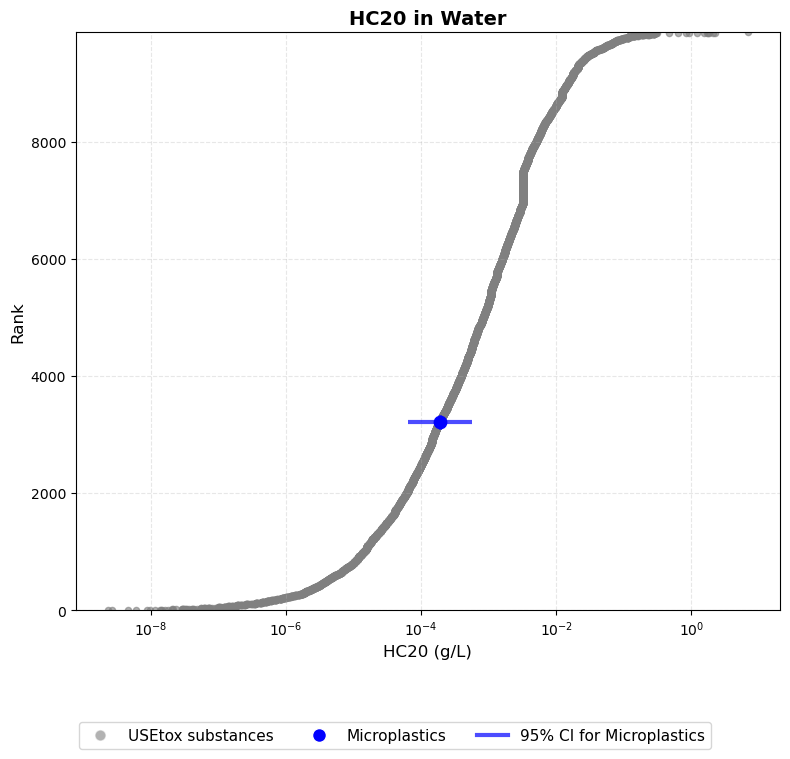


Summary Statistics:
Water HC20 - Number of substances: 9862
  Min (most toxic): 2.31e-09 g/L
  Max (least toxic): 6.87e+00 g/L
  MP central value: 1.87e-04 g/L
  MP 95% CI: [6.30e-05, 5.58e-04] g/L
  MP rank: 3210 (0 = most toxic at bottom)


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
import os

# Read the Excel file
file_path = "input/SI_B.xlsx"
usetox_sheet_name = "5.1.usetox_ef"
path_graphs = "figures/"

# Load the data
df = pd.read_excel(file_path, sheet_name=usetox_sheet_name)

# Check if columns exist
required_columns = ['CAS_Harmonized', 'HC20_gpL']
for col in required_columns:
    if col not in df.columns:
        print(f"Warning: Column '{col}' not found in the dataframe")
        print(f"Available columns: {df.columns.tolist()}")

# Clean data - remove NaN values for each compartment
water_df = df[['CAS_Harmonized', 'HC20_gpL']].dropna().copy()
#soil_df = df[['Name', 'HC20soil (mg/kgdw)']].dropna().copy()

# Convert columns to numeric
water_df['HC20_gpL'] = pd.to_numeric(water_df['HC20_gpL'], errors='coerce')
#soil_df['HC20soil (mg/kgdw)'] = pd.to_numeric(soil_df['HC20soil (mg/kgdw)'], errors='coerce')

# Sort by toxicity (lower HC20 = more toxic)
water_df = water_df.sort_values('HC20_gpL').reset_index(drop=True)
#soil_df = soil_df.sort_values('HC20soil (mg/kgdw)').reset_index(drop=True)

# Microplastics data
# Water: 0.18735 (0.063 - 0.558) mg/L -> convert to g/L
mp_water_central = 0.18735 / 1000  # g/L
mp_water_lower = 0.063 / 1000      # g/L
mp_water_upper = 0.558 / 1000      # g/L

# Soil: Galafton et al. (2026)
mp_soil_central = 0.181 * 1000  # mg/kg
mp_soil_lower = 0.123 * 1000    # mg/kg
mp_soil_upper = 0.267 * 1000    # mg/kg

# Find where MPs would rank among other substances
# For water - find rank (0 = most toxic, higher = less toxic)
water_values = water_df['HC20_gpL'].values
mp_water_rank = np.searchsorted(water_values, mp_water_central)

# For soil - find rank (0 = most toxic, higher = less toxic)
#soil_values = soil_df['HC20soil (mg/kgdw)'].values
#mp_soil_rank = np.searchsorted(soil_values, mp_soil_central)

print(f"MPs water HC20: {mp_water_central:.2e} g/L")
print(f"MPs water rank position: {mp_water_rank} (0 = most toxic, {len(water_df)-1} = least toxic)")
print(f"MPs water rank position %: {mp_water_rank/len(water_df)*100} % (0 = most toxic, {len(water_df)-1} = least toxic)")
#print(f"MPs soil HC20: {mp_soil_central:.2e} mg/kg")
#print(f"MPs soil rank position: {mp_soil_rank} (0 = most toxic, {len(soil_df)-1} = least toxic)")
#print(f"MPs soil rank position %: {mp_soil_rank/len(soil_df)*100} % (0 = most toxic, 100% = least toxic)")

# Create figure with two subplots
fig, ax1 = plt.subplots(1, 1, figsize=(8, 8), sharey=False)

# Plot 1: Water HC20
# Plot USEtox data as grey dots - assign ranks with most toxic (lowest HC20) at bottom
ranks_water = list(range(len(water_df)))  # 0, 1, 2, ..., n-1
ax1.scatter(water_df['HC20_gpL'], ranks_water, 
           color='grey', s=20, alpha=0.6, label='USEtox HC20')

# Add Microplastics point at its proper rank position
ax1.scatter(mp_water_central, mp_water_rank, 
           color='blue', s=80, zorder=5, label='Microplastics')

# Add 95% CI horizontal bar for MPs in water
ax1.hlines(mp_water_rank, mp_water_lower, mp_water_upper, 
          color='blue', linewidth=3, alpha=0.7, zorder=4)
# Add central line marker
ax1.plot([mp_water_central], [mp_water_rank], '|', color='blue', 
        markersize=10, markeredgewidth=2, zorder=6)

# Format water plot
ax1.set_xlabel('HC20 (g/L)', fontsize=12)
ax1.set_ylabel('Rank', fontsize=12)
ax1.set_title('HC20 in Water', fontsize=14, fontweight='bold')
ax1.set_xscale('log')
ax1.grid(True, alpha=0.3, linestyle='--')
# Set y-axis limits - most toxic (rank 0) at bottom
ax1.set_ylim(0, len(water_df)-1)
# NO ax1.invert_yaxis() - we want rank 0 at bottom

"""
# Plot 2: Soil HC20
# Plot USEtox data as grey dots - assign ranks with most toxic (lowest HC20) at bottom
ranks_soil = list(range(len(soil_df)))  # 0, 1, 2, ..., n-1
ax2.scatter(soil_df['HC20soil (mg/kgdw)'], ranks_soil, 
           color='grey', s=20, alpha=0.6, label='USEtox HC20')

# Add Microplastics point at its proper rank position
ax2.scatter(mp_soil_central, mp_soil_rank, 
           color='blue', s=80, zorder=5, label='Microplastics')

# Add 95% CI horizontal bar for MPs in soil
ax2.hlines(mp_soil_rank, mp_soil_lower, mp_soil_upper, 
          color='blue', linewidth=3, alpha=0.7, zorder=4)
# Add central line marker
ax2.plot([mp_soil_central], [mp_soil_rank], '|', color='blue', 
        markersize=10, markeredgewidth=2, zorder=6)

# Format soil plot
ax2.set_xlabel('HC20 (mg/kg dw)', fontsize=12)
ax2.set_ylabel('Rank', fontsize=12)
ax2.set_title('HC20 in Soil', fontsize=14, fontweight='bold')
ax2.set_xscale('log')
ax2.grid(True, alpha=0.3, linestyle='--')
# Set y-axis limits - most toxic (rank 0) at bottom
ax2.set_ylim(0, len(soil_df)-1)
# NO ax2.invert_yaxis() - we want rank 0 at bottom
"""
# Create custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', 
           markersize=8, label='USEtox substances', alpha=0.6),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', 
           markersize=10, label='Microplastics'),
    Line2D([0], [0], color='blue', linewidth=3, alpha=0.7, 
           label='95% CI for Microplastics')
]

# Add legend to figure
fig.legend(handles=legend_elements, loc='upper center', 
          bbox_to_anchor=(0.5, 0.05), ncol=3, fontsize=11)

# Adjust layout
plt.tight_layout(rect=[0, 0.1, 1, 0.95])  # Make room for the legend

# Save the figure
output_path = os.path.join(path_graphs, "Figure S.8.pdf")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"\nFigure saved to: {output_path}")

# Show the plot
plt.show()

# Print summary statistics
print(f"\nSummary Statistics:")
print(f"Water HC20 - Number of substances: {len(water_df)}")
print(f"  Min (most toxic): {water_df['HC20_gpL'].min():.2e} g/L")
print(f"  Max (least toxic): {water_df['HC20_gpL'].max():.2e} g/L")
print(f"  MP central value: {mp_water_central:.2e} g/L")
print(f"  MP 95% CI: [{mp_water_lower:.2e}, {mp_water_upper:.2e}] g/L")
print(f"  MP rank: {mp_water_rank} (0 = most toxic at bottom)")

#print(f"\nSoil HC20 - Number of substances: {len(soil_df)}")
#print(f"  Min (most toxic): {soil_df['HC20soil (mg/kgdw)'].min():.2e} mg/kg")
#print(f"  Max (least toxic): {soil_df['HC20soil (mg/kgdw)'].max():.2e} mg/kg")
#print(f"  MP central value: {mp_soil_central:.2e} mg/kg")
#print(f"  MP 95% CI: [{mp_soil_lower:.2e}, {mp_soil_upper:.2e}] mg/kg")
#print(f"  MP rank: {mp_soil_rank} (0 = most toxic at bottom)")

SHORT vs LONG TERM IW+

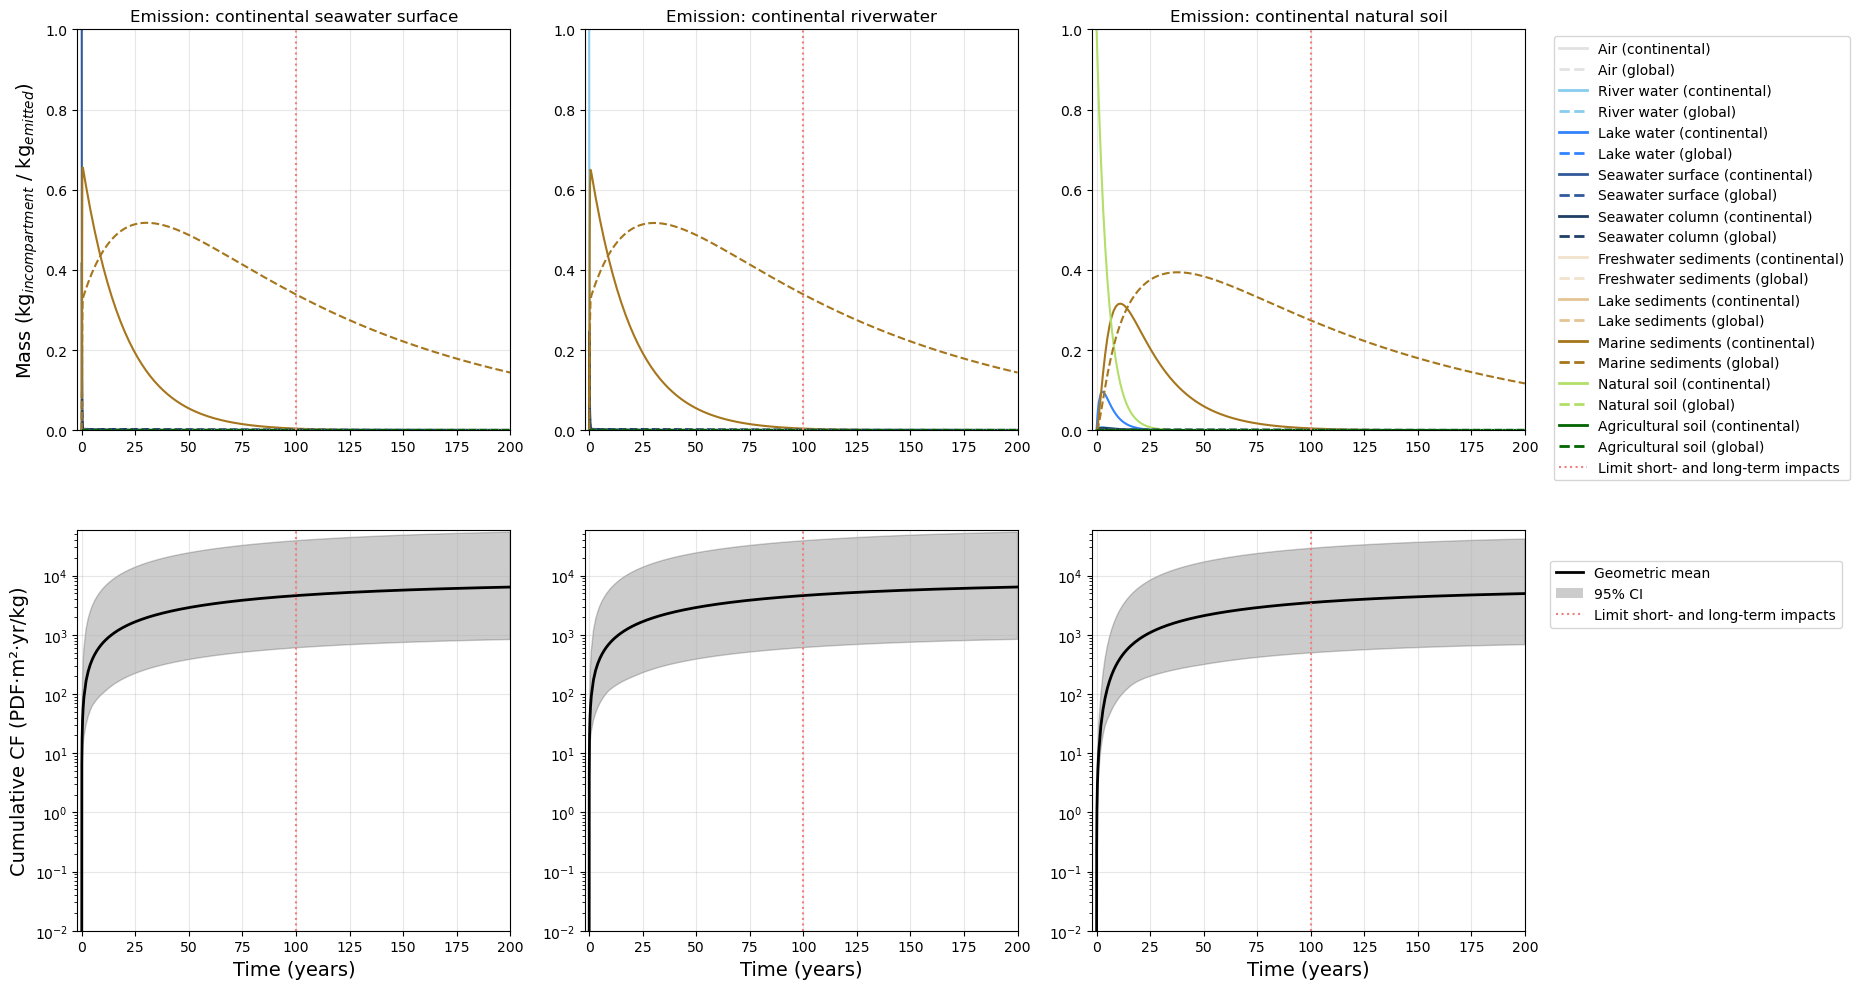

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# ============================================================================
# CONFIGURATION
# ============================================================================

# File path
excel_file = "results/mass_over_time_200years_EPS.xlsx"

# Emission compartments (sheets)
emission_compartments = ["w2R", "w1R", "s1R"]

# Compartment name mapping
compartment_names = {
    "aR": "continental air",
    "cwR": "continental cloudwater",
    "w1R": "continental riverwater",
    "w0R": "continental lakewater",
    "w2R": "continental seawater surface",
    "w3R": "continental seawater column",
    "sd0R": "continental lake sediments",
    "sd1R": "continental freshwater sediments",
    "sd2R": "continental marine sediments",
    "s1R": "continental natural soil",
    "s2R": "continental agricultural soil",
    "aC": "global air",
    "cwC": "global cloudwater",
    "w1C": "global riverwater",
    "w0C": "global lakewater",
    "w2C": "global seawater surface",
    "w3C": "global seawater column",
    "sd0C": "global lake sediments",
    "sd1C": "global freshwater sediments",
    "sd2C": "global marine sediments",
    "s1C": "global natural soil",
    "s2C": "global agricultural soil"
}

# Colors (from your specification)
colors = {
    "continental air": '#E2E2E2',
    "global air": '#E2E2E2',
    "continental riverwater": "rgb(136, 204,238)",
    "global riverwater": "rgb(136, 204,238)",
    "continental lakewater": "#3283FE",
    "global lakewater": "#3283FE",
    "continental seawater surface": "#325A9B",
    "global seawater surface": "#325A9B",
    "continental seawater column": "#1E3F66",
    "global seawater column": "#1E3F66",
    "continental freshwater sediments": "rgb(241, 226, 204)",
    "global freshwater sediments": "rgb(241, 226, 204)",
    "continental lake sediments": "rgb(229, 196, 148)",
    "global lake sediments": "rgb(229, 196, 148)",
    "continental marine sediments": "rgb(166,118,29)",
    "global marine sediments": "rgb(166,118,29)",
    "continental natural soil": "rgb(179, 222, 105)",
    "global natural soil": "rgb(179, 222, 105)",
    "continental agricultural soil": "darkgreen",
    "global agricultural soil": "darkgreen"
}

# Convert RGB strings to matplotlib colors
def parse_rgb(rgb_str):
    if rgb_str.startswith('rgb'):
        rgb_str = rgb_str.replace('rgb(', '').replace(')', '')
        r, g, b = [int(x.strip()) for x in rgb_str.split(',')]
        return (r/255, g/255, b/255)
    return rgb_str

# Parse all colors
parsed_colors = {}
for key, value in colors.items():
    parsed_colors[key] = parse_rgb(value)

# ============================================================================
# READ DATA
# ============================================================================

# Read all sheets
all_sheets = pd.read_excel(excel_file, sheet_name=None)

# ============================================================================
# CREATE PLOT
# ============================================================================

# Create figure with 2 rows, 3 columns (sharex=False to allow independent tick labels)
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=False)
fig.subplots_adjust(hspace=0.1, wspace=0.3)

# For each emission compartment (column)
for col_idx, emit_comp in enumerate(emission_compartments):
    
    # Check if sheet exists
    if emit_comp not in all_sheets:
        print(f"Warning: Sheet {emit_comp} not found")
        continue
    
    # Read the data
    df = all_sheets[emit_comp]
    
    # Extract Year column
    years = df['Year'].values
    
    # Get all compartment columns (those ending with _mean, _ll_95, _ul_95)
    mean_cols = [col for col in df.columns if col.endswith('_mean') and col != 'CF_geomean']
    
    # ========================================================================
    # TOP ROW (MASS in compartments) – now with titles
    # ========================================================================
    ax_top = axes[0, col_idx]
    
    # Plot mass for all compartments
    for mean_col in mean_cols:
        # Extract base compartment code (e.g., "aR" from "aR_mean")
        comp_code = mean_col.replace('_mean', '')
        
        # Get full compartment name
        if comp_code in compartment_names:
            full_name = compartment_names[comp_code]
        else:
            full_name = comp_code
        
        # Determine if global (contains 'C' or 'c')
        is_global = 'C' in comp_code or (len(comp_code) > 1 and comp_code[1] == 'C')
        
        # Get base compartment for color
        if is_global:
            base_comp = full_name.replace('global', 'continental').strip()
        else:
            base_comp = full_name
        
        # Get color
        if base_comp in parsed_colors:
            color = parsed_colors[base_comp]
        else:
            color = 'gray'
        
        # Line style: dashed for global, solid for continental
        linestyle = '--' if is_global else '-'
        
        # Plot mean
        ax_top.plot(years, df[mean_col].values, 
                    color=color, linestyle=linestyle, 
                    linewidth=1.5, label=full_name)
    
    # Set title above top row (one per column)
    ax_top.set_title(f'Emission: {compartment_names.get(emit_comp, emit_comp)}')
    
    # Enable x‑axis tick labels on top row (numbers), but no xlabel
    ax_top.tick_params(axis='x', labelbottom=True)
    ax_top.set_xlabel('')  # no label on top row
    ax_top.set_ylabel(r'Mass (kg$_{in compartment}$ / kg$_{emitted}$)', fontsize=14)
    ax_top.grid(True, alpha=0.3)
    ax_top.set_ylim(0, 1)
    
    # Add vertical dotted line at 100 years
    ax_top.axvline(x=100, color='lightcoral', linestyle=':', linewidth=1.5,
                   label='Limit short- and long-term impacts')
    
    # Add legend only to the last column (top row)
    if col_idx == 2:
        # Create custom legend handles for compartments
        legend_handles = []
        legend_labels = []
        
        compartment_types = [
            ("air", "Air"),
            ("riverwater", "River water"),
            ("lakewater", "Lake water"),
            ("seawater surface", "Seawater surface"),
            ("seawater column", "Seawater column"),
            ("freshwater sediments", "Freshwater sediments"),
            ("lake sediments", "Lake sediments"),
            ("marine sediments", "Marine sediments"),
            ("natural soil", "Natural soil"),
            ("agricultural soil", "Agricultural soil")
        ]
        
        for comp_key, comp_label in compartment_types:
            cont_name = f"continental {comp_key}"
            if cont_name in parsed_colors:
                # Continental (solid)
                legend_handles.append(Line2D([0], [0], color=parsed_colors[cont_name], 
                                             linestyle='-', linewidth=2))
                # Global (dashed)
                legend_handles.append(Line2D([0], [0], color=parsed_colors[cont_name], 
                                             linestyle='--', linewidth=2))
                legend_labels.extend([f"{comp_label} (continental)", f"{comp_label} (global)"])
        
        # Add the vertical line to the top legend
        legend_handles.append(Line2D([0], [0], color='lightcoral', linestyle=':', linewidth=1.5))
        legend_labels.append('Limit short- and long-term impacts')
        
        ax_top.legend(legend_handles, legend_labels, 
                      loc='upper left', bbox_to_anchor=(1.05, 1), 
                      fontsize=10, ncol=1)
    
    # ========================================================================
    # BOTTOM ROW (CUMULATIVE CF) – no individual legends
    # ========================================================================
    ax_bottom = axes[1, col_idx]
    ax_bottom.set_yscale('log')
    
    # Check if CF columns exist
    if 'CF_geomean' in df.columns:
        ax_bottom.plot(years, df['CF_geomean'].values, 
                       color='black', linewidth=2, label='Geometric mean')
        
        # Add confidence interval
        ax_bottom.fill_between(years, 
                               df['CF_ll_95'].values, 
                               df['CF_ul_95'].values,
                               color='black', alpha=0.2, label='95% CI')
    
    # Set x‑axis label only on bottom row
    ax_bottom.set_xlabel('Time (years)', fontsize=14)
    ax_bottom.set_ylabel('Cumulative CF (PDF·m²·yr/kg)', fontsize=14)
    ax_bottom.grid(True, alpha=0.3)
    
    # Add vertical dotted line at 100 years
    ax_bottom.axvline(x=100, color='lightcoral', linestyle=':', linewidth=1.5,
                      label='Limit short- and long-term impacts')
    
    # Synchronize x‑axis limits across all subplots (so zoom/pan stays consistent)
    ax_bottom.set_xlim(-2, max(years))
    ax_top.set_xlim(-2, max(years))

# ============================================================================
# SINGLE LEGEND FOR BOTTOM ROW (placed below the top row legend)
# ============================================================================
# Create custom handles for CF plot (geometric mean line, CI patch, vertical line)
cf_handles = [
    Line2D([0], [0], color='black', linewidth=2, label='Geometric mean'),
    Rectangle((0,0), 1, 1, facecolor='black', alpha=0.2, label='95% CI'),
    Line2D([0], [0], color='lightcoral', linestyle=':', linewidth=1.5, label='Limit short- and long-term impacts')
]
cf_labels = ['Geometric mean', '95% CI', 'Limit short- and long-term impacts']

# Place this legend outside the plot, to the right, below the top legend
# The top legend is at bbox_to_anchor=(1.05, 1) relative to axes[0,2].
# We use figure coordinates for the bottom legend: x=0.9 (right), y=0.5 (mid) – adjust as needed.
# Better: use bbox_to_anchor=(1.05, 0.45) in axes[1,2] coordinates.
fig.legend(cf_handles, cf_labels, 
           loc='center left', 
           bbox_to_anchor=(0.86, 0.40),  # (x, y) in figure fraction (0=left/bottom, 1=right/top)
           fontsize=10, frameon=True)

# ============================================================================
# FINAL TOUCHES – adjust y‑limits for CF plots
# ============================================================================
# Find global min/max for CF (log scale)
cf_min = float('inf')
cf_max = float('-inf')
for col_idx in range(3):
    if emission_compartments[col_idx] in all_sheets:
        df = all_sheets[emission_compartments[col_idx]]
        if 'CF_geomean' in df.columns:
            cf_min = min(cf_min, df['CF_ll_95'].min())
            cf_max = max(cf_max, df['CF_ul_95'].max())

# Add small margin
cf_min = cf_min * 0.9
cf_max = cf_max * 1.1

# Apply to all bottom row plots
for col_idx in range(3):
    axes[1, col_idx].set_ylim(1e-2, cf_max)  # or use cf_min if >0
    axes[1, col_idx].set_yscale('log')

# Remove y‑axis labels for middle and right columns (both rows)
for col_idx in [1, 2]:
    axes[0, col_idx].set_ylabel('')   # mass row
    axes[1, col_idx].set_ylabel('')   # CF row

# Adjust layout to prevent legend cutoff
plt.tight_layout()
plt.subplots_adjust(right=0.85)  # Make room for legends

# Save figure
plt.savefig('figures/Figure 5_EPS.pdf', dpi=300, bbox_inches='tight')
plt.show()

Found 10 polymers with data (sorted by marine CF)


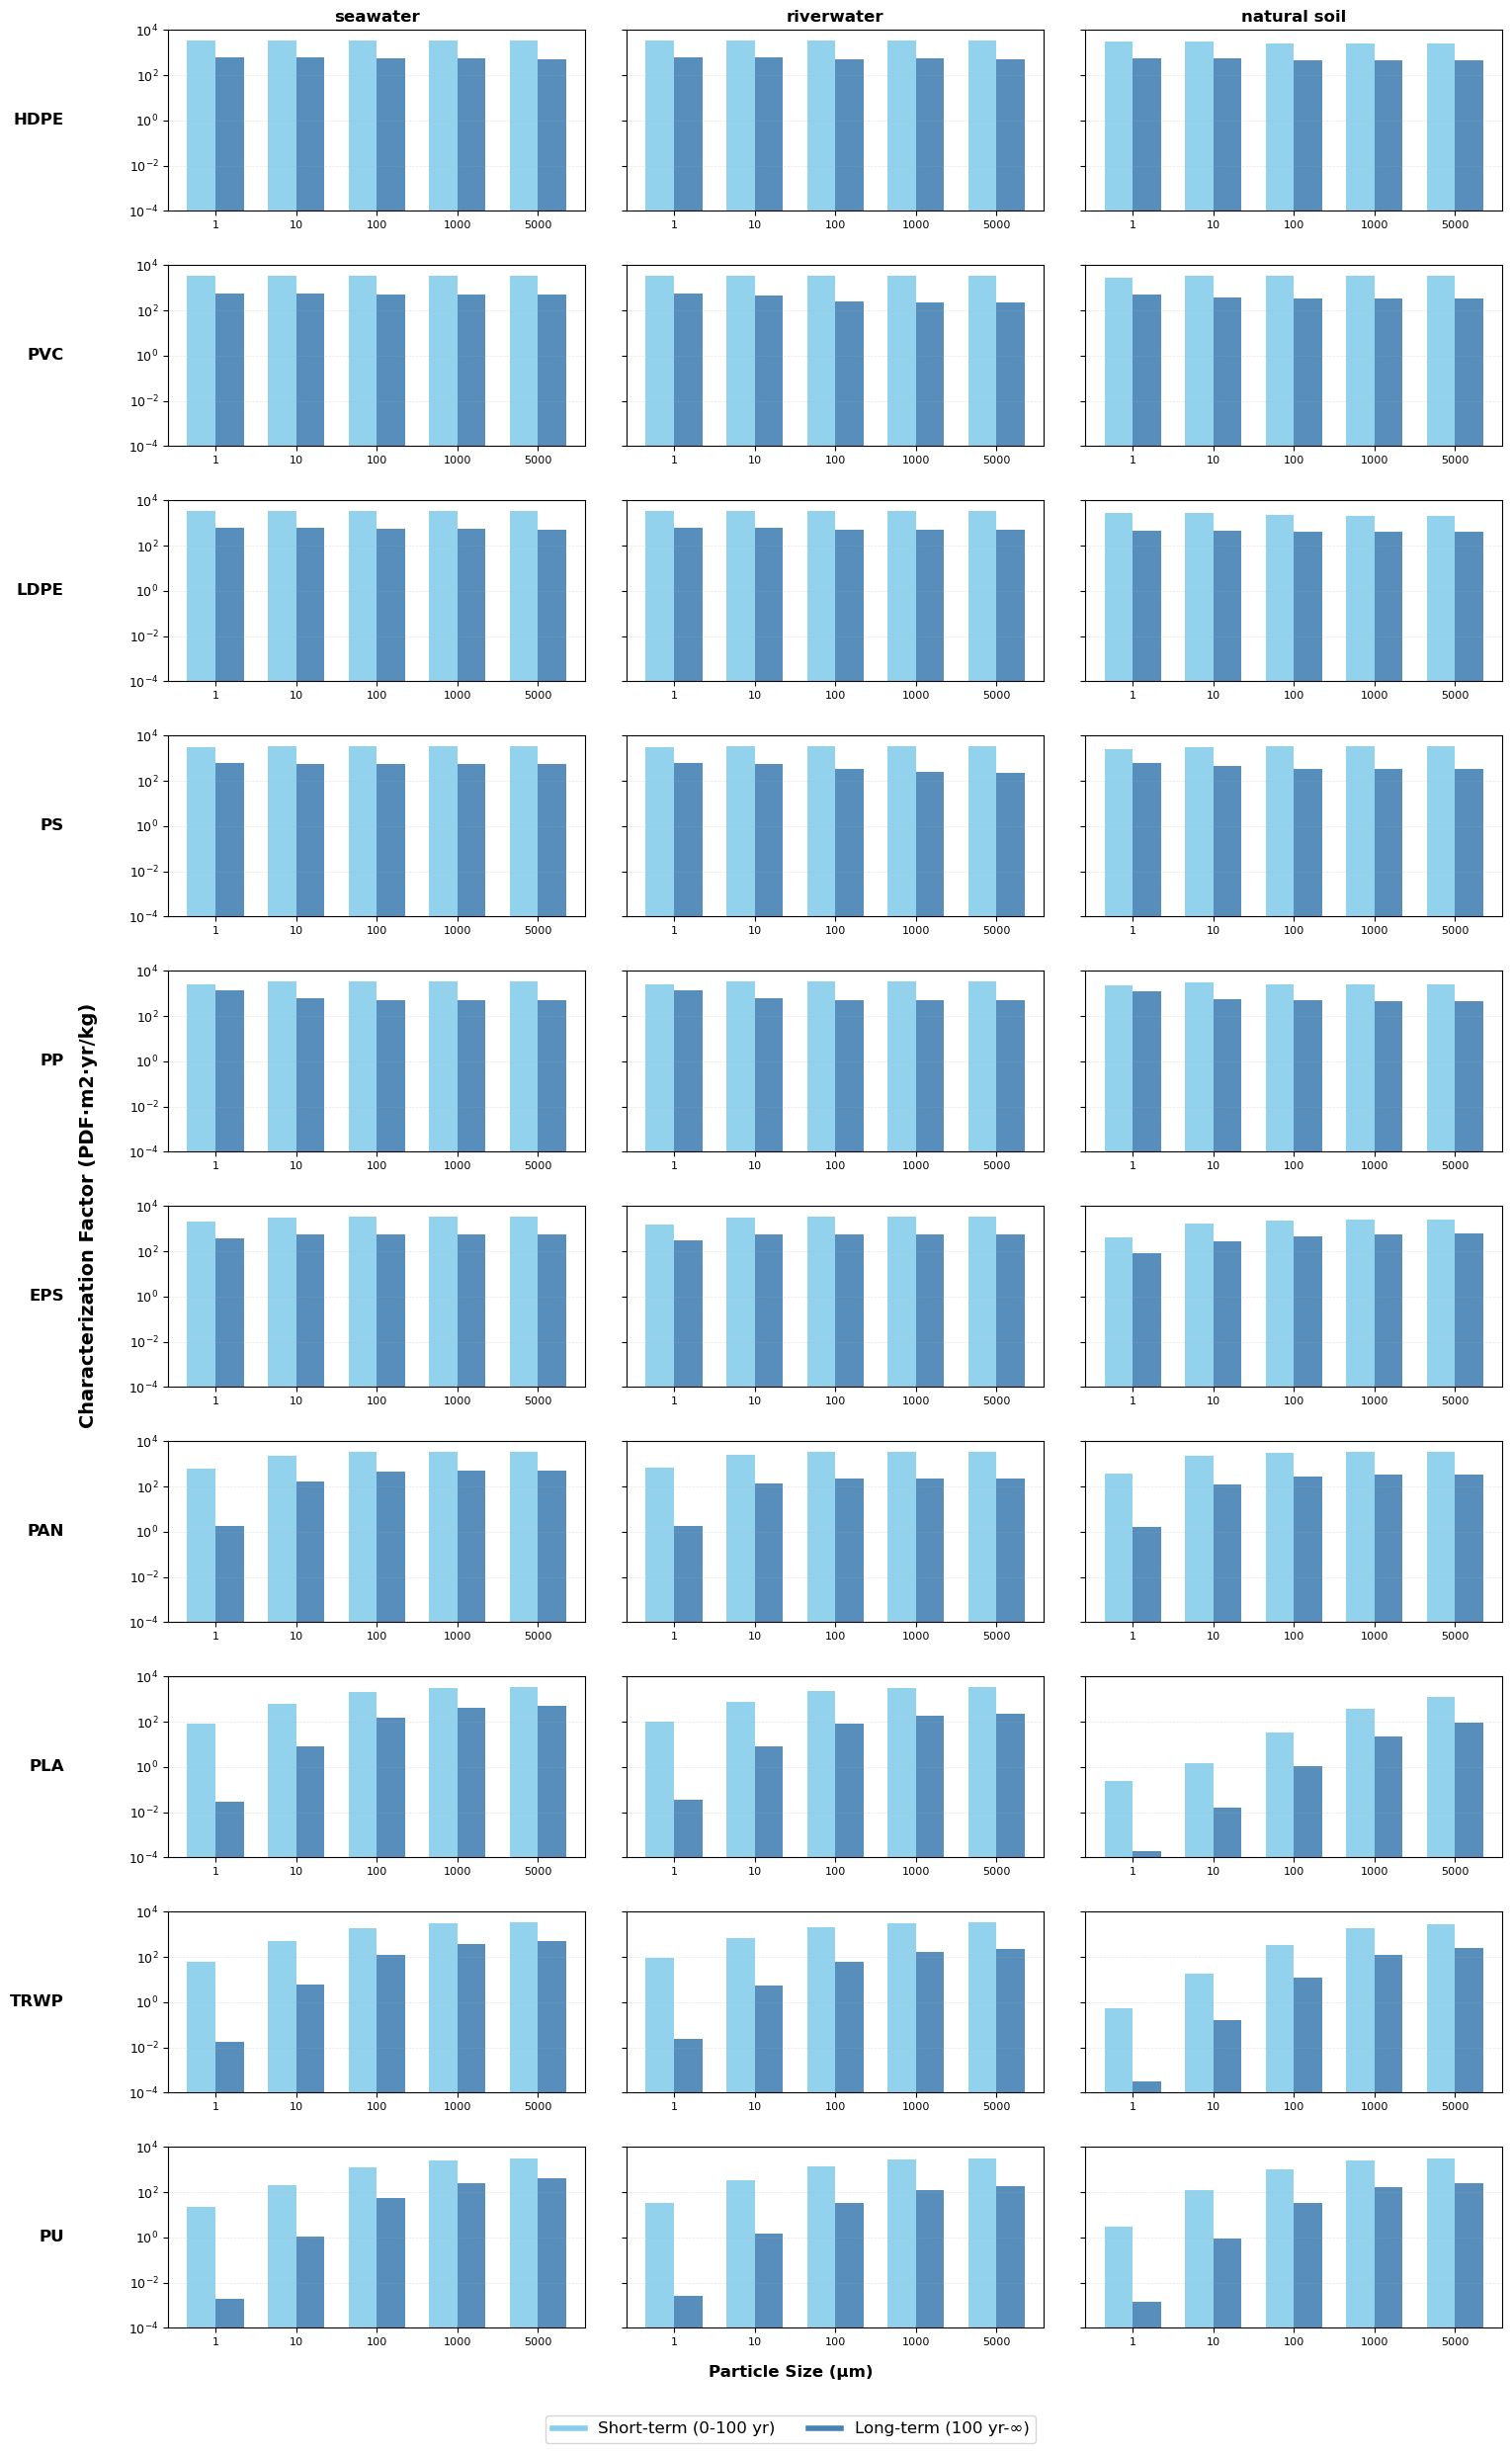

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os
from matplotlib.ticker import LogLocator

# Define paths
ss_path = "results/SI_C.xlsx"
short_term_path = "results/SI_D.xlsx"
path_graphs = "figures/"
sheet_name_ss = "CF_end_PDF_m2_yr"  
sheet_name_st = "CF_end_PDF_m2_yr_100_yrs"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Read both Excel files
df_ss = pd.read_excel(ss_path, sheet_name=sheet_name_ss)
df_st = pd.read_excel(short_term_path, sheet_name=sheet_name_st)

# Polymers to remove (Linen, Viscose, Rayon, Modal)
polymers_to_remove = ["Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#for subgraphs
#polymers_to_remove = ["HDPE","PVC","LDPE","PS","PP","EPS","PAN","PLA","TRWP","PU", "Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
polymers_to_remove = ["PBSA","PET","PA_Nylon","PBAT","PCL","Cotton","Lyocell","PHA","starch_blend","Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]


# Apply filters to both dataframes
filtered_ss = df_ss[
    (df_ss['size'].isin(size_filter)) & 
    (df_ss['shape'].isin(shape_filter)) &
    (df_ss['region'] == region_filter) &
    (df_ss['emission_compartment'].isin(emission_compartments)) &
    (~df_ss['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_st = df_st[
    (df_st['size'].isin(size_filter)) & 
    (df_st['shape'].isin(shape_filter)) &
    (df_st['region'] == region_filter) &
    (df_st['emission_compartment'].isin(emission_compartments)) &
    (~df_st['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_ss = filtered_ss[~filtered_ss['elementary_flowname'].str.contains('default', case=False, na=False)]
filtered_st = filtered_st[~filtered_st['elementary_flowname'].str.contains('default', case=False, na=False)]

# Sort polymers by minimum marine CF for continental seawater surface
seawater_ss = filtered_ss[filtered_ss['emission_compartment'] == 'continental seawater surface']
seawater_st = filtered_st[filtered_st['emission_compartment'] == 'continental seawater surface']

# Calculate min marine CF for each polymer (using steady-state data, or whichever you prefer)
marine_min = seawater_ss.groupby('polymer')['marine_geom_mean'].min()

# Sort polymers by this value
sorted_polymers = marine_min.sort_values().index.tolist()

# Filter to only include polymers that have complete data
polymers_with_data = [p for p in sorted_polymers if p in filtered_ss['polymer'].unique() 
                      and p in filtered_st['polymer'].unique()]

polymers_with_data = polymers_with_data[::-1]  # Reverse the order


print(f"Found {len(polymers_with_data)} polymers with data (sorted by marine CF)")

# Set up the plot
fig, axes = plt.subplots(nrows=len(polymers_with_data), ncols=len(emission_compartments), 
                         figsize=(15, 2.5*len(polymers_with_data)),  # Adjust height per row
                         sharey='row')  # Share y-axis within each row for better comparison

# Ensure axes is 2D
if len(polymers_with_data) == 1:
    axes = axes.reshape(1, -1)
if len(emission_compartments) == 1:
    axes = axes.reshape(-1, 1)

# Colors for short-term and steady-state (more distinct)
colors = {'short_term': '#87CEEB', 'long_term': '#4682B4'}  # Light blue and dark blue

# Width of bars
bar_width = 0.35

# Loop through polymers (rows) and emission compartments (columns)
for i, polymer in enumerate(polymers_with_data):
    row_axes = []          # store axes in this row
    row_min_lower = []     # collect lower bounds for this row
    row_max_upper = []     # collect upper bounds for this row
    
    for j, compartment in enumerate(emission_compartments):
        ax = axes[i, j]
        row_axes.append(ax)
        
        # Get data for this polymer and compartment
        ss_data = filtered_ss[
            (filtered_ss['polymer'] == polymer) & 
            (filtered_ss['emission_compartment'] == compartment)
        ].sort_values('size')
        
        st_data = filtered_st[
            (filtered_st['polymer'] == polymer) & 
            (filtered_st['emission_compartment'] == compartment)
        ].sort_values('size')
        
        # Get sizes for x-axis positions
        sizes = ss_data['size'].values
        x_pos = np.arange(len(sizes))
        
        # Plot bars if data exists for all sizes
        if len(ss_data) == len(size_filter) and len(st_data) == len(size_filter):
            # Calculate long-term values and propagated errors - OPTION 2 (RELATIVE ERRORS)
            ss_geom = ss_data['total_geom_mean'].values
            st_geom = st_data['total_geom_mean'].values
            lt_geom = ss_geom - st_geom
            lt_geom = np.maximum(lt_geom, 0)  # Ensure non-negative
            
            # Calculate relative errors
            # Avoid division by zero by adding small epsilon where needed
            epsilon = 1e-30
            
            # Relative errors for steady-state
            ss_rel_lower = (ss_geom - ss_data['total_ll_95'].values) / (ss_geom + epsilon)
            ss_rel_upper = (ss_data['total_ul_95'].values - ss_geom) / (ss_geom + epsilon)
            
            # Relative errors for short-term
            st_rel_lower = (st_geom - st_data['total_ll_95'].values) / (st_geom + epsilon)
            st_rel_upper = (st_data['total_ul_95'].values - st_geom) / (st_geom + epsilon)
            
            # Propagate relative errors (add in quadrature)
            lt_rel_lower = np.sqrt(ss_rel_lower**2 + st_rel_lower**2)
            lt_rel_upper = np.sqrt(ss_rel_upper**2 + st_rel_upper**2)
            
            # Convert back to absolute errors for plotting
            # For values near zero, use a small offset to avoid division issues
            lt_geom_safe = np.where(lt_geom > epsilon, lt_geom, epsilon)
            
            lt_lower_err = lt_geom_safe * lt_rel_lower
            lt_upper_err = lt_geom_safe * lt_rel_upper
            
            # Calculate confidence limits for long-term
            lt_ll = lt_geom - lt_lower_err
            lt_ul = lt_geom + lt_upper_err
            
            
            
            # Collect error bar extremes for row-wise limit calculation
            #row_min_lower.append(st_data['total_ll_95'].min())
            #row_min_lower.append(ss_data['total_ll_95'].min())
            #row_min_lower.append(lt_lower_err.min())
            #row_max_upper.append(st_data['total_ul_95'].max())
            #row_max_upper.append(ss_data['total_ul_95'].max())
            row_min_lower.append(st_data['total_geom_mean'].min())
            row_min_lower.append(lt_geom.min())
            row_max_upper.append(st_data['total_geom_mean'].max())
            row_max_upper.append(lt_geom.max())
            
            # Short-term bars (left)
            ax.bar(x_pos - bar_width/2, st_data['total_geom_mean'].values, 
                   bar_width, color=colors['short_term'],
                   #yerr=[st_data['total_geom_mean'].values - st_data['total_ll_95'].values,
                   #      st_data['total_ul_95'].values - st_data['total_geom_mean'].values],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # long-term bars (right)
            #ax.bar(x_pos + bar_width/2, ss_data['total_geom_mean'].values, 
            #       bar_width, color=colors['steady_state'],
            #       yerr=[ss_data['total_geom_mean'].values - ss_data['total_ll_95'].values,
            #             ss_data['total_ul_95'].values - ss_data['total_geom_mean'].values],
            #       capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)

            # Long-term bars (right) - using calculated lt_geom and propagated errors
            ax.bar(x_pos + bar_width/2, lt_geom, 
                   bar_width, color=colors['long_term'],
                   #yerr=[lt_lower_err, lt_upper_err],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # Set y-axis to log scale
            ax.set_yscale('log')
        else:
            # Show placeholder for missing data
            ax.text(0.5, 0.5, 'Incomplete data', ha='center', va='center', 
                   transform=ax.transAxes, fontsize=8, style='italic')
            ax.set_yscale('log')
        
        # Format x-axis
        ax.set_xticks(x_pos if len(ss_data) == len(size_filter) else [])
        ax.set_xticklabels([str(s) for s in size_filter] if len(ss_data) == len(size_filter) else [], 
                          fontsize=8)
        
        # Only show y-axis labels and ticks for first column
        if j == 0:
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        
        # Set subplot title for first row only (emission compartments)
        if i == 0:
            # Clean up compartment name for title
            clean_title = compartment.replace('continental ', '').replace(' surface', '')
            ax.set_title(f'{clean_title}', fontsize=12, fontweight='bold')
        
        # Add polymer name as row label on the left (outside the plot)
        if j == 0:
            ax.annotate(polymer, xy=(-0.25, 0.5), xycoords='axes fraction',
                       ha='right', va='center', fontsize=12, fontweight='bold')
        
        # Add grid for better readability
        ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    
    # After plotting all compartments for this polymer, set consistent y-limits for the entire row
    if row_min_lower and row_max_upper:  # Check if we collected any values
        # Get the overall min lower and max upper for the row
        row_min = max(min(row_min_lower),1e-4)
        row_max = max(row_max_upper)
        
        # Add padding on log scale (0.15 in log10 ≈ 40% margin)
        # Make sure values are positive for log scale
        if row_min > 0 and row_max > 0:
            y_min = 10 ** (np.log10(row_min) - 0.15)
            y_max = 10 ** (np.log10(row_max) + 0.15)

            #if y_max/y_min < 1000:
            #    y_min = 10 ** (np.log10(row_min) - 1.2)
             #   y_max = 10 ** (np.log10(row_max) + 1.2)

            
            # Apply same limits to all axes in this row
            for ax in row_axes:
                ax.set_ylim(1e-4, 1e+4)
                ax.yaxis.set_minor_locator(LogLocator(base=10, subs=[]))  # No minor ticks


# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Characterization Factor (PDF·m2·yr/kg)', va='center', 
         rotation='vertical', fontsize=14, fontweight='bold')

# Add x-axis label at the bottom
fig.text(0.5, 0.03, 'Particle Size (μm)', ha='center', fontsize=12, fontweight='bold')

# Add legend
handles = [Line2D([0], [0], color=colors['short_term'], lw=4, label='Short-term (0-100 yr)'),
           Line2D([0], [0], color=colors['long_term'], lw=4, label='Long-term (100 yr-∞)')]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.00), 
          ncol=2, fontsize=12, frameon=True, fancybox=True, shadow=False)

# Adjust layout
plt.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.05, hspace=0.3, wspace=0.1)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.16_IW+_a.pdf'), 
            bbox_inches='tight')

plt.show()

Found 9 polymers with data (sorted by marine CF)


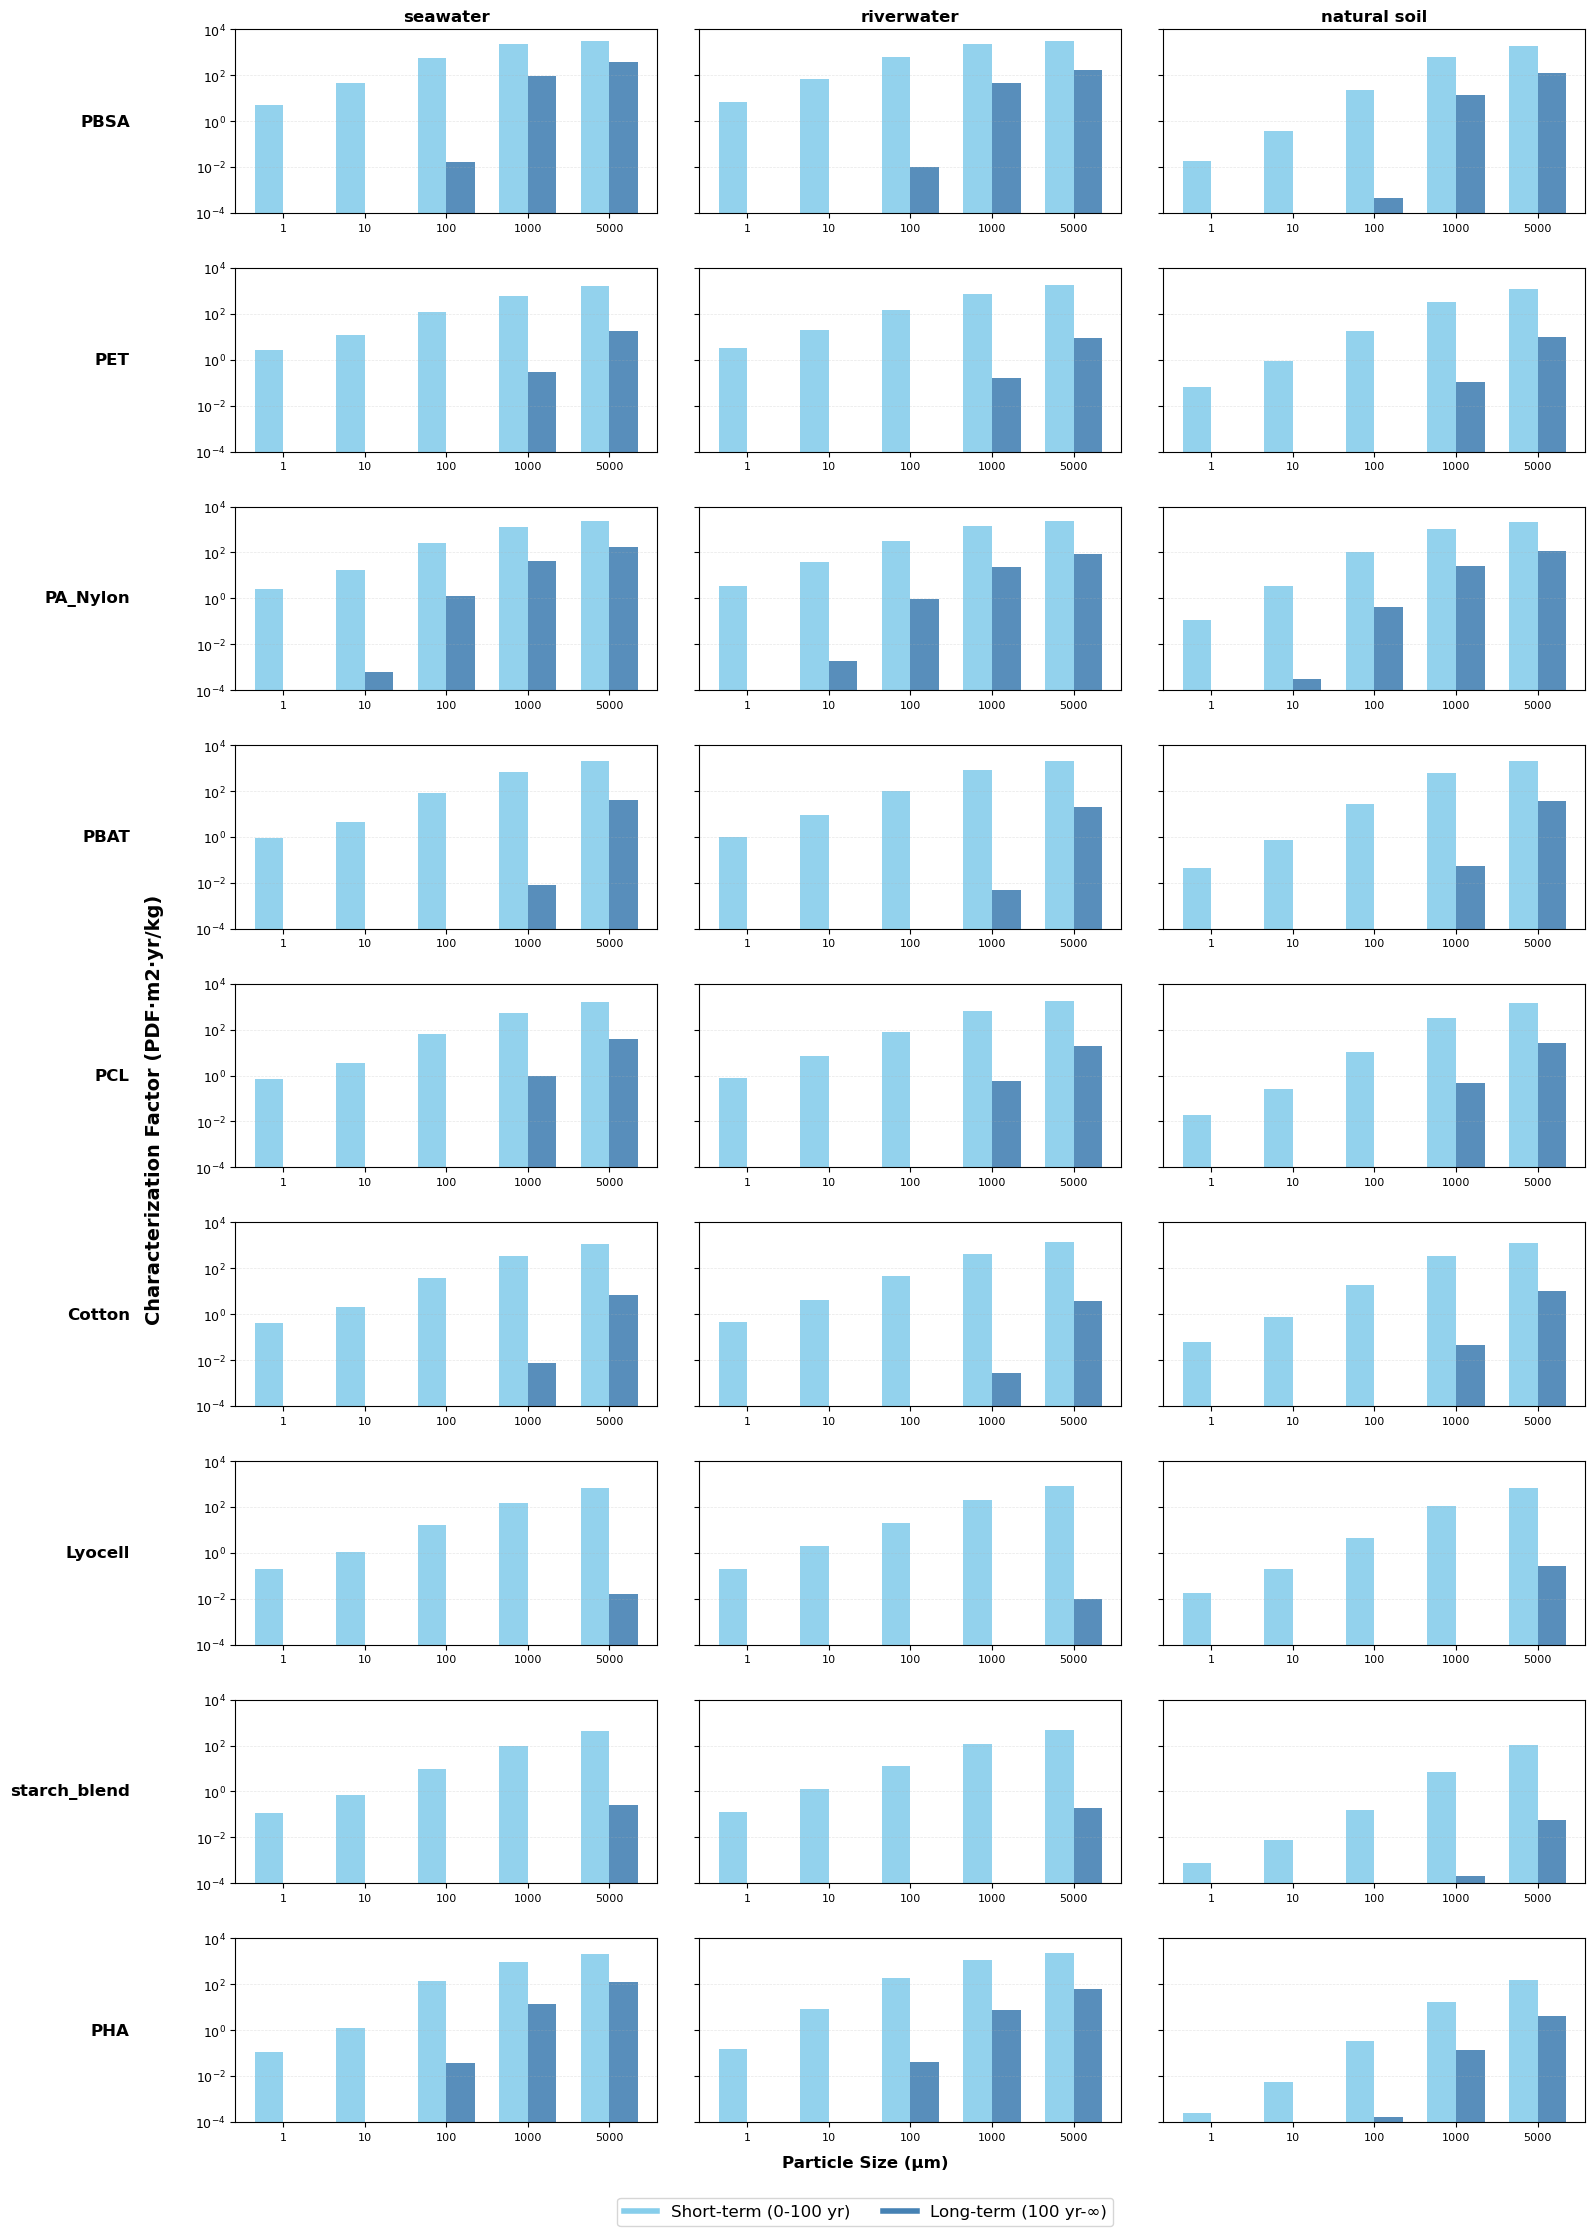

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os
from matplotlib.ticker import LogLocator

# Define paths
ss_path = "results/SI_C.xlsx"
short_term_path = "results/SI_D.xlsx"
path_graphs = "figures/"
sheet_name_ss = "CF_end_PDF_m2_yr"  
sheet_name_st = "CF_end_PDF_m2_yr_100_yrs"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Read both Excel files
df_ss = pd.read_excel(ss_path, sheet_name=sheet_name_ss)
df_st = pd.read_excel(short_term_path, sheet_name=sheet_name_st)

# Polymers to remove (Linen, Viscose, Rayon, Modal)
polymers_to_remove = ["Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#for subgraphs
polymers_to_remove = ["HDPE","PVC","LDPE","PS","PP","EPS","PAN","PLA","TRWP","PU", "Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#polymers_to_remove = ["PBSA","PET","PA_Nylon","PBAT","PCL","Cotton","Lyocell","PHA","starch_blend","Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]


# Apply filters to both dataframes
filtered_ss = df_ss[
    (df_ss['size'].isin(size_filter)) & 
    (df_ss['shape'].isin(shape_filter)) &
    (df_ss['region'] == region_filter) &
    (df_ss['emission_compartment'].isin(emission_compartments)) &
    (~df_ss['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_st = df_st[
    (df_st['size'].isin(size_filter)) & 
    (df_st['shape'].isin(shape_filter)) &
    (df_st['region'] == region_filter) &
    (df_st['emission_compartment'].isin(emission_compartments)) &
    (~df_st['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_ss = filtered_ss[~filtered_ss['elementary_flowname'].str.contains('default', case=False, na=False)]
filtered_st = filtered_st[~filtered_st['elementary_flowname'].str.contains('default', case=False, na=False)]

# Sort polymers by minimum marine CF for continental seawater surface
seawater_ss = filtered_ss[filtered_ss['emission_compartment'] == 'continental seawater surface']
seawater_st = filtered_st[filtered_st['emission_compartment'] == 'continental seawater surface']

# Calculate min marine CF for each polymer (using steady-state data, or whichever you prefer)
marine_min = seawater_ss.groupby('polymer')['marine_geom_mean'].min()

# Sort polymers by this value
sorted_polymers = marine_min.sort_values().index.tolist()

# Filter to only include polymers that have complete data
polymers_with_data = [p for p in sorted_polymers if p in filtered_ss['polymer'].unique() 
                      and p in filtered_st['polymer'].unique()]

polymers_with_data = polymers_with_data[::-1]  # Reverse the order


print(f"Found {len(polymers_with_data)} polymers with data (sorted by marine CF)")

# Set up the plot
fig, axes = plt.subplots(nrows=len(polymers_with_data), ncols=len(emission_compartments), 
                         figsize=(15, 2.5*len(polymers_with_data)),  # Adjust height per row
                         sharey='row')  # Share y-axis within each row for better comparison

# Ensure axes is 2D
if len(polymers_with_data) == 1:
    axes = axes.reshape(1, -1)
if len(emission_compartments) == 1:
    axes = axes.reshape(-1, 1)

# Colors for short-term and steady-state (more distinct)
colors = {'short_term': '#87CEEB', 'long_term': '#4682B4'}  # Light blue and dark blue

# Width of bars
bar_width = 0.35

# Loop through polymers (rows) and emission compartments (columns)
for i, polymer in enumerate(polymers_with_data):
    row_axes = []          # store axes in this row
    row_min_lower = []     # collect lower bounds for this row
    row_max_upper = []     # collect upper bounds for this row
    
    for j, compartment in enumerate(emission_compartments):
        ax = axes[i, j]
        row_axes.append(ax)
        
        # Get data for this polymer and compartment
        ss_data = filtered_ss[
            (filtered_ss['polymer'] == polymer) & 
            (filtered_ss['emission_compartment'] == compartment)
        ].sort_values('size')
        
        st_data = filtered_st[
            (filtered_st['polymer'] == polymer) & 
            (filtered_st['emission_compartment'] == compartment)
        ].sort_values('size')
        
        # Get sizes for x-axis positions
        sizes = ss_data['size'].values
        x_pos = np.arange(len(sizes))
        
        # Plot bars if data exists for all sizes
        if len(ss_data) == len(size_filter) and len(st_data) == len(size_filter):
            # Calculate long-term values and propagated errors - OPTION 2 (RELATIVE ERRORS)
            ss_geom = ss_data['total_geom_mean'].values
            st_geom = st_data['total_geom_mean'].values
            lt_geom = ss_geom - st_geom
            lt_geom = np.maximum(lt_geom, 0)  # Ensure non-negative
            
            # Calculate relative errors
            # Avoid division by zero by adding small epsilon where needed
            epsilon = 1e-30
            
            # Relative errors for steady-state
            ss_rel_lower = (ss_geom - ss_data['total_ll_95'].values) / (ss_geom + epsilon)
            ss_rel_upper = (ss_data['total_ul_95'].values - ss_geom) / (ss_geom + epsilon)
            
            # Relative errors for short-term
            st_rel_lower = (st_geom - st_data['total_ll_95'].values) / (st_geom + epsilon)
            st_rel_upper = (st_data['total_ul_95'].values - st_geom) / (st_geom + epsilon)
            
            # Propagate relative errors (add in quadrature)
            lt_rel_lower = np.sqrt(ss_rel_lower**2 + st_rel_lower**2)
            lt_rel_upper = np.sqrt(ss_rel_upper**2 + st_rel_upper**2)
            
            # Convert back to absolute errors for plotting
            # For values near zero, use a small offset to avoid division issues
            lt_geom_safe = np.where(lt_geom > epsilon, lt_geom, epsilon)
            
            lt_lower_err = lt_geom_safe * lt_rel_lower
            lt_upper_err = lt_geom_safe * lt_rel_upper
            
            # Calculate confidence limits for long-term
            lt_ll = lt_geom - lt_lower_err
            lt_ul = lt_geom + lt_upper_err
            
            
            
            # Collect error bar extremes for row-wise limit calculation
            #row_min_lower.append(st_data['total_ll_95'].min())
            #row_min_lower.append(ss_data['total_ll_95'].min())
            #row_min_lower.append(lt_lower_err.min())
            #row_max_upper.append(st_data['total_ul_95'].max())
            #row_max_upper.append(ss_data['total_ul_95'].max())
            row_min_lower.append(st_data['total_geom_mean'].min())
            row_min_lower.append(lt_geom.min())
            row_max_upper.append(st_data['total_geom_mean'].max())
            row_max_upper.append(lt_geom.max())
            
            # Short-term bars (left)
            ax.bar(x_pos - bar_width/2, st_data['total_geom_mean'].values, 
                   bar_width, color=colors['short_term'],
                   #yerr=[st_data['total_geom_mean'].values - st_data['total_ll_95'].values,
                   #      st_data['total_ul_95'].values - st_data['total_geom_mean'].values],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # long-term bars (right)
            #ax.bar(x_pos + bar_width/2, ss_data['total_geom_mean'].values, 
            #       bar_width, color=colors['steady_state'],
            #       yerr=[ss_data['total_geom_mean'].values - ss_data['total_ll_95'].values,
            #             ss_data['total_ul_95'].values - ss_data['total_geom_mean'].values],
            #       capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)

            # Long-term bars (right) - using calculated lt_geom and propagated errors
            ax.bar(x_pos + bar_width/2, lt_geom, 
                   bar_width, color=colors['long_term'],
                   #yerr=[lt_lower_err, lt_upper_err],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # Set y-axis to log scale
            ax.set_yscale('log')
        else:
            # Show placeholder for missing data
            ax.text(0.5, 0.5, 'Incomplete data', ha='center', va='center', 
                   transform=ax.transAxes, fontsize=8, style='italic')
            ax.set_yscale('log')
        
        # Format x-axis
        ax.set_xticks(x_pos if len(ss_data) == len(size_filter) else [])
        ax.set_xticklabels([str(s) for s in size_filter] if len(ss_data) == len(size_filter) else [], 
                          fontsize=8)
        
        # Only show y-axis labels and ticks for first column
        if j == 0:
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        
        # Set subplot title for first row only (emission compartments)
        if i == 0:
            # Clean up compartment name for title
            clean_title = compartment.replace('continental ', '').replace(' surface', '')
            ax.set_title(f'{clean_title}', fontsize=12, fontweight='bold')
        
        # Add polymer name as row label on the left (outside the plot)
        if j == 0:
            ax.annotate(polymer, xy=(-0.25, 0.5), xycoords='axes fraction',
                       ha='right', va='center', fontsize=12, fontweight='bold')
        
        # Add grid for better readability
        ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    
    # After plotting all compartments for this polymer, set consistent y-limits for the entire row
    if row_min_lower and row_max_upper:  # Check if we collected any values
        # Get the overall min lower and max upper for the row
        row_min = max(min(row_min_lower),1e-4)
        row_max = max(row_max_upper)
        
        # Add padding on log scale (0.15 in log10 ≈ 40% margin)
        # Make sure values are positive for log scale
        if row_min > 0 and row_max > 0:
            y_min = 10 ** (np.log10(row_min) - 0.15)
            y_max = 10 ** (np.log10(row_max) + 0.15)

            #if y_max/y_min < 1000:
            #    y_min = 10 ** (np.log10(row_min) - 1.2)
             #   y_max = 10 ** (np.log10(row_max) + 1.2)

            
            # Apply same limits to all axes in this row
            for ax in row_axes:
                ax.set_ylim(1e-4, 1e+4)
                ax.yaxis.set_minor_locator(LogLocator(base=10, subs=[]))  # No minor ticks


# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Characterization Factor (PDF·m2·yr/kg)', va='center', 
         rotation='vertical', fontsize=14, fontweight='bold')

# Add x-axis label at the bottom
fig.text(0.5, 0.03, 'Particle Size (μm)', ha='center', fontsize=12, fontweight='bold')

# Add legend
handles = [Line2D([0], [0], color=colors['short_term'], lw=4, label='Short-term (0-100 yr)'),
           Line2D([0], [0], color=colors['long_term'], lw=4, label='Long-term (100 yr-∞)')]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.00), 
          ncol=2, fontsize=12, frameon=True, fancybox=True, shadow=False)

# Adjust layout
plt.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.05, hspace=0.3, wspace=0.1)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.16_IW+_b.pdf'), 
            bbox_inches='tight')

plt.show()

Found 10 polymers with data (sorted by marine CF)


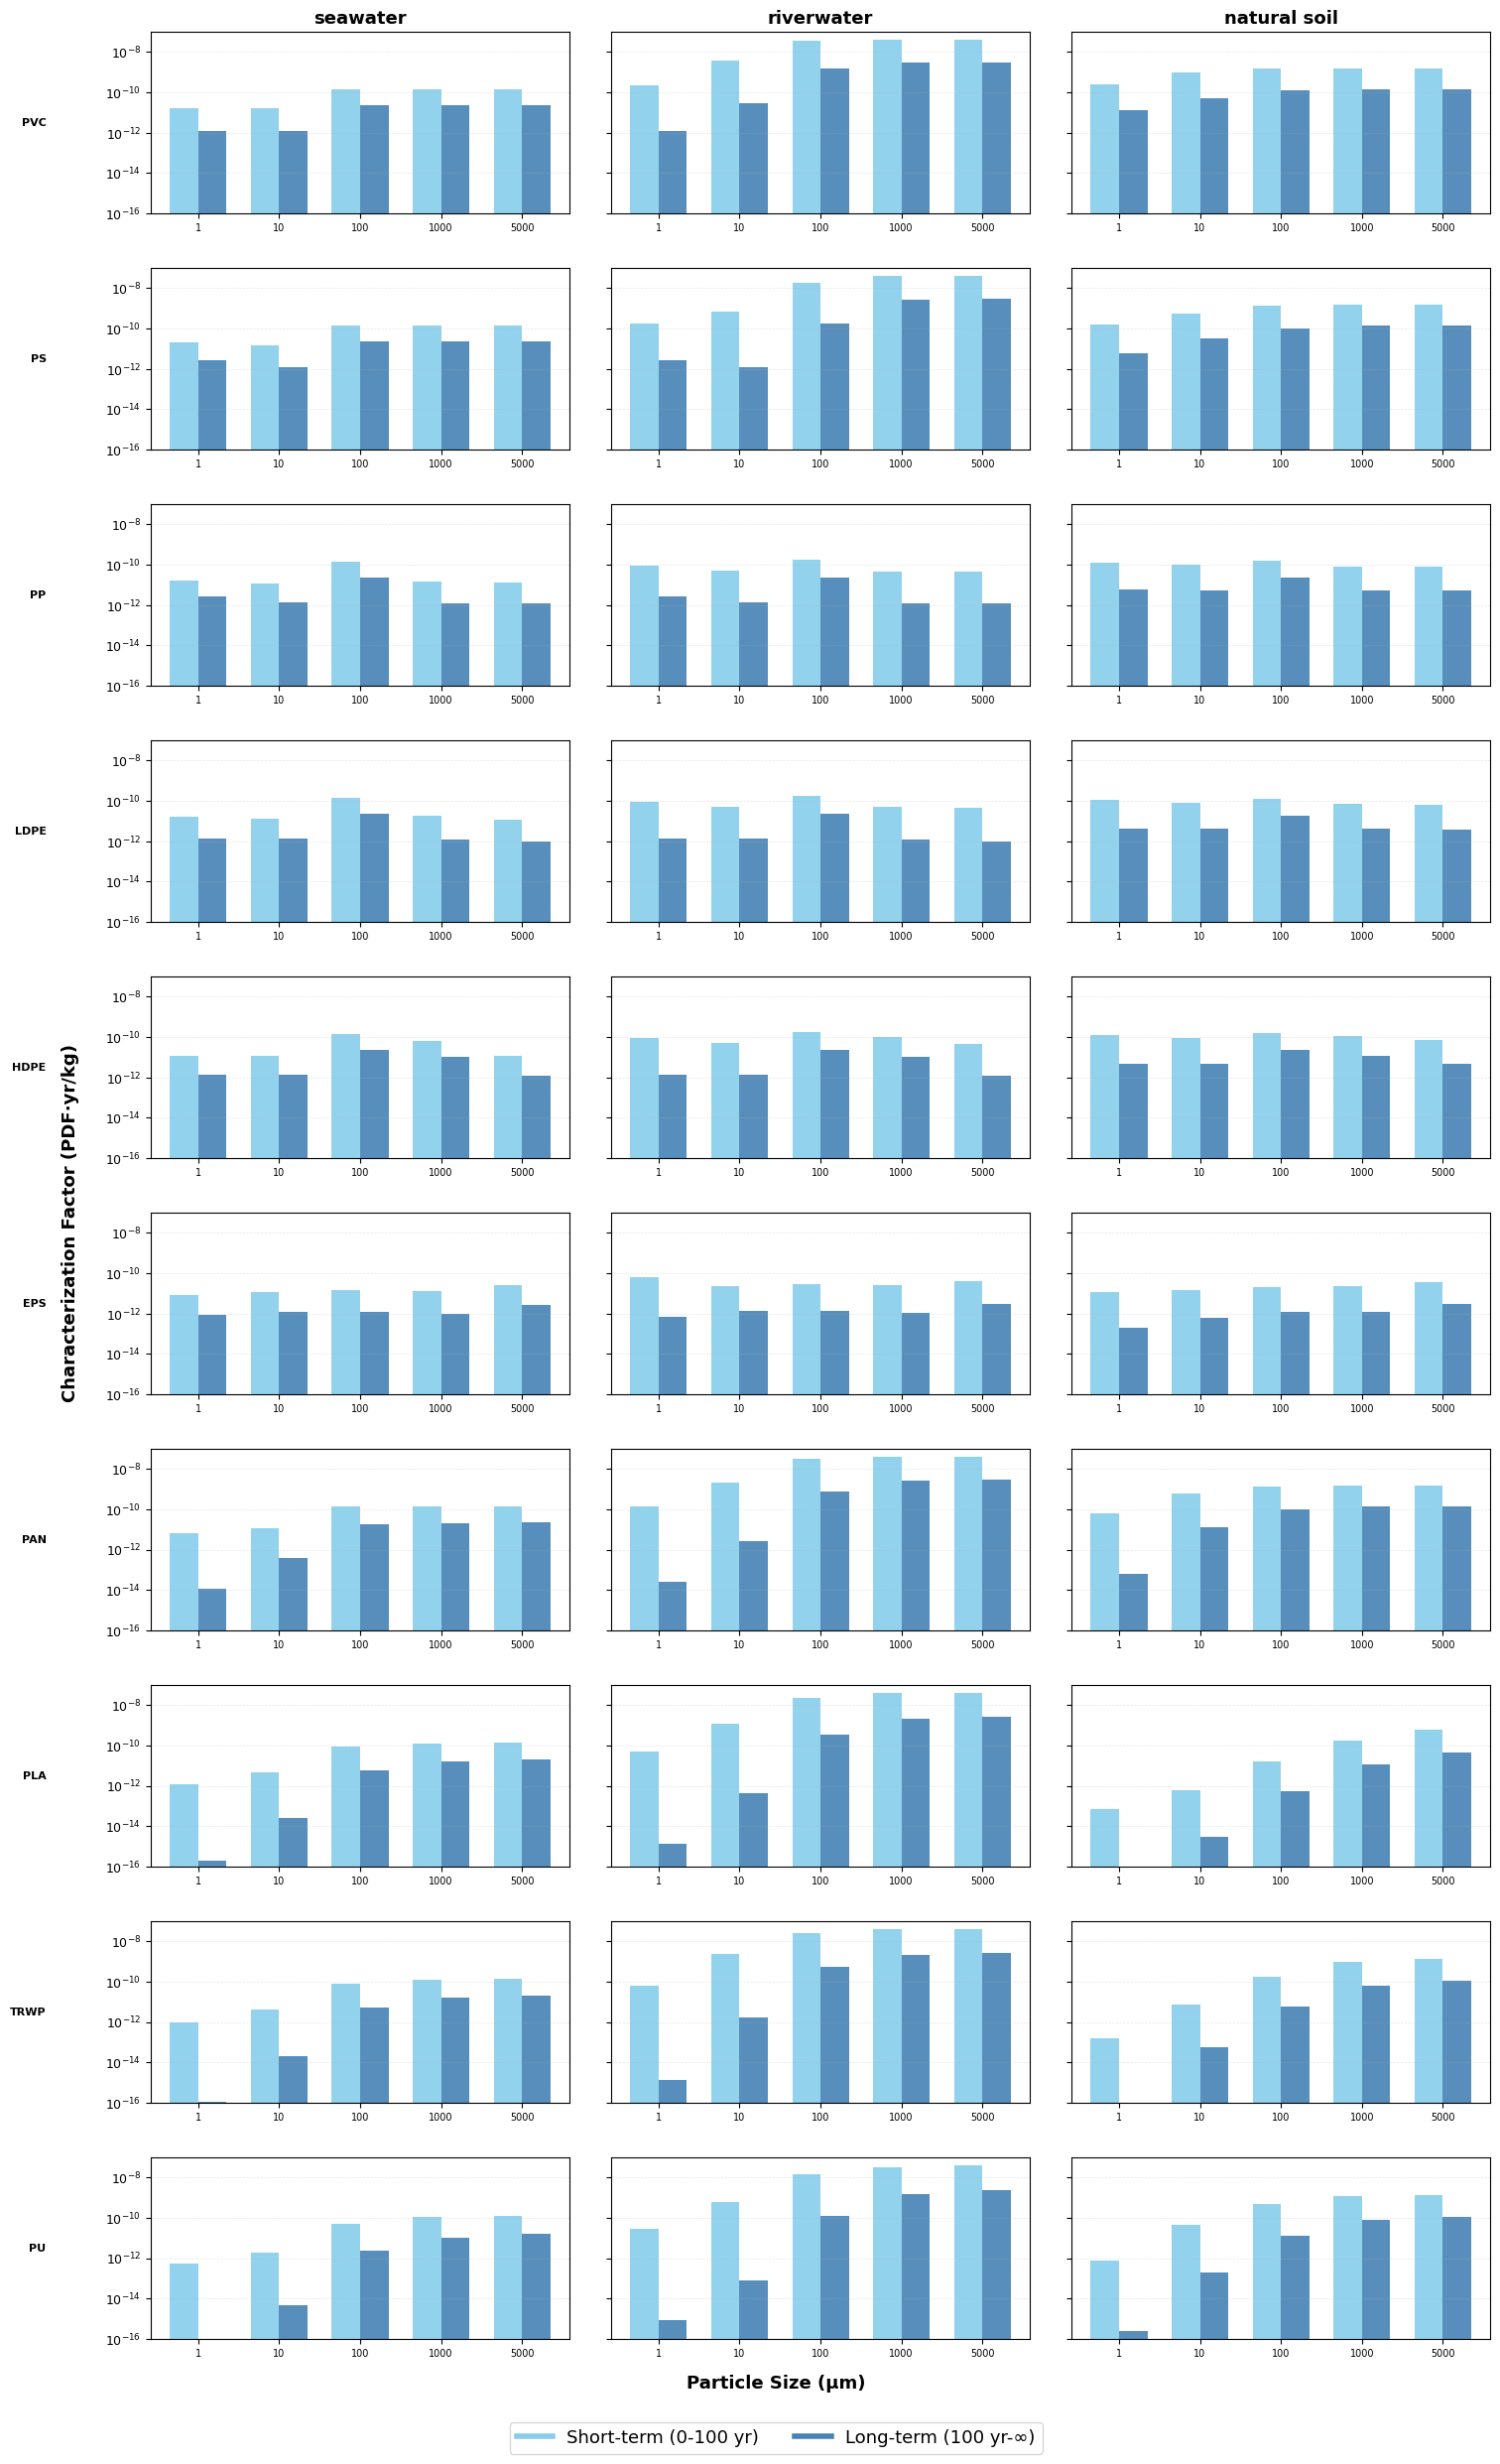

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os
from matplotlib.ticker import LogLocator

# Define paths
ss_path = "results/SI_C.xlsx"
short_term_path = "results/SI_D.xlsx"
path_graphs = "figures/"
sheet_name_ss = "CF_end_PDF_yr"  
sheet_name_st = "CF_end_PDF_yr_100_yrs"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Read both Excel files
df_ss = pd.read_excel(ss_path, sheet_name=sheet_name_ss)
df_st = pd.read_excel(short_term_path, sheet_name=sheet_name_st)

# Polymers to remove (Linen, Viscose, Rayon, Modal)
polymers_to_remove = ["Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#for subgraphs
#polymers_to_remove = ["HDPE","PVC","LDPE","PS","PP","EPS","PAN","PLA","TRWP","PU", "Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
polymers_to_remove = ["PBSA","PET","PA_Nylon","PBAT","PCL","Cotton","Lyocell","PHA","starch_blend","Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]



# Apply filters to both dataframes
filtered_ss = df_ss[
    (df_ss['size'].isin(size_filter)) & 
    (df_ss['shape'].isin(shape_filter)) &
    (df_ss['region'] == region_filter) &
    (df_ss['emission_compartment'].isin(emission_compartments)) &
    (~df_ss['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_st = df_st[
    (df_st['size'].isin(size_filter)) & 
    (df_st['shape'].isin(shape_filter)) &
    (df_st['region'] == region_filter) &
    (df_st['emission_compartment'].isin(emission_compartments)) &
    (~df_st['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_ss = filtered_ss[~filtered_ss['elementary_flowname'].str.contains('default', case=False, na=False)]
filtered_st = filtered_st[~filtered_st['elementary_flowname'].str.contains('default', case=False, na=False)]

# Sort polymers by minimum marine CF for continental seawater surface
seawater_ss = filtered_ss[filtered_ss['emission_compartment'] == 'continental seawater surface']
seawater_st = filtered_st[filtered_st['emission_compartment'] == 'continental seawater surface']

# Calculate min marine CF for each polymer (using steady-state data, or whichever you prefer)
marine_min = seawater_ss.groupby('polymer')['marine_geom_mean'].min()

# Sort polymers by this value
sorted_polymers = marine_min.sort_values().index.tolist()

# Filter to only include polymers that have complete data
polymers_with_data = [p for p in sorted_polymers if p in filtered_ss['polymer'].unique() 
                      and p in filtered_st['polymer'].unique()]

polymers_with_data = polymers_with_data[::-1]  # Reverse the order


print(f"Found {len(polymers_with_data)} polymers with data (sorted by marine CF)")

# Set up the plot
fig, axes = plt.subplots(nrows=len(polymers_with_data), ncols=len(emission_compartments), 
                         figsize=(15, 2.5*len(polymers_with_data)),  # Adjust height per row
                         sharey='row')  # Share y-axis within each row for better comparison

# Ensure axes is 2D
if len(polymers_with_data) == 1:
    axes = axes.reshape(1, -1)
if len(emission_compartments) == 1:
    axes = axes.reshape(-1, 1)

# Colors for short-term and steady-state (more distinct)
colors = {'short_term': '#87CEEB', 'long_term': '#4682B4'}  # Light blue and dark blue

# Width of bars
bar_width = 0.35

# Loop through polymers (rows) and emission compartments (columns)
for i, polymer in enumerate(polymers_with_data):
    row_axes = []          # store axes in this row
    row_min_lower = []     # collect lower bounds for this row
    row_max_upper = []     # collect upper bounds for this row
    
    for j, compartment in enumerate(emission_compartments):
        ax = axes[i, j]
        row_axes.append(ax)
        
        # Get data for this polymer and compartment
        ss_data = filtered_ss[
            (filtered_ss['polymer'] == polymer) & 
            (filtered_ss['emission_compartment'] == compartment)
        ].sort_values('size')
        
        st_data = filtered_st[
            (filtered_st['polymer'] == polymer) & 
            (filtered_st['emission_compartment'] == compartment)
        ].sort_values('size')
        
        # Get sizes for x-axis positions
        sizes = ss_data['size'].values
        x_pos = np.arange(len(sizes))
        
        # Plot bars if data exists for all sizes
        if len(ss_data) == len(size_filter) and len(st_data) == len(size_filter):
            # Calculate long-term values and propagated errors - OPTION 2 (RELATIVE ERRORS)
            ss_geom = ss_data['total_geom_mean'].values
            st_geom = st_data['total_geom_mean'].values
            lt_geom = ss_geom - st_geom
            lt_geom = np.maximum(lt_geom, 0)  # Ensure non-negative
            
            # Calculate relative errors
            # Avoid division by zero by adding small epsilon where needed
            epsilon = 1e-30
            
            # Relative errors for steady-state
            ss_rel_lower = (ss_geom - ss_data['total_ll_95'].values) / (ss_geom + epsilon)
            ss_rel_upper = (ss_data['total_ul_95'].values - ss_geom) / (ss_geom + epsilon)
            
            # Relative errors for short-term
            st_rel_lower = (st_geom - st_data['total_ll_95'].values) / (st_geom + epsilon)
            st_rel_upper = (st_data['total_ul_95'].values - st_geom) / (st_geom + epsilon)
            
            # Propagate relative errors (add in quadrature)
            lt_rel_lower = np.sqrt(ss_rel_lower**2 + st_rel_lower**2)
            lt_rel_upper = np.sqrt(ss_rel_upper**2 + st_rel_upper**2)
            
            # Convert back to absolute errors for plotting
            # For values near zero, use a small offset to avoid division issues
            lt_geom_safe = np.where(lt_geom > epsilon, lt_geom, epsilon)
            
            lt_lower_err = lt_geom_safe * lt_rel_lower
            lt_upper_err = lt_geom_safe * lt_rel_upper
            
            # Calculate confidence limits for long-term
            lt_ll = lt_geom - lt_lower_err
            lt_ul = lt_geom + lt_upper_err
            
            
            
            # Collect error bar extremes for row-wise limit calculation
            #row_min_lower.append(st_data['total_ll_95'].min())
            #row_min_lower.append(ss_data['total_ll_95'].min())
            #row_min_lower.append(lt_lower_err.min())
            #row_max_upper.append(st_data['total_ul_95'].max())
            #row_max_upper.append(ss_data['total_ul_95'].max())
            row_min_lower.append(st_data['total_geom_mean'].min())
            row_min_lower.append(lt_geom.min())
            row_max_upper.append(st_data['total_geom_mean'].max())
            row_max_upper.append(lt_geom.max())
            
            # Short-term bars (left)
            ax.bar(x_pos - bar_width/2, st_data['total_geom_mean'].values, 
                   bar_width, color=colors['short_term'],
                   #yerr=[st_data['total_geom_mean'].values - st_data['total_ll_95'].values,
                   #      st_data['total_ul_95'].values - st_data['total_geom_mean'].values],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # long-term bars (right)
            #ax.bar(x_pos + bar_width/2, ss_data['total_geom_mean'].values, 
            #       bar_width, color=colors['steady_state'],
            #       yerr=[ss_data['total_geom_mean'].values - ss_data['total_ll_95'].values,
            #             ss_data['total_ul_95'].values - ss_data['total_geom_mean'].values],
            #       capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)

            # Long-term bars (right) - using calculated lt_geom and propagated errors
            ax.bar(x_pos + bar_width/2, lt_geom, 
                   bar_width, color=colors['long_term'],
                   #yerr=[lt_lower_err, lt_upper_err],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # Set y-axis to log scale
            ax.set_yscale('log')
        else:
            # Show placeholder for missing data
            ax.text(0.5, 0.5, 'Incomplete data', ha='center', va='center', 
                   transform=ax.transAxes, fontsize=8, style='italic')
            ax.set_yscale('log')
        
        # Format x-axis
        ax.set_xticks(x_pos if len(ss_data) == len(size_filter) else [])
        ax.set_xticklabels([str(s) for s in size_filter] if len(ss_data) == len(size_filter) else [], 
                          fontsize=7)
        
        # Only show y-axis labels and ticks for first column
        if j == 0:
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        
        # Set subplot title for first row only (emission compartments)
        if i == 0:
            # Clean up compartment name for title
            clean_title = compartment.replace('continental ', '').replace(' surface', '')
            ax.set_title(f'{clean_title}', fontsize=13, fontweight='bold')
        
        # Add polymer name as row label on the left (outside the plot)
        if j == 0:
            ax.annotate(polymer, xy=(-0.25, 0.5), xycoords='axes fraction',
                       ha='right', va='center', fontsize=8, fontweight='bold')
        
        # Add grid for better readability
        ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    
    # After plotting all compartments for this polymer, set consistent y-limits for the entire row
    if row_min_lower and row_max_upper:  # Check if we collected any values
        # Get the overall min lower and max upper for the row
        row_min = max(min(row_min_lower),1e-15)
        row_max = max(row_max_upper)
        
        # Add padding on log scale (0.15 in log10 ≈ 40% margin)
        # Make sure values are positive for log scale
        if row_min > 0 and row_max > 0:
            y_min = 10 ** (np.log10(row_min) - 0.15)
            y_max = 10 ** (np.log10(row_max) + 0.15)
            
            # Apply same limits to all axes in this row
            for ax in row_axes:
                ax.set_ylim(1e-16, 1e-7)
                ax.yaxis.set_minor_locator(LogLocator(base=10, subs=[]))  # No minor ticks


# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Characterization Factor (PDF·yr/kg)', va='center', 
         rotation='vertical', fontsize=13, fontweight='bold')

# Add x-axis label at the bottom
fig.text(0.5, 0.03, 'Particle Size (μm)', ha='center', fontsize=13, fontweight='bold')

# Add legend
handles = [Line2D([0], [0], color=colors['short_term'], lw=4, label='Short-term (0-100 yr)'),
           Line2D([0], [0], color=colors['long_term'], lw=4, label='Long-term (100 yr-∞)')]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.00), 
          ncol=2, fontsize=13, frameon=True, fancybox=True, shadow=False)

# Adjust layout
plt.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.05, hspace=0.3, wspace=0.1)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.17_GLAM_a.pdf'), 
            bbox_inches='tight')

plt.show()

Found 9 polymers with data (sorted by marine CF)


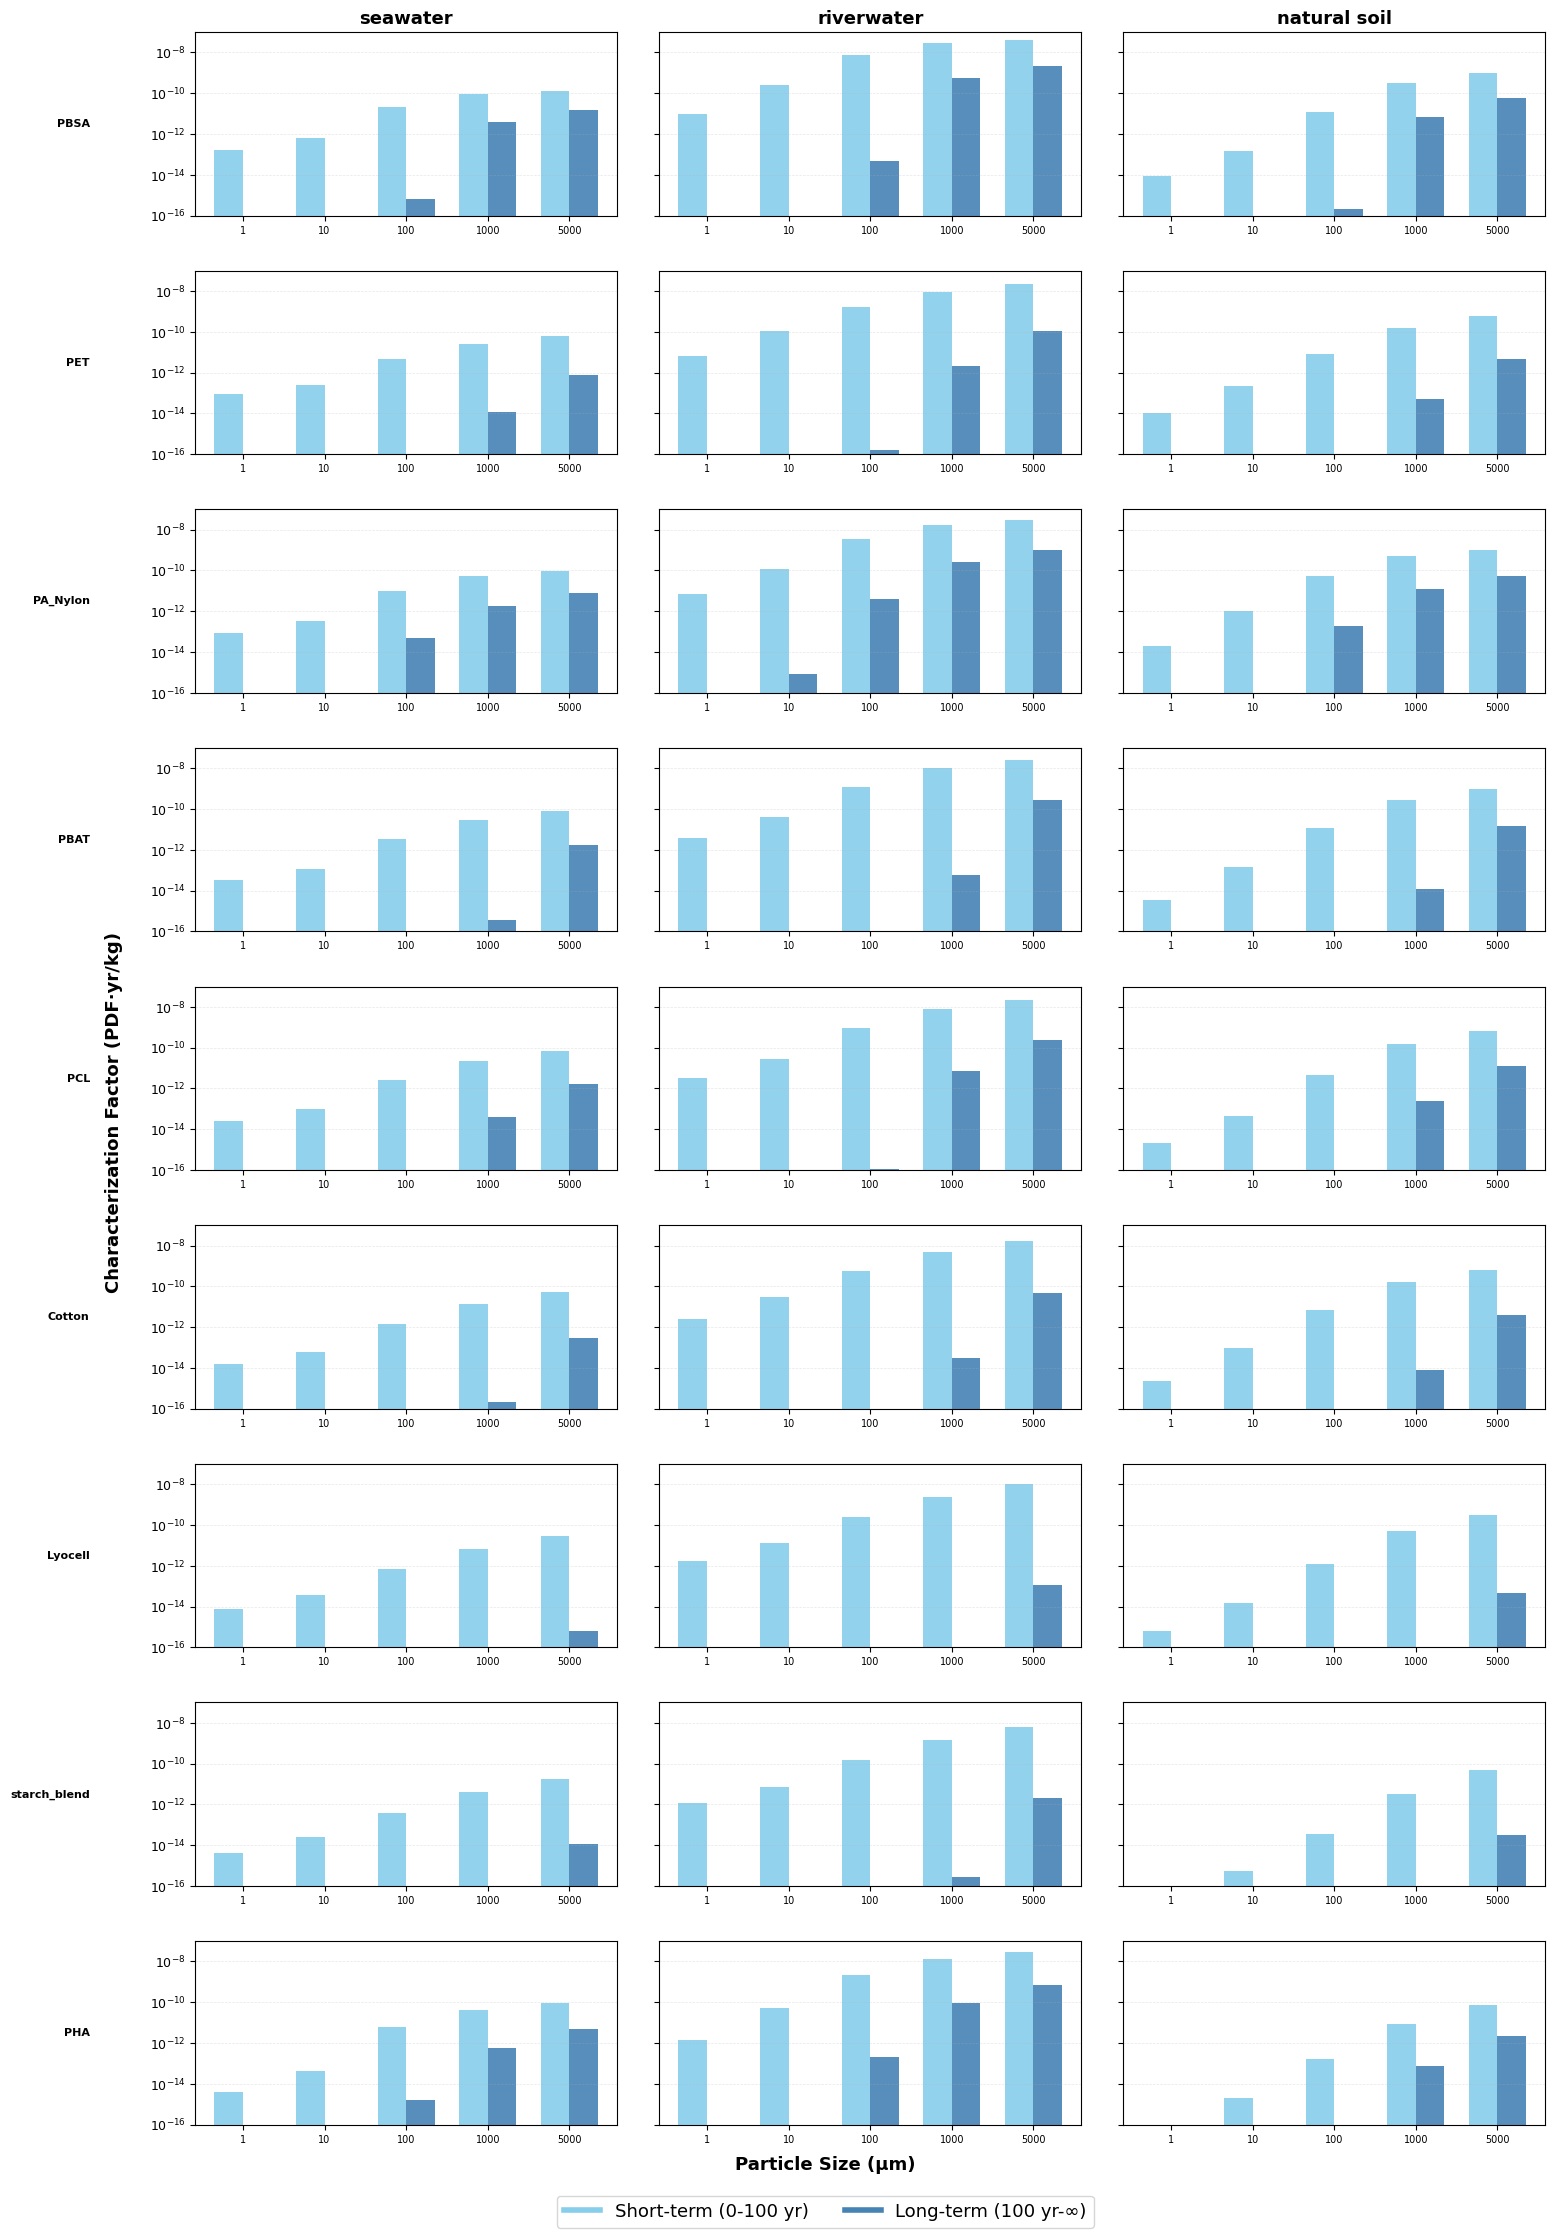

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os
from matplotlib.ticker import LogLocator

# Define paths
ss_path = "results/SI_C.xlsx"
short_term_path = "results/SI_D.xlsx"
path_graphs = "figures/"
sheet_name_ss = "CF_end_PDF_yr"  
sheet_name_st = "CF_end_PDF_yr_100_yrs"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Read both Excel files
df_ss = pd.read_excel(ss_path, sheet_name=sheet_name_ss)
df_st = pd.read_excel(short_term_path, sheet_name=sheet_name_st)

# Polymers to remove (Linen, Viscose, Rayon, Modal)
polymers_to_remove = ["Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#for subgraphs
polymers_to_remove = ["HDPE","PVC","LDPE","PS","PP","EPS","PAN","PLA","TRWP","PU", "Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#polymers_to_remove = ["PBSA","PET","PA_Nylon","PBAT","PCL","Cotton","Lyocell","PHA","starch_blend","Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]



# Apply filters to both dataframes
filtered_ss = df_ss[
    (df_ss['size'].isin(size_filter)) & 
    (df_ss['shape'].isin(shape_filter)) &
    (df_ss['region'] == region_filter) &
    (df_ss['emission_compartment'].isin(emission_compartments)) &
    (~df_ss['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_st = df_st[
    (df_st['size'].isin(size_filter)) & 
    (df_st['shape'].isin(shape_filter)) &
    (df_st['region'] == region_filter) &
    (df_st['emission_compartment'].isin(emission_compartments)) &
    (~df_st['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_ss = filtered_ss[~filtered_ss['elementary_flowname'].str.contains('default', case=False, na=False)]
filtered_st = filtered_st[~filtered_st['elementary_flowname'].str.contains('default', case=False, na=False)]

# Sort polymers by minimum marine CF for continental seawater surface
seawater_ss = filtered_ss[filtered_ss['emission_compartment'] == 'continental seawater surface']
seawater_st = filtered_st[filtered_st['emission_compartment'] == 'continental seawater surface']

# Calculate min marine CF for each polymer (using steady-state data, or whichever you prefer)
marine_min = seawater_ss.groupby('polymer')['marine_geom_mean'].min()

# Sort polymers by this value
sorted_polymers = marine_min.sort_values().index.tolist()

# Filter to only include polymers that have complete data
polymers_with_data = [p for p in sorted_polymers if p in filtered_ss['polymer'].unique() 
                      and p in filtered_st['polymer'].unique()]

polymers_with_data = polymers_with_data[::-1]  # Reverse the order


print(f"Found {len(polymers_with_data)} polymers with data (sorted by marine CF)")

# Set up the plot
fig, axes = plt.subplots(nrows=len(polymers_with_data), ncols=len(emission_compartments), 
                         figsize=(15, 2.5*len(polymers_with_data)),  # Adjust height per row
                         sharey='row')  # Share y-axis within each row for better comparison

# Ensure axes is 2D
if len(polymers_with_data) == 1:
    axes = axes.reshape(1, -1)
if len(emission_compartments) == 1:
    axes = axes.reshape(-1, 1)

# Colors for short-term and steady-state (more distinct)
colors = {'short_term': '#87CEEB', 'long_term': '#4682B4'}  # Light blue and dark blue

# Width of bars
bar_width = 0.35

# Loop through polymers (rows) and emission compartments (columns)
for i, polymer in enumerate(polymers_with_data):
    row_axes = []          # store axes in this row
    row_min_lower = []     # collect lower bounds for this row
    row_max_upper = []     # collect upper bounds for this row
    
    for j, compartment in enumerate(emission_compartments):
        ax = axes[i, j]
        row_axes.append(ax)
        
        # Get data for this polymer and compartment
        ss_data = filtered_ss[
            (filtered_ss['polymer'] == polymer) & 
            (filtered_ss['emission_compartment'] == compartment)
        ].sort_values('size')
        
        st_data = filtered_st[
            (filtered_st['polymer'] == polymer) & 
            (filtered_st['emission_compartment'] == compartment)
        ].sort_values('size')
        
        # Get sizes for x-axis positions
        sizes = ss_data['size'].values
        x_pos = np.arange(len(sizes))
        
        # Plot bars if data exists for all sizes
        if len(ss_data) == len(size_filter) and len(st_data) == len(size_filter):
            # Calculate long-term values and propagated errors - OPTION 2 (RELATIVE ERRORS)
            ss_geom = ss_data['total_geom_mean'].values
            st_geom = st_data['total_geom_mean'].values
            lt_geom = ss_geom - st_geom
            lt_geom = np.maximum(lt_geom, 0)  # Ensure non-negative
            
            # Calculate relative errors
            # Avoid division by zero by adding small epsilon where needed
            epsilon = 1e-30
            
            # Relative errors for steady-state
            ss_rel_lower = (ss_geom - ss_data['total_ll_95'].values) / (ss_geom + epsilon)
            ss_rel_upper = (ss_data['total_ul_95'].values - ss_geom) / (ss_geom + epsilon)
            
            # Relative errors for short-term
            st_rel_lower = (st_geom - st_data['total_ll_95'].values) / (st_geom + epsilon)
            st_rel_upper = (st_data['total_ul_95'].values - st_geom) / (st_geom + epsilon)
            
            # Propagate relative errors (add in quadrature)
            lt_rel_lower = np.sqrt(ss_rel_lower**2 + st_rel_lower**2)
            lt_rel_upper = np.sqrt(ss_rel_upper**2 + st_rel_upper**2)
            
            # Convert back to absolute errors for plotting
            # For values near zero, use a small offset to avoid division issues
            lt_geom_safe = np.where(lt_geom > epsilon, lt_geom, epsilon)
            
            lt_lower_err = lt_geom_safe * lt_rel_lower
            lt_upper_err = lt_geom_safe * lt_rel_upper
            
            # Calculate confidence limits for long-term
            lt_ll = lt_geom - lt_lower_err
            lt_ul = lt_geom + lt_upper_err
            
            
            
            # Collect error bar extremes for row-wise limit calculation
            #row_min_lower.append(st_data['total_ll_95'].min())
            #row_min_lower.append(ss_data['total_ll_95'].min())
            #row_min_lower.append(lt_lower_err.min())
            #row_max_upper.append(st_data['total_ul_95'].max())
            #row_max_upper.append(ss_data['total_ul_95'].max())
            row_min_lower.append(st_data['total_geom_mean'].min())
            row_min_lower.append(lt_geom.min())
            row_max_upper.append(st_data['total_geom_mean'].max())
            row_max_upper.append(lt_geom.max())
            
            # Short-term bars (left)
            ax.bar(x_pos - bar_width/2, st_data['total_geom_mean'].values, 
                   bar_width, color=colors['short_term'],
                   #yerr=[st_data['total_geom_mean'].values - st_data['total_ll_95'].values,
                   #      st_data['total_ul_95'].values - st_data['total_geom_mean'].values],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # long-term bars (right)
            #ax.bar(x_pos + bar_width/2, ss_data['total_geom_mean'].values, 
            #       bar_width, color=colors['steady_state'],
            #       yerr=[ss_data['total_geom_mean'].values - ss_data['total_ll_95'].values,
            #             ss_data['total_ul_95'].values - ss_data['total_geom_mean'].values],
            #       capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)

            # Long-term bars (right) - using calculated lt_geom and propagated errors
            ax.bar(x_pos + bar_width/2, lt_geom, 
                   bar_width, color=colors['long_term'],
                   #yerr=[lt_lower_err, lt_upper_err],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # Set y-axis to log scale
            ax.set_yscale('log')
        else:
            # Show placeholder for missing data
            ax.text(0.5, 0.5, 'Incomplete data', ha='center', va='center', 
                   transform=ax.transAxes, fontsize=8, style='italic')
            ax.set_yscale('log')
        
        # Format x-axis
        ax.set_xticks(x_pos if len(ss_data) == len(size_filter) else [])
        ax.set_xticklabels([str(s) for s in size_filter] if len(ss_data) == len(size_filter) else [], 
                          fontsize=7)
        
        # Only show y-axis labels and ticks for first column
        if j == 0:
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        
        # Set subplot title for first row only (emission compartments)
        if i == 0:
            # Clean up compartment name for title
            clean_title = compartment.replace('continental ', '').replace(' surface', '')
            ax.set_title(f'{clean_title}', fontsize=13, fontweight='bold')
        
        # Add polymer name as row label on the left (outside the plot)
        if j == 0:
            ax.annotate(polymer, xy=(-0.25, 0.5), xycoords='axes fraction',
                       ha='right', va='center', fontsize=8, fontweight='bold')
        
        # Add grid for better readability
        ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    
    # After plotting all compartments for this polymer, set consistent y-limits for the entire row
    if row_min_lower and row_max_upper:  # Check if we collected any values
        # Get the overall min lower and max upper for the row
        row_min = max(min(row_min_lower),1e-15)
        row_max = max(row_max_upper)
        
        # Add padding on log scale (0.15 in log10 ≈ 40% margin)
        # Make sure values are positive for log scale
        if row_min > 0 and row_max > 0:
            y_min = 10 ** (np.log10(row_min) - 0.15)
            y_max = 10 ** (np.log10(row_max) + 0.15)
            
            # Apply same limits to all axes in this row
            for ax in row_axes:
                ax.set_ylim(1e-16, 1e-7)
                ax.yaxis.set_minor_locator(LogLocator(base=10, subs=[]))  # No minor ticks


# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Characterization Factor (PDF·yr/kg)', va='center', 
         rotation='vertical', fontsize=13, fontweight='bold')

# Add x-axis label at the bottom
fig.text(0.5, 0.03, 'Particle Size (μm)', ha='center', fontsize=13, fontweight='bold')

# Add legend
handles = [Line2D([0], [0], color=colors['short_term'], lw=4, label='Short-term (0-100 yr)'),
           Line2D([0], [0], color=colors['long_term'], lw=4, label='Long-term (100 yr-∞)')]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.00), 
          ncol=2, fontsize=13, frameon=True, fancybox=True, shadow=False)

# Adjust layout
plt.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.05, hspace=0.3, wspace=0.1)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.17_GLAM_b.pdf'), 
            bbox_inches='tight')

plt.show()

Found 10 polymers with data (sorted by marine CF)


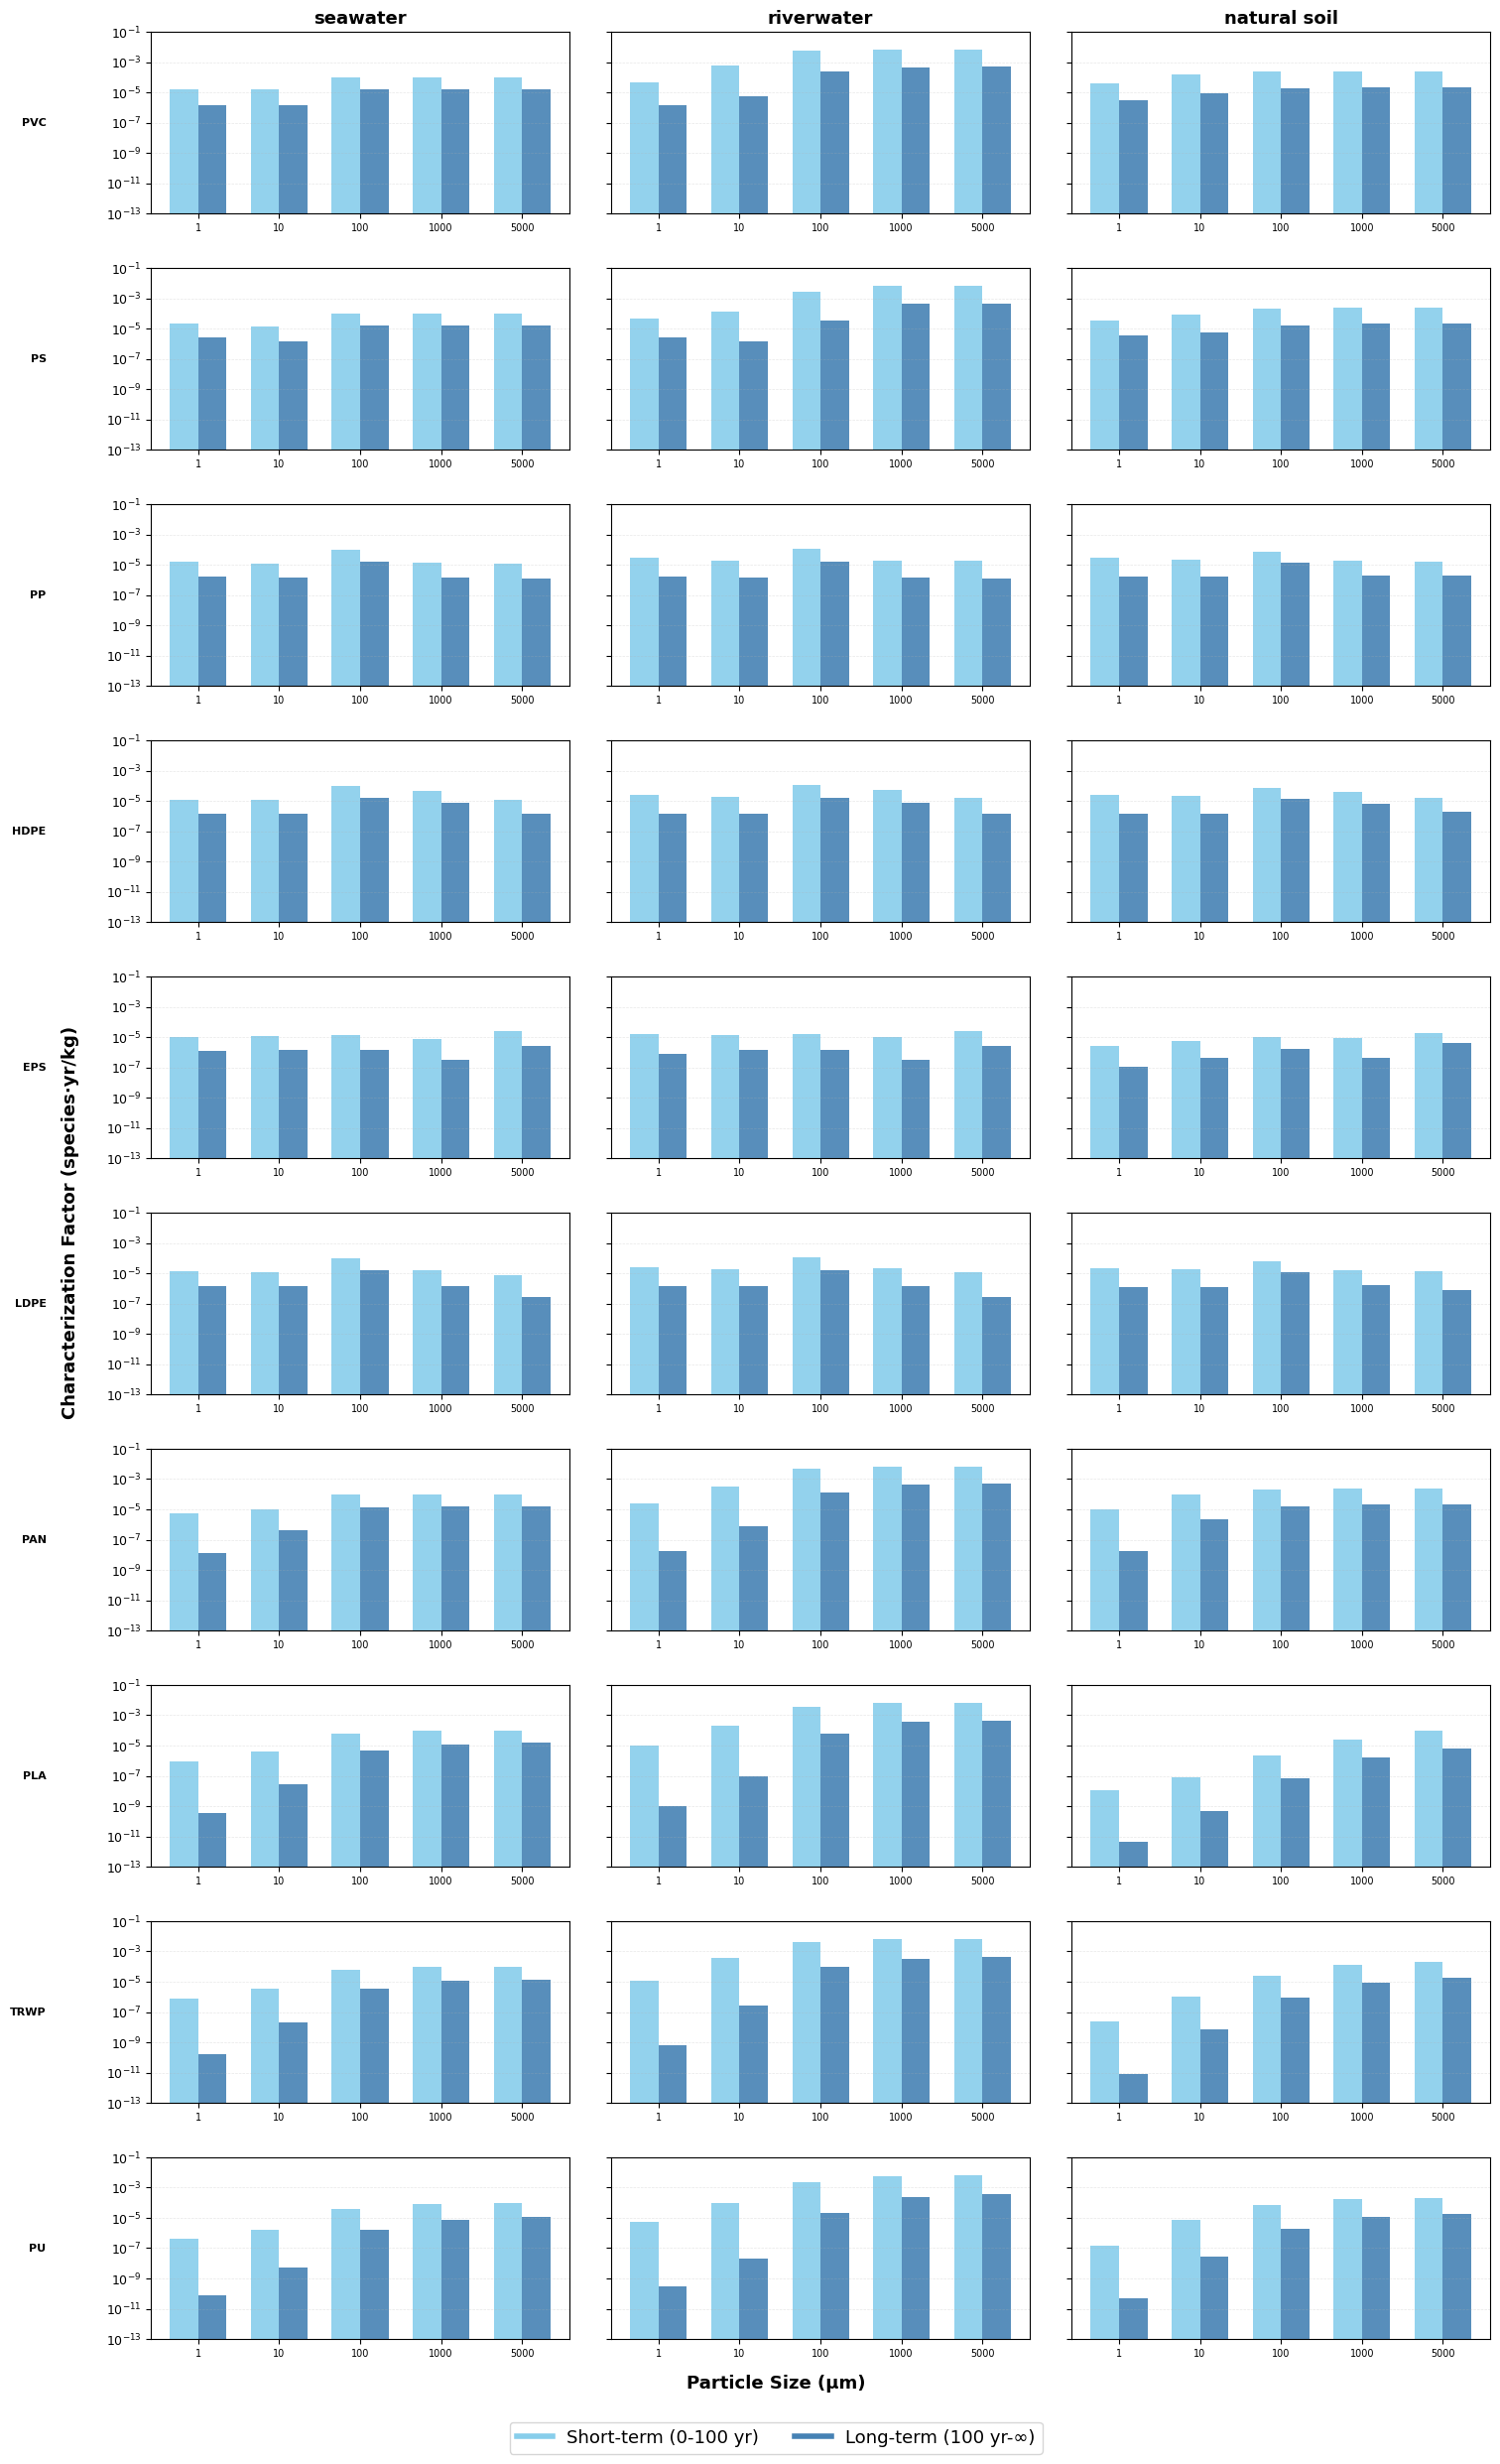

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os
from matplotlib.ticker import LogLocator

# Define paths
ss_path = "results/SI_C.xlsx"
short_term_path = "results/SI_D.xlsx"
path_graphs = "figures/"
sheet_name_ss = "CF_end_species_yr"  
sheet_name_st = "CF_end_species_yr_100_yrs"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Read both Excel files
df_ss = pd.read_excel(ss_path, sheet_name=sheet_name_ss)
df_st = pd.read_excel(short_term_path, sheet_name=sheet_name_st)

# Polymers to remove (Linen, Viscose, Rayon, Modal)
polymers_to_remove = ["Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#for subgraphs
#polymers_to_remove = ["HDPE","PVC","LDPE","PS","PP","EPS","PAN","PLA","TRWP","PU", "Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
polymers_to_remove = ["PBSA","PET","PA_Nylon","PBAT","PCL","Cotton","Lyocell","PHA","starch_blend","Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]




# Apply filters to both dataframes
filtered_ss = df_ss[
    (df_ss['size'].isin(size_filter)) & 
    (df_ss['shape'].isin(shape_filter)) &
    (df_ss['region'] == region_filter) &
    (df_ss['emission_compartment'].isin(emission_compartments)) &
    (~df_ss['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_st = df_st[
    (df_st['size'].isin(size_filter)) & 
    (df_st['shape'].isin(shape_filter)) &
    (df_st['region'] == region_filter) &
    (df_st['emission_compartment'].isin(emission_compartments)) &
    (~df_st['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_ss = filtered_ss[~filtered_ss['elementary_flowname'].str.contains('default', case=False, na=False)]
filtered_st = filtered_st[~filtered_st['elementary_flowname'].str.contains('default', case=False, na=False)]

# Sort polymers by minimum marine CF for continental seawater surface
seawater_ss = filtered_ss[filtered_ss['emission_compartment'] == 'continental seawater surface']
seawater_st = filtered_st[filtered_st['emission_compartment'] == 'continental seawater surface']

# Calculate min marine CF for each polymer (using steady-state data, or whichever you prefer)
marine_min = seawater_ss.groupby('polymer')['marine_geom_mean'].min()

# Sort polymers by this value
sorted_polymers = marine_min.sort_values().index.tolist()

# Filter to only include polymers that have complete data
polymers_with_data = [p for p in sorted_polymers if p in filtered_ss['polymer'].unique() 
                      and p in filtered_st['polymer'].unique()]

polymers_with_data = polymers_with_data[::-1]  # Reverse the order


print(f"Found {len(polymers_with_data)} polymers with data (sorted by marine CF)")

# Set up the plot
fig, axes = plt.subplots(nrows=len(polymers_with_data), ncols=len(emission_compartments), 
                         figsize=(15, 2.5*len(polymers_with_data)),  # Adjust height per row
                         sharey='row')  # Share y-axis within each row for better comparison

# Ensure axes is 2D
if len(polymers_with_data) == 1:
    axes = axes.reshape(1, -1)
if len(emission_compartments) == 1:
    axes = axes.reshape(-1, 1)

# Colors for short-term and steady-state (more distinct)
colors = {'short_term': '#87CEEB', 'long_term': '#4682B4'}  # Light blue and dark blue

# Width of bars
bar_width = 0.35

# Loop through polymers (rows) and emission compartments (columns)
for i, polymer in enumerate(polymers_with_data):
    row_axes = []          # store axes in this row
    row_min_lower = []     # collect lower bounds for this row
    row_max_upper = []     # collect upper bounds for this row
    
    for j, compartment in enumerate(emission_compartments):
        ax = axes[i, j]
        row_axes.append(ax)
        
        # Get data for this polymer and compartment
        ss_data = filtered_ss[
            (filtered_ss['polymer'] == polymer) & 
            (filtered_ss['emission_compartment'] == compartment)
        ].sort_values('size')
        
        st_data = filtered_st[
            (filtered_st['polymer'] == polymer) & 
            (filtered_st['emission_compartment'] == compartment)
        ].sort_values('size')
        
        # Get sizes for x-axis positions
        sizes = ss_data['size'].values
        x_pos = np.arange(len(sizes))
        
        # Plot bars if data exists for all sizes
        if len(ss_data) == len(size_filter) and len(st_data) == len(size_filter):
            # Calculate long-term values and propagated errors - OPTION 2 (RELATIVE ERRORS)
            ss_geom = ss_data['total_geom_mean'].values
            st_geom = st_data['total_geom_mean'].values
            lt_geom = ss_geom - st_geom
            lt_geom = np.maximum(lt_geom, 0)  # Ensure non-negative
            
            # Calculate relative errors
            # Avoid division by zero by adding small epsilon where needed
            epsilon = 1e-30
            
            # Relative errors for steady-state
            ss_rel_lower = (ss_geom - ss_data['total_ll_95'].values) / (ss_geom + epsilon)
            ss_rel_upper = (ss_data['total_ul_95'].values - ss_geom) / (ss_geom + epsilon)
            
            # Relative errors for short-term
            st_rel_lower = (st_geom - st_data['total_ll_95'].values) / (st_geom + epsilon)
            st_rel_upper = (st_data['total_ul_95'].values - st_geom) / (st_geom + epsilon)
            
            # Propagate relative errors (add in quadrature)
            lt_rel_lower = np.sqrt(ss_rel_lower**2 + st_rel_lower**2)
            lt_rel_upper = np.sqrt(ss_rel_upper**2 + st_rel_upper**2)
            
            # Convert back to absolute errors for plotting
            # For values near zero, use a small offset to avoid division issues
            lt_geom_safe = np.where(lt_geom > epsilon, lt_geom, epsilon)
            
            lt_lower_err = lt_geom_safe * lt_rel_lower
            lt_upper_err = lt_geom_safe * lt_rel_upper
            
            # Calculate confidence limits for long-term
            lt_ll = lt_geom - lt_lower_err
            lt_ul = lt_geom + lt_upper_err
            
            
            
            # Collect error bar extremes for row-wise limit calculation
            #row_min_lower.append(st_data['total_ll_95'].min())
            #row_min_lower.append(ss_data['total_ll_95'].min())
            #row_min_lower.append(lt_lower_err.min())
            #row_max_upper.append(st_data['total_ul_95'].max())
            #row_max_upper.append(ss_data['total_ul_95'].max())
            row_min_lower.append(st_data['total_geom_mean'].min())
            row_min_lower.append(lt_geom.min())
            row_max_upper.append(st_data['total_geom_mean'].max())
            row_max_upper.append(lt_geom.max())
            
            # Short-term bars (left)
            ax.bar(x_pos - bar_width/2, st_data['total_geom_mean'].values, 
                   bar_width, color=colors['short_term'],
                   #yerr=[st_data['total_geom_mean'].values - st_data['total_ll_95'].values,
                   #      st_data['total_ul_95'].values - st_data['total_geom_mean'].values],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # long-term bars (right)
            #ax.bar(x_pos + bar_width/2, ss_data['total_geom_mean'].values, 
            #       bar_width, color=colors['steady_state'],
            #       yerr=[ss_data['total_geom_mean'].values - ss_data['total_ll_95'].values,
            #             ss_data['total_ul_95'].values - ss_data['total_geom_mean'].values],
            #       capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)

            # Long-term bars (right) - using calculated lt_geom and propagated errors
            ax.bar(x_pos + bar_width/2, lt_geom, 
                   bar_width, color=colors['long_term'],
                   #yerr=[lt_lower_err, lt_upper_err],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # Set y-axis to log scale
            ax.set_yscale('log')
        else:
            # Show placeholder for missing data
            ax.text(0.5, 0.5, 'Incomplete data', ha='center', va='center', 
                   transform=ax.transAxes, fontsize=8, style='italic')
            ax.set_yscale('log')
        
        # Format x-axis
        ax.set_xticks(x_pos if len(ss_data) == len(size_filter) else [])
        ax.set_xticklabels([str(s) for s in size_filter] if len(ss_data) == len(size_filter) else [], 
                          fontsize=7)
        
        # Only show y-axis labels and ticks for first column
        if j == 0:
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        
        # Set subplot title for first row only (emission compartments)
        if i == 0:
            # Clean up compartment name for title
            clean_title = compartment.replace('continental ', '').replace(' surface', '')
            ax.set_title(f'{clean_title}', fontsize=13, fontweight='bold')
        
        # Add polymer name as row label on the left (outside the plot)
        if j == 0:
            ax.annotate(polymer, xy=(-0.25, 0.5), xycoords='axes fraction',
                       ha='right', va='center', fontsize=8, fontweight='bold')
        
        # Add grid for better readability
        ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    
    # After plotting all compartments for this polymer, set consistent y-limits for the entire row
    if row_min_lower and row_max_upper:  # Check if we collected any values
        # Get the overall min lower and max upper for the row
        row_min = max(min(row_min_lower),1e-15)
        row_max = max(row_max_upper)
        
        # Add padding on log scale (0.15 in log10 ≈ 40% margin)
        # Make sure values are positive for log scale
        if row_min > 0 and row_max > 0:
            y_min = 10 ** (np.log10(row_min) - 0.15)
            y_max = 10 ** (np.log10(row_max) + 0.15)
            
            # Apply same limits to all axes in this row
            for ax in row_axes:
                ax.set_ylim(1e-13, 1e-1)
                ax.yaxis.set_minor_locator(LogLocator(base=10, subs=[]))  # No minor ticks


# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Characterization Factor (species·yr/kg)', va='center', 
         rotation='vertical', fontsize=13, fontweight='bold')

# Add x-axis label at the bottom
fig.text(0.5, 0.03, 'Particle Size (μm)', ha='center', fontsize=13, fontweight='bold')

# Add legend
handles = [Line2D([0], [0], color=colors['short_term'], lw=4, label='Short-term (0-100 yr)'),
           Line2D([0], [0], color=colors['long_term'], lw=4, label='Long-term (100 yr-∞)')]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.00), 
          ncol=2, fontsize=13, frameon=True, fancybox=True, shadow=False)

# Adjust layout
plt.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.05, hspace=0.3, wspace=0.1)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.18_ReCiPe_a.pdf'), 
            bbox_inches='tight')

plt.show()

Found 9 polymers with data (sorted by marine CF)


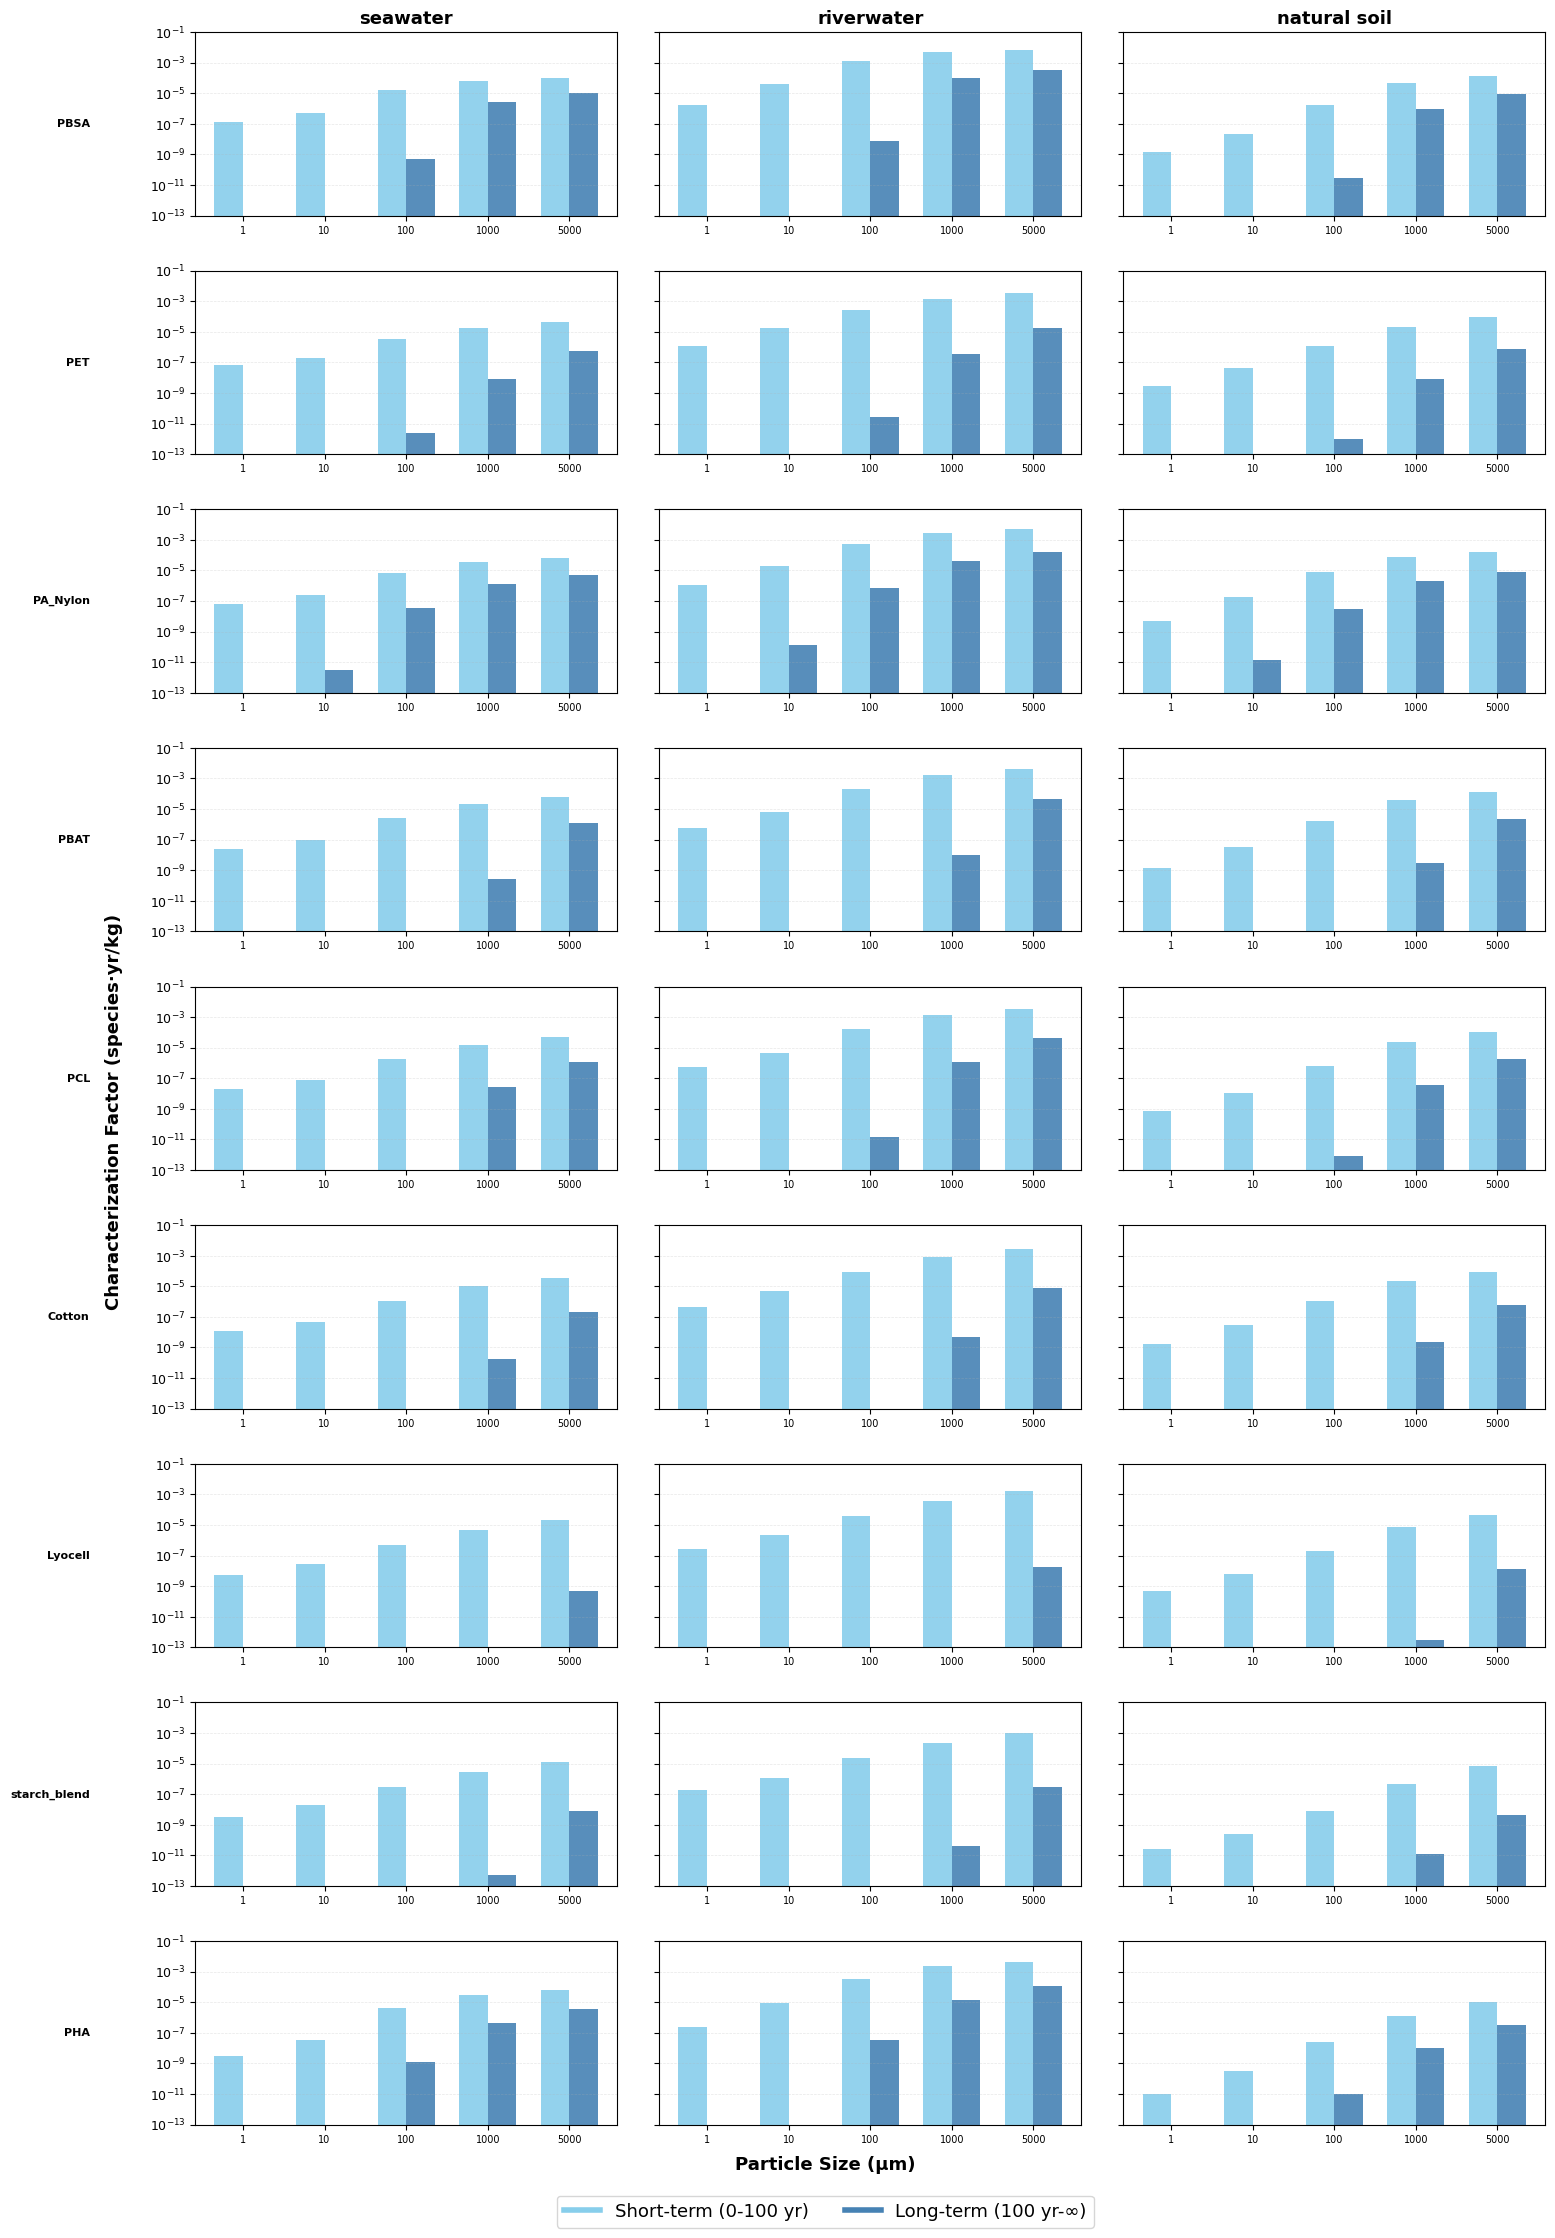

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os
from matplotlib.ticker import LogLocator

# Define paths
ss_path = "results/SI_C.xlsx"
short_term_path = "results/SI_D.xlsx"
path_graphs = "figures/"
sheet_name_ss = "CF_end_species_yr"  
sheet_name_st = "CF_end_species_yr_100_yrs"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
region_filter = "World"
emission_compartments = ["continental seawater surface", 
                         "continental riverwater", 
                         "continental natural soil"]

# Read both Excel files
df_ss = pd.read_excel(ss_path, sheet_name=sheet_name_ss)
df_st = pd.read_excel(short_term_path, sheet_name=sheet_name_st)

# Polymers to remove (Linen, Viscose, Rayon, Modal)
polymers_to_remove = ["Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#for subgraphs
polymers_to_remove = ["HDPE","PVC","LDPE","PS","PP","EPS","PAN","PLA","TRWP","PU", "Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]
#polymers_to_remove = ["PBSA","PET","PA_Nylon","PBAT","PCL","Cotton","Lyocell","PHA","starch_blend","Linen", "Viscose", "Rayon", "Modal","default_low_density","default_high_density","default_all_density"]




# Apply filters to both dataframes
filtered_ss = df_ss[
    (df_ss['size'].isin(size_filter)) & 
    (df_ss['shape'].isin(shape_filter)) &
    (df_ss['region'] == region_filter) &
    (df_ss['emission_compartment'].isin(emission_compartments)) &
    (~df_ss['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_st = df_st[
    (df_st['size'].isin(size_filter)) & 
    (df_st['shape'].isin(shape_filter)) &
    (df_st['region'] == region_filter) &
    (df_st['emission_compartment'].isin(emission_compartments)) &
    (~df_st['polymer'].isin(polymers_to_remove))  # Remove specified polymers
].copy()

filtered_ss = filtered_ss[~filtered_ss['elementary_flowname'].str.contains('default', case=False, na=False)]
filtered_st = filtered_st[~filtered_st['elementary_flowname'].str.contains('default', case=False, na=False)]

# Sort polymers by minimum marine CF for continental seawater surface
seawater_ss = filtered_ss[filtered_ss['emission_compartment'] == 'continental seawater surface']
seawater_st = filtered_st[filtered_st['emission_compartment'] == 'continental seawater surface']

# Calculate min marine CF for each polymer (using steady-state data, or whichever you prefer)
marine_min = seawater_ss.groupby('polymer')['marine_geom_mean'].min()

# Sort polymers by this value
sorted_polymers = marine_min.sort_values().index.tolist()

# Filter to only include polymers that have complete data
polymers_with_data = [p for p in sorted_polymers if p in filtered_ss['polymer'].unique() 
                      and p in filtered_st['polymer'].unique()]

polymers_with_data = polymers_with_data[::-1]  # Reverse the order


print(f"Found {len(polymers_with_data)} polymers with data (sorted by marine CF)")

# Set up the plot
fig, axes = plt.subplots(nrows=len(polymers_with_data), ncols=len(emission_compartments), 
                         figsize=(15, 2.5*len(polymers_with_data)),  # Adjust height per row
                         sharey='row')  # Share y-axis within each row for better comparison

# Ensure axes is 2D
if len(polymers_with_data) == 1:
    axes = axes.reshape(1, -1)
if len(emission_compartments) == 1:
    axes = axes.reshape(-1, 1)

# Colors for short-term and steady-state (more distinct)
colors = {'short_term': '#87CEEB', 'long_term': '#4682B4'}  # Light blue and dark blue

# Width of bars
bar_width = 0.35

# Loop through polymers (rows) and emission compartments (columns)
for i, polymer in enumerate(polymers_with_data):
    row_axes = []          # store axes in this row
    row_min_lower = []     # collect lower bounds for this row
    row_max_upper = []     # collect upper bounds for this row
    
    for j, compartment in enumerate(emission_compartments):
        ax = axes[i, j]
        row_axes.append(ax)
        
        # Get data for this polymer and compartment
        ss_data = filtered_ss[
            (filtered_ss['polymer'] == polymer) & 
            (filtered_ss['emission_compartment'] == compartment)
        ].sort_values('size')
        
        st_data = filtered_st[
            (filtered_st['polymer'] == polymer) & 
            (filtered_st['emission_compartment'] == compartment)
        ].sort_values('size')
        
        # Get sizes for x-axis positions
        sizes = ss_data['size'].values
        x_pos = np.arange(len(sizes))
        
        # Plot bars if data exists for all sizes
        if len(ss_data) == len(size_filter) and len(st_data) == len(size_filter):
            # Calculate long-term values and propagated errors - OPTION 2 (RELATIVE ERRORS)
            ss_geom = ss_data['total_geom_mean'].values
            st_geom = st_data['total_geom_mean'].values
            lt_geom = ss_geom - st_geom
            lt_geom = np.maximum(lt_geom, 0)  # Ensure non-negative
            
            # Calculate relative errors
            # Avoid division by zero by adding small epsilon where needed
            epsilon = 1e-30
            
            # Relative errors for steady-state
            ss_rel_lower = (ss_geom - ss_data['total_ll_95'].values) / (ss_geom + epsilon)
            ss_rel_upper = (ss_data['total_ul_95'].values - ss_geom) / (ss_geom + epsilon)
            
            # Relative errors for short-term
            st_rel_lower = (st_geom - st_data['total_ll_95'].values) / (st_geom + epsilon)
            st_rel_upper = (st_data['total_ul_95'].values - st_geom) / (st_geom + epsilon)
            
            # Propagate relative errors (add in quadrature)
            lt_rel_lower = np.sqrt(ss_rel_lower**2 + st_rel_lower**2)
            lt_rel_upper = np.sqrt(ss_rel_upper**2 + st_rel_upper**2)
            
            # Convert back to absolute errors for plotting
            # For values near zero, use a small offset to avoid division issues
            lt_geom_safe = np.where(lt_geom > epsilon, lt_geom, epsilon)
            
            lt_lower_err = lt_geom_safe * lt_rel_lower
            lt_upper_err = lt_geom_safe * lt_rel_upper
            
            # Calculate confidence limits for long-term
            lt_ll = lt_geom - lt_lower_err
            lt_ul = lt_geom + lt_upper_err
            
            
            
            # Collect error bar extremes for row-wise limit calculation
            #row_min_lower.append(st_data['total_ll_95'].min())
            #row_min_lower.append(ss_data['total_ll_95'].min())
            #row_min_lower.append(lt_lower_err.min())
            #row_max_upper.append(st_data['total_ul_95'].max())
            #row_max_upper.append(ss_data['total_ul_95'].max())
            row_min_lower.append(st_data['total_geom_mean'].min())
            row_min_lower.append(lt_geom.min())
            row_max_upper.append(st_data['total_geom_mean'].max())
            row_max_upper.append(lt_geom.max())
            
            # Short-term bars (left)
            ax.bar(x_pos - bar_width/2, st_data['total_geom_mean'].values, 
                   bar_width, color=colors['short_term'],
                   #yerr=[st_data['total_geom_mean'].values - st_data['total_ll_95'].values,
                   #      st_data['total_ul_95'].values - st_data['total_geom_mean'].values],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # long-term bars (right)
            #ax.bar(x_pos + bar_width/2, ss_data['total_geom_mean'].values, 
            #       bar_width, color=colors['steady_state'],
            #       yerr=[ss_data['total_geom_mean'].values - ss_data['total_ll_95'].values,
            #             ss_data['total_ul_95'].values - ss_data['total_geom_mean'].values],
            #       capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)

            # Long-term bars (right) - using calculated lt_geom and propagated errors
            ax.bar(x_pos + bar_width/2, lt_geom, 
                   bar_width, color=colors['long_term'],
                   #yerr=[lt_lower_err, lt_upper_err],
                   capsize=2, error_kw={'elinewidth': 0.5, 'ecolor': 'black'}, alpha=0.9)
            
            # Set y-axis to log scale
            ax.set_yscale('log')
        else:
            # Show placeholder for missing data
            ax.text(0.5, 0.5, 'Incomplete data', ha='center', va='center', 
                   transform=ax.transAxes, fontsize=8, style='italic')
            ax.set_yscale('log')
        
        # Format x-axis
        ax.set_xticks(x_pos if len(ss_data) == len(size_filter) else [])
        ax.set_xticklabels([str(s) for s in size_filter] if len(ss_data) == len(size_filter) else [], 
                          fontsize=7)
        
        # Only show y-axis labels and ticks for first column
        if j == 0:
            ax.tick_params(axis='y', labelsize=9)
        else:
            ax.tick_params(axis='y', labelleft=False)
        
        # Set subplot title for first row only (emission compartments)
        if i == 0:
            # Clean up compartment name for title
            clean_title = compartment.replace('continental ', '').replace(' surface', '')
            ax.set_title(f'{clean_title}', fontsize=13, fontweight='bold')
        
        # Add polymer name as row label on the left (outside the plot)
        if j == 0:
            ax.annotate(polymer, xy=(-0.25, 0.5), xycoords='axes fraction',
                       ha='right', va='center', fontsize=8, fontweight='bold')
        
        # Add grid for better readability
        ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    
    # After plotting all compartments for this polymer, set consistent y-limits for the entire row
    if row_min_lower and row_max_upper:  # Check if we collected any values
        # Get the overall min lower and max upper for the row
        row_min = max(min(row_min_lower),1e-15)
        row_max = max(row_max_upper)
        
        # Add padding on log scale (0.15 in log10 ≈ 40% margin)
        # Make sure values are positive for log scale
        if row_min > 0 and row_max > 0:
            y_min = 10 ** (np.log10(row_min) - 0.15)
            y_max = 10 ** (np.log10(row_max) + 0.15)
            
            # Apply same limits to all axes in this row
            for ax in row_axes:
                ax.set_ylim(1e-13, 1e-1)
                ax.yaxis.set_minor_locator(LogLocator(base=10, subs=[]))  # No minor ticks


# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Characterization Factor (species·yr/kg)', va='center', 
         rotation='vertical', fontsize=13, fontweight='bold')

# Add x-axis label at the bottom
fig.text(0.5, 0.03, 'Particle Size (μm)', ha='center', fontsize=13, fontweight='bold')

# Add legend
handles = [Line2D([0], [0], color=colors['short_term'], lw=4, label='Short-term (0-100 yr)'),
           Line2D([0], [0], color=colors['long_term'], lw=4, label='Long-term (100 yr-∞)')]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.00), 
          ncol=2, fontsize=13, frameon=True, fancybox=True, shadow=False)

# Adjust layout
plt.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.05, hspace=0.3, wspace=0.1)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.18_ReCiPe_b.pdf'), 
            bbox_inches='tight')

plt.show()

Global y-axis limits: 1.31e-01 to 2.14e+04


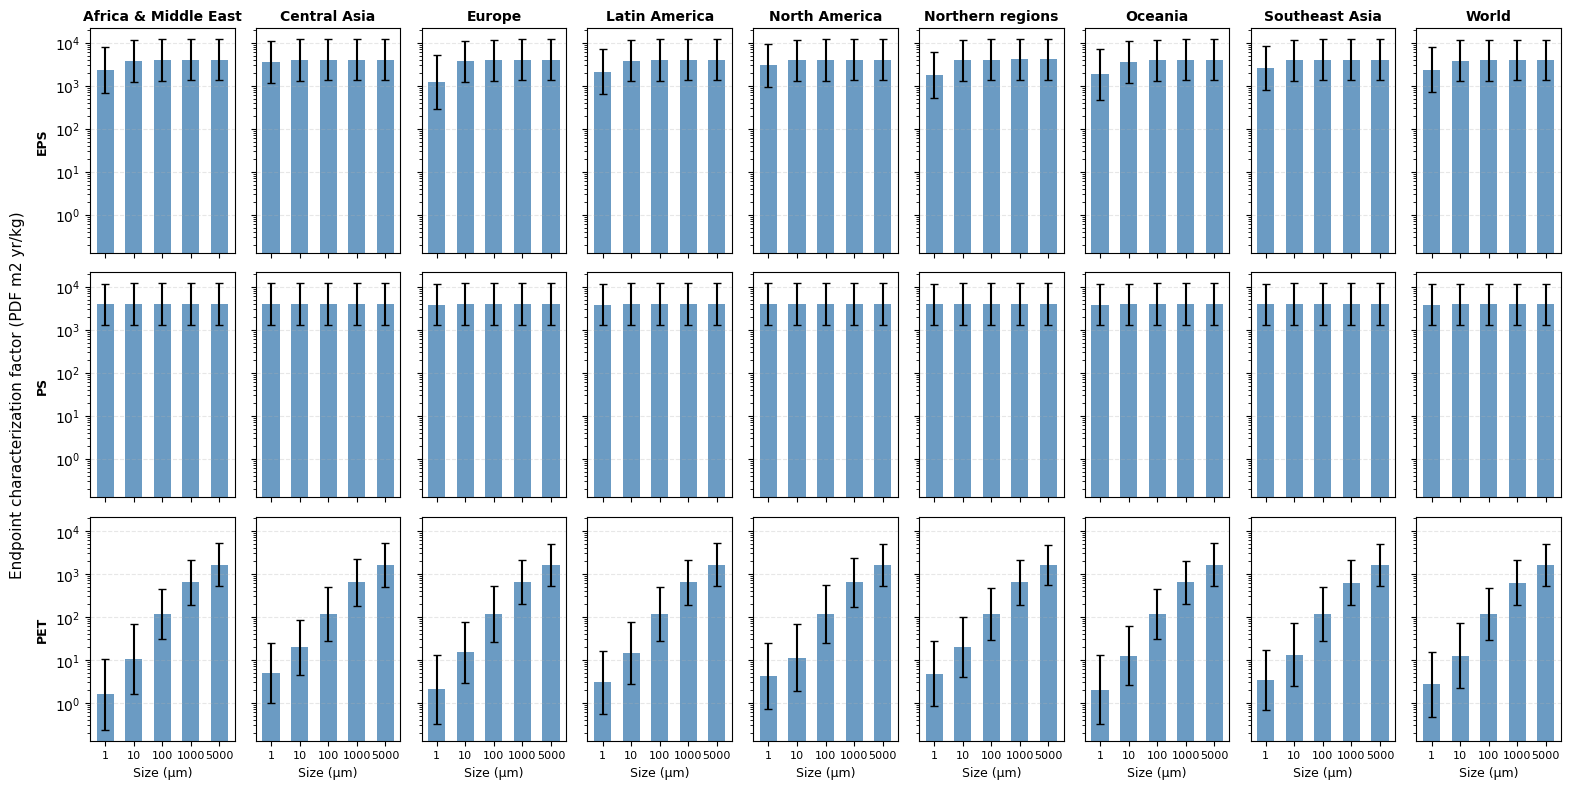

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Define paths
file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_name = "CF_end_PDF_m2_yr"  

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
emission_compartments = ["continental seawater surface"]
polymer_filter = ["EPS", "PS", "PET"]

# Read the data
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Apply filters (using emission_compartment as requested)
df_filtered = df[
    (df['size'].isin(size_filter)) &
    (df['shape'].isin(shape_filter)) &
    (df['emission_compartment'].isin(emission_compartments)) &
    (df['polymer'].isin(polymer_filter))
]

df_filtered = df_filtered[~df_filtered['elementary_flowname'].str.contains('default', case=False, na=False)]

# Get unique regions, polymers, and sort size
desired_order= ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 
                 'North America', 'Northern regions', 'Oceania', 'Southeast Asia','World']
#regions = sorted(df_filtered['region'].unique())
regions = [r for r in desired_order if r in df_filtered['region'].unique()]
polymers = polymer_filter  # Use the specified order
sizes = sorted(size_filter)
x_pos = np.arange(len(sizes))

# Calculate global y-axis limits based on all CFs including GSD ranges
all_values = []
for _, row in df_filtered.iterrows():
    mean_val = row['total_geom_mean']
    gsd = row['total_gsd']
    all_values.append(mean_val / gsd)  # Lower bound
    all_values.append(mean_val * gsd)  # Upper bound

y_min_global = min(all_values)
y_max_global = max(all_values)

# Add a little padding (half order of magnitude)
y_min_global = 10 ** (np.log10(y_min_global) - 0.25)
y_max_global = 10 ** (np.log10(y_max_global) + 0.25)

print(f"Global y-axis limits: {y_min_global:.2e} to {y_max_global:.2e}")

# Create figure with subplots
fig, axes = plt.subplots(nrows=len(polymers), ncols=len(regions), 
                         figsize=(16, 8), sharex=True, sharey=True)  # sharey=True for global y-axis

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot data as simple bar charts with GSD error bars
plot_idx = 0
for i, polymer in enumerate(polymers):
    for j, region in enumerate(regions):
        ax = axes[i, j]
        
        # Filter data for current polymer and region
        subset = df_filtered[
            (df_filtered['polymer'] == polymer) & 
            (df_filtered['region'] == region)
        ].sort_values('size')
        
        if not subset.empty:
            # Extract values
            values = subset['total_geom_mean'].values
            gsd_values = subset['total_gsd'].values
            
            # Calculate asymmetric error bars using GSD
            lower_error = values / gsd_values
            upper_error = values * gsd_values
            asymmetric_error = [values - lower_error, upper_error - values]
            
            # Simple bar chart
            bars = ax.bar(x_pos, values, width=0.6, color='steelblue', alpha=0.8)
            
            # Add GSD error bars
            ax.errorbar(x_pos, values, yerr=asymmetric_error, 
                       fmt='none', ecolor='black', capsize=3, capthick=1)
            
            # Set y-axis to log scale and apply global limits
            ax.set_yscale('log')
            ax.set_ylim(y_min_global, y_max_global)
        
        # Set x-axis ticks
        ax.set_xticks(x_pos)
        ax.set_xticklabels([str(s) for s in sizes], fontsize=8)
        
        # Add region label only for top row
        if i == 0:
            ax.set_title(region, fontsize=10, fontweight='bold')
        
        # Add polymer label only for first column
        if j == 0:
            ax.set_ylabel(f'{polymer}', fontsize=9, fontweight='bold')
        
        # Set x-axis label only for bottom row
        if i == len(polymers) - 1:
            ax.set_xlabel('Size (μm)', fontsize=9)
        
        # Simple grid
        ax.grid(True, axis='y', alpha=0.3, linestyle='--')
        
        plot_idx += 1

# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Endpoint characterization factor (PDF m2 yr/kg)', va='center', rotation='vertical', fontsize=11)

plt.tight_layout()
plt.subplots_adjust(left=0.07)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.11_IW+.pdf'), bbox_inches='tight')

plt.show()

Global y-axis limits: 2.12e-16 to 1.30e-09


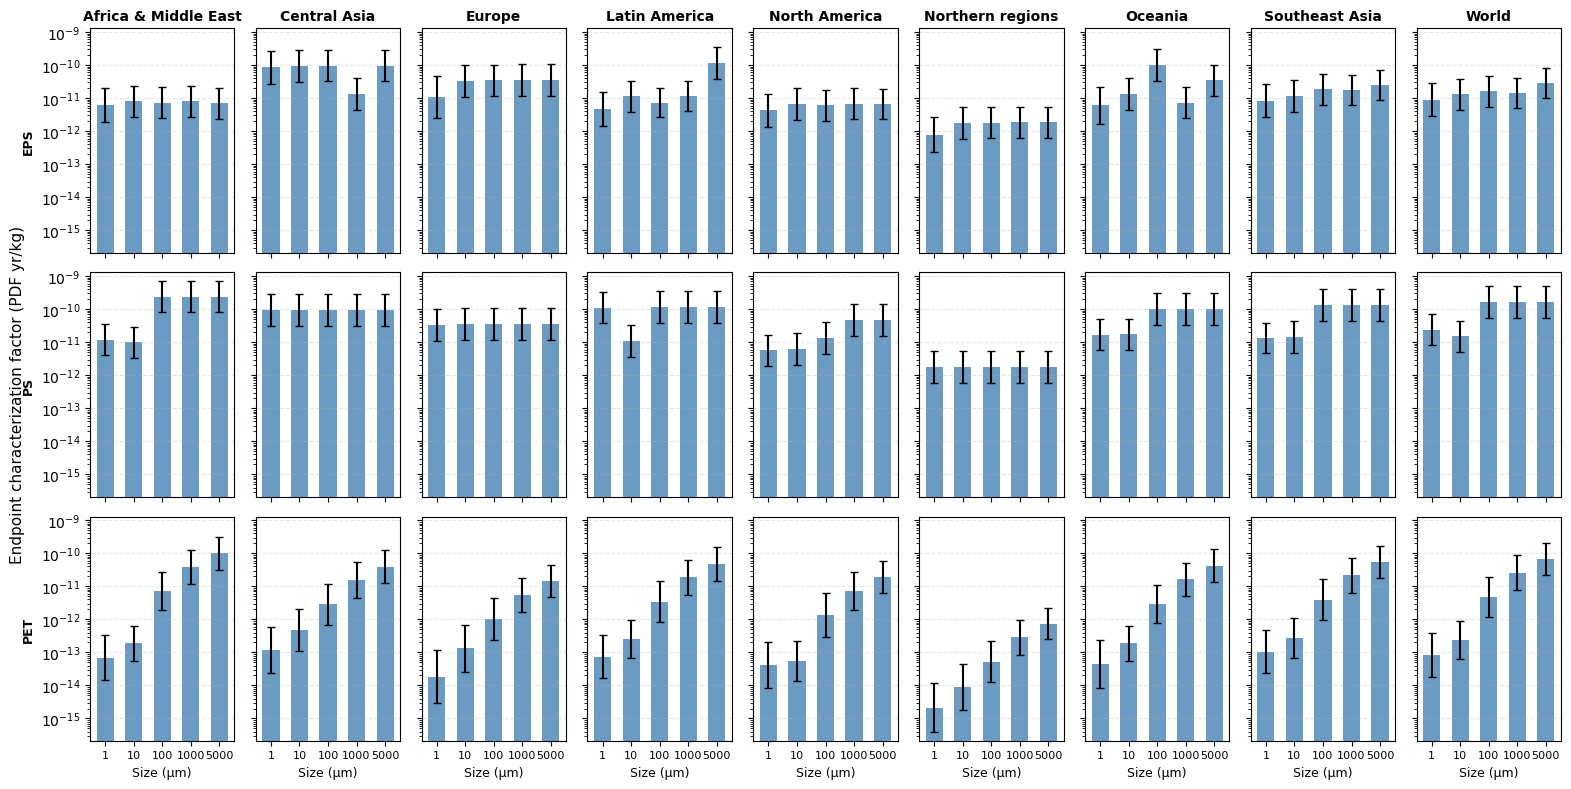

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Define paths
file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_name = "CF_end_PDF_yr"  

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
emission_compartments = ["continental seawater surface"]
polymer_filter = ["EPS", "PS", "PET"]

# Read the data
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Apply filters (using emission_compartment as requested)
df_filtered = df[
    (df['size'].isin(size_filter)) &
    (df['shape'].isin(shape_filter)) &
    (df['emission_compartment'].isin(emission_compartments)) &
    (df['polymer'].isin(polymer_filter))
]

df_filtered = df_filtered[~df_filtered['elementary_flowname'].str.contains('default', case=False, na=False)]

# Get unique regions, polymers, and sort size
desired_order= ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 
                 'North America', 'Northern regions', 'Oceania', 'Southeast Asia','World']
#regions = sorted(df_filtered['region'].unique())
regions = [r for r in desired_order if r in df_filtered['region'].unique()]
polymers = polymer_filter  # Use the specified order
sizes = sorted(size_filter)
x_pos = np.arange(len(sizes))

# Calculate global y-axis limits based on all CFs including GSD ranges
all_values = []
for _, row in df_filtered.iterrows():
    mean_val = row['total_geom_mean']
    gsd = row['total_gsd']
    all_values.append(mean_val / gsd)  # Lower bound
    all_values.append(mean_val * gsd)  # Upper bound

y_min_global = min(all_values)
y_max_global = max(all_values)

# Add a little padding (half order of magnitude)
y_min_global = 10 ** (np.log10(y_min_global) - 0.25)
y_max_global = 10 ** (np.log10(y_max_global) + 0.25)

print(f"Global y-axis limits: {y_min_global:.2e} to {y_max_global:.2e}")

# Create figure with subplots
fig, axes = plt.subplots(nrows=len(polymers), ncols=len(regions), 
                         figsize=(16, 8), sharex=True, sharey=True)  # sharey=True for global y-axis

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot data as simple bar charts with GSD error bars
plot_idx = 0
for i, polymer in enumerate(polymers):
    for j, region in enumerate(regions):
        ax = axes[i, j]
        
        # Filter data for current polymer and region
        subset = df_filtered[
            (df_filtered['polymer'] == polymer) & 
            (df_filtered['region'] == region)
        ].sort_values('size')
        
        if not subset.empty:
            # Extract values
            values = subset['total_geom_mean'].values
            gsd_values = subset['total_gsd'].values
            
            # Calculate asymmetric error bars using GSD
            lower_error = values / gsd_values
            upper_error = values * gsd_values
            asymmetric_error = [values - lower_error, upper_error - values]
            
            # Simple bar chart
            bars = ax.bar(x_pos, values, width=0.6, color='steelblue', alpha=0.8)
            
            # Add GSD error bars
            ax.errorbar(x_pos, values, yerr=asymmetric_error, 
                       fmt='none', ecolor='black', capsize=3, capthick=1)
            
            # Set y-axis to log scale and apply global limits
            ax.set_yscale('log')
            ax.set_ylim(y_min_global, y_max_global)
        
        # Set x-axis ticks
        ax.set_xticks(x_pos)
        ax.set_xticklabels([str(s) for s in sizes], fontsize=8)
        
        # Add region label only for top row
        if i == 0:
            ax.set_title(region, fontsize=10, fontweight='bold')
        
        # Add polymer label only for first column
        if j == 0:
            ax.set_ylabel(f'{polymer}', fontsize=9, fontweight='bold')
        
        # Set x-axis label only for bottom row
        if i == len(polymers) - 1:
            ax.set_xlabel('Size (μm)', fontsize=9)
        
        # Simple grid
        ax.grid(True, axis='y', alpha=0.3, linestyle='--')
        
        plot_idx += 1

# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Endpoint characterization factor (PDF yr/kg)', va='center', rotation='vertical', fontsize=11)

plt.tight_layout()
plt.subplots_adjust(left=0.07)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.12_GLAM.pdf'), bbox_inches='tight')

plt.show()

Global y-axis limits: 1.13e-09 to 2.28e-03


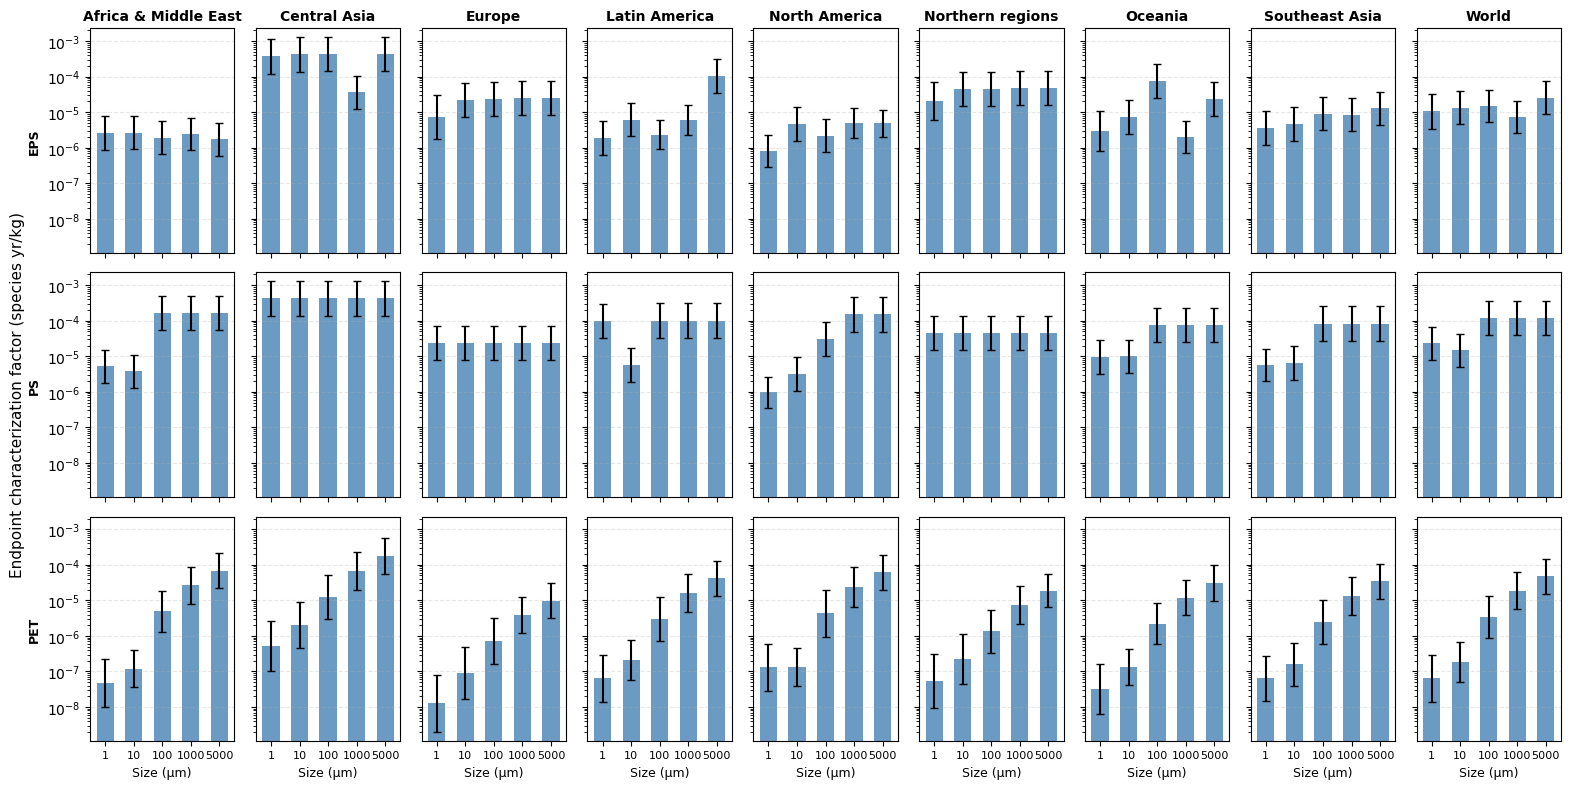

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Define paths
file_path = "results/SI_C.xlsx"
path_graphs = "figures/"
sheet_name = "CF_end_species_yr"  

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
emission_compartments = ["continental seawater surface"]
polymer_filter = ["EPS", "PS", "PET"]

# Read the data
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Apply filters (using emission_compartment as requested)
df_filtered = df[
    (df['size'].isin(size_filter)) &
    (df['shape'].isin(shape_filter)) &
    (df['emission_compartment'].isin(emission_compartments)) &
    (df['polymer'].isin(polymer_filter))
]

df_filtered = df_filtered[~df_filtered['elementary_flowname'].str.contains('default', case=False, na=False)]

# Get unique regions, polymers, and sort size
desired_order= ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 
                 'North America', 'Northern regions', 'Oceania', 'Southeast Asia','World']
#regions = sorted(df_filtered['region'].unique())
regions = [r for r in desired_order if r in df_filtered['region'].unique()]
polymers = polymer_filter  # Use the specified order
sizes = sorted(size_filter)
x_pos = np.arange(len(sizes))

# Calculate global y-axis limits based on all CFs including GSD ranges
all_values = []
for _, row in df_filtered.iterrows():
    mean_val = row['total_geom_mean']
    gsd = row['total_gsd']
    all_values.append(mean_val / gsd)  # Lower bound
    all_values.append(mean_val * gsd)  # Upper bound

y_min_global = min(all_values)
y_max_global = max(all_values)

# Add a little padding (half order of magnitude)
y_min_global = 10 ** (np.log10(y_min_global) - 0.25)
y_max_global = 10 ** (np.log10(y_max_global) + 0.25)

print(f"Global y-axis limits: {y_min_global:.2e} to {y_max_global:.2e}")

# Create figure with subplots
fig, axes = plt.subplots(nrows=len(polymers), ncols=len(regions), 
                         figsize=(16, 8), sharex=True, sharey=True)  # sharey=True for global y-axis

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot data as simple bar charts with GSD error bars
plot_idx = 0
for i, polymer in enumerate(polymers):
    for j, region in enumerate(regions):
        ax = axes[i, j]
        
        # Filter data for current polymer and region
        subset = df_filtered[
            (df_filtered['polymer'] == polymer) & 
            (df_filtered['region'] == region)
        ].sort_values('size')
        
        if not subset.empty:
            # Extract values
            values = subset['total_geom_mean'].values
            gsd_values = subset['total_gsd'].values
            
            # Calculate asymmetric error bars using GSD
            lower_error = values / gsd_values
            upper_error = values * gsd_values
            asymmetric_error = [values - lower_error, upper_error - values]
            
            # Simple bar chart
            bars = ax.bar(x_pos, values, width=0.6, color='steelblue', alpha=0.8)
            
            # Add GSD error bars
            ax.errorbar(x_pos, values, yerr=asymmetric_error, 
                       fmt='none', ecolor='black', capsize=3, capthick=1)
            
            # Set y-axis to log scale and apply global limits
            ax.set_yscale('log')
            ax.set_ylim(y_min_global, y_max_global)
        
        # Set x-axis ticks
        ax.set_xticks(x_pos)
        ax.set_xticklabels([str(s) for s in sizes], fontsize=8)
        
        # Add region label only for top row
        if i == 0:
            ax.set_title(region, fontsize=10, fontweight='bold')
        
        # Add polymer label only for first column
        if j == 0:
            ax.set_ylabel(f'{polymer}', fontsize=9, fontweight='bold')
        
        # Set x-axis label only for bottom row
        if i == len(polymers) - 1:
            ax.set_xlabel('Size (μm)', fontsize=9)
        
        # Simple grid
        ax.grid(True, axis='y', alpha=0.3, linestyle='--')
        
        plot_idx += 1

# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Endpoint characterization factor (species yr/kg)', va='center', rotation='vertical', fontsize=11)

plt.tight_layout()
plt.subplots_adjust(left=0.07)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.13_ReCiPe.pdf'), bbox_inches='tight')

plt.show()

Global y-axis limits: 1.79e-08 to 3.80e-05
Number of data points: 240
Regions found: ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 'North America', 'Northern regions', 'Oceania', 'Southeast Asia']


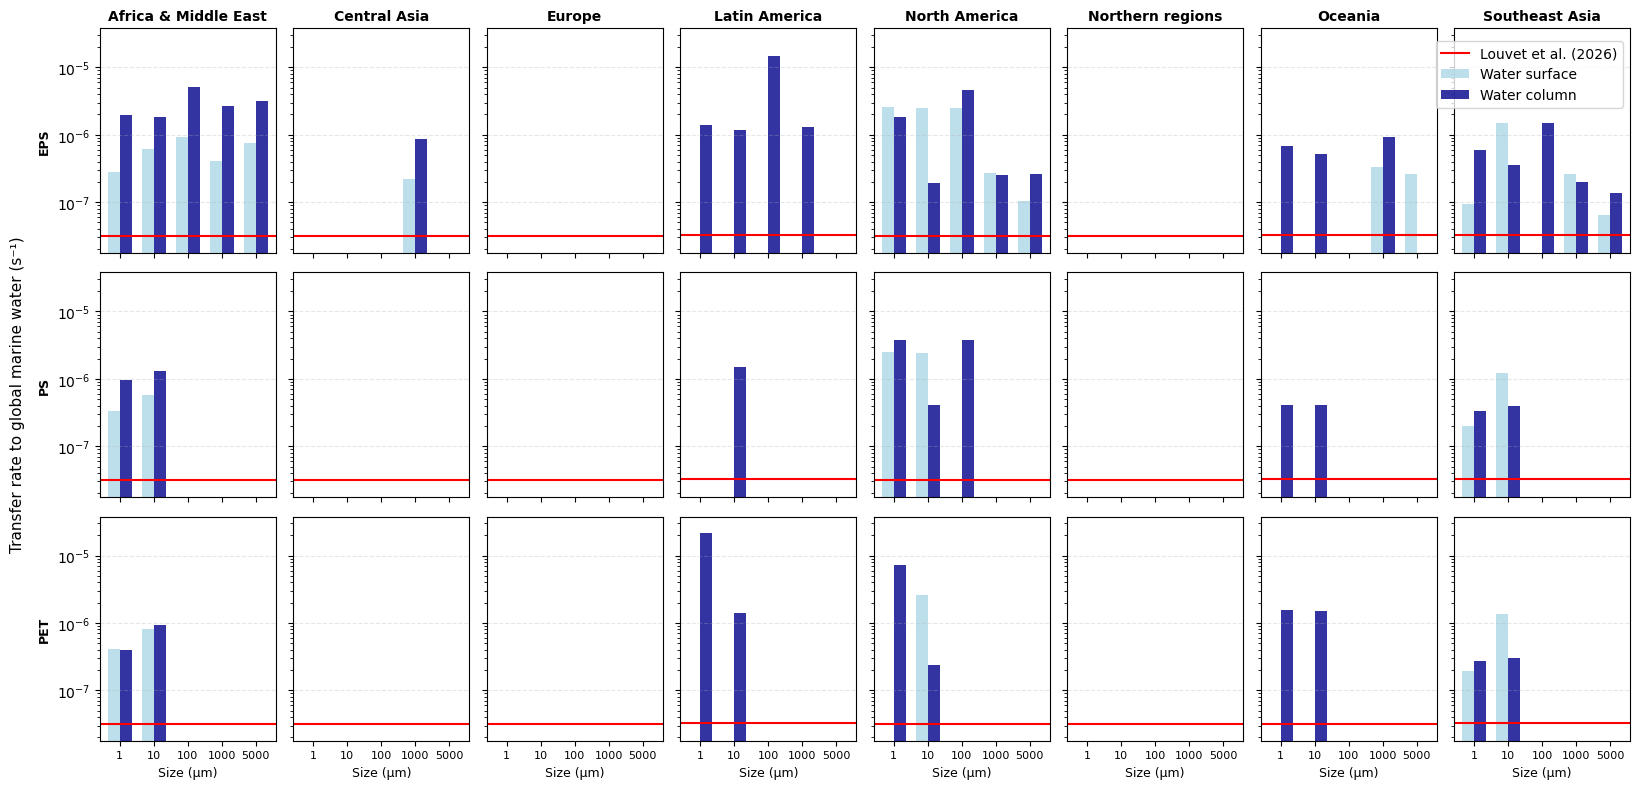

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Define paths
file_path = "input/trackmpd_data/Velocities_all_weighted.xlsx"
path_graphs = "figures/"
sheet_name = "LongFormat"

# Create figures directory if it doesn't exist
os.makedirs(path_graphs, exist_ok=True)

# Define filter conditions
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
polymer_filter = ["EPS", "PS", "PET"]
subcompartment_filter = ["sea", "deepocean"]  # Filter for these two subcompartments

# Reference values for the red horizontal line (s⁻¹)
region_reference = {
    "North America": 3.193379198376459e-08,
    "Latin America": 3.222079198376459e-08,
    "Europe": 3.1884791983764586e-08,
    "Africa & Middle East": 3.1918791983764585e-08,
    "Central Asia": 3.1778791983764585e-08,
    "Southeast Asia": 3.219079198376458e-08,
    "Northern regions": 3.186479198376459e-08,
    "Oceania": 3.212079198376459e-08,
}

# Read the data
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Apply filters - focusing on AdvInput
df_filtered = df[
    (df['size'].isin(size_filter)) &
    (df['shape'].isin(shape_filter)) &
    (df['polymer'].isin(polymer_filter)) &
    (df['SubCompart'].isin(subcompartment_filter)) &
    (df['varName'] == 'AdvInput')
]

# Replace with:
desired_order = ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 
                 'North America', 'Northern regions', 'Oceania', 'Southeast Asia']

regions = [r for r in desired_order if r in df_filtered['region'].unique()]

polymers = polymer_filter  # Use the specified order
sizes = sorted(size_filter)
x_pos = np.arange(len(sizes))

# Calculate global y-axis limits based on all AdvInput values
all_values = df_filtered['Waarde'].values
positive_values = all_values[all_values > 0]
if len(positive_values) > 0:
    y_min_global = min(min(positive_values),min(region_reference.values()))
    y_max_global = max(positive_values)
    # Add a little padding (half order of magnitude)
    y_min_global = 10 ** (np.log10(y_min_global) - 0.25)
    y_max_global = 10 ** (np.log10(y_max_global) + 0.25)
else:
    y_min_global = 1e-10
    y_max_global = 1e-5

print(f"Global y-axis limits: {y_min_global:.2e} to {y_max_global:.2e}")
print(f"Number of data points: {len(df_filtered)}")
print(f"Regions found: {regions}")

# Create figure with subplots
fig, axes = plt.subplots(nrows=len(polymers), ncols=len(regions),
                         figsize=(18, 8), sharex=True, sharey=True)

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Flag to add red line legend entry only once
added_line_legend = False

# Plot data as simple bar charts
plot_idx = 0
for i, polymer in enumerate(polymers):
    for j, region in enumerate(regions):
        ax = axes[i, j]

        # Prepare arrays for sea and deepocean values for this polymer/region
        sea_values = []
        deepocean_values = []

        # Filter data for current polymer and region
        subset = df_filtered[
            (df_filtered['polymer'] == polymer) &
            (df_filtered['region'] == region)
        ].sort_values('size')

        if not subset.empty:
            # Create a dictionary to store values by size and subcompartment
            values_by_size = {}
            for _, row in subset.iterrows():
                size_val = row['size']
                subcomp = row['SubCompart']
                value = row['Waarde']

                if size_val not in values_by_size:
                    values_by_size[size_val] = {'sea': None, 'deepocean': None}
                values_by_size[size_val][subcomp] = value

            # Create grouped bar chart for sea and deepocean
            width = 0.35  # Width of each bar
            x_pos_grouped = np.arange(len(sizes))

            # Get values in the correct size order
            for k, size in enumerate(sizes):
                if size in values_by_size:
                    sea_val = values_by_size[size].get('sea', 0)
                    deepocean_val = values_by_size[size].get('deepocean', 0)
                else:
                    sea_val = 0
                    deepocean_val = 0
                sea_values.append(sea_val)
                deepocean_values.append(deepocean_val)

            # Plot bars for sea (left bar)
            bars_sea = ax.bar(x_pos_grouped - width/2, sea_values, width,
                            label='Water surface' if i == 0 and j == 0 else "",
                            color='lightblue', alpha=0.8)

            # Plot bars for deepocean (right bar)
            bars_deep = ax.bar(x_pos_grouped + width/2, deepocean_values, width,
                              label='Water column' if i == 0 and j == 0 else "",
                              color='darkblue', alpha=0.8)

            # Set y-axis to log scale and apply global limits
            ax.set_yscale('log')
            ax.set_ylim(y_min_global, y_max_global)

        # --- Add red reference line for this region ---
        ref_value = region_reference.get(region)
        if ref_value is not None:
            # Draw horizontal line across the entire x‑axis
            ax.axhline(y=ref_value, color='red', linestyle='-', linewidth=1.5,
                       label='Louvet et al. (2026)' if not added_line_legend else "")
            if not added_line_legend:
                added_line_legend = True

        # Set x-axis ticks
        ax.set_xticks(x_pos)
        ax.set_xticklabels([str(s) for s in sizes], fontsize=8)

        # Add region label only for top row
        if i == 0:
            ax.set_title(region, fontsize=10, fontweight='bold')

        # Add polymer label only for first column
        if j == 0:
            ax.set_ylabel(f'{polymer}', fontsize=9, fontweight='bold')

        # Set x-axis label only for bottom row
        if i == len(polymers) - 1:
            ax.set_xlabel('Size (μm)', fontsize=9)

        # Simple grid
        ax.grid(True, axis='y', alpha=0.3, linestyle='--')

        plot_idx += 1

# Add a single y-axis label for the entire figure
fig.text(0.02, 0.5, 'Transfer rate to global marine water (s⁻¹)', va='center',
         rotation='vertical', fontsize=11)

# Add legend 
fig.legend(loc='upper right', bbox_to_anchor=(0.92, 0.95), fontsize=10)

plt.tight_layout()
plt.subplots_adjust(left=0.07, right=0.92)

# Save the figure
plt.savefig(os.path.join(path_graphs, 'Figure S.14.pdf'), bbox_inches='tight')

plt.show()

Global y-axis limits: 4.70e-11 to 3.09e+02
Number of data points: 360
Regions found: ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America', 'North America', 'Northern regions', 'Oceania', 'Southeast Asia']


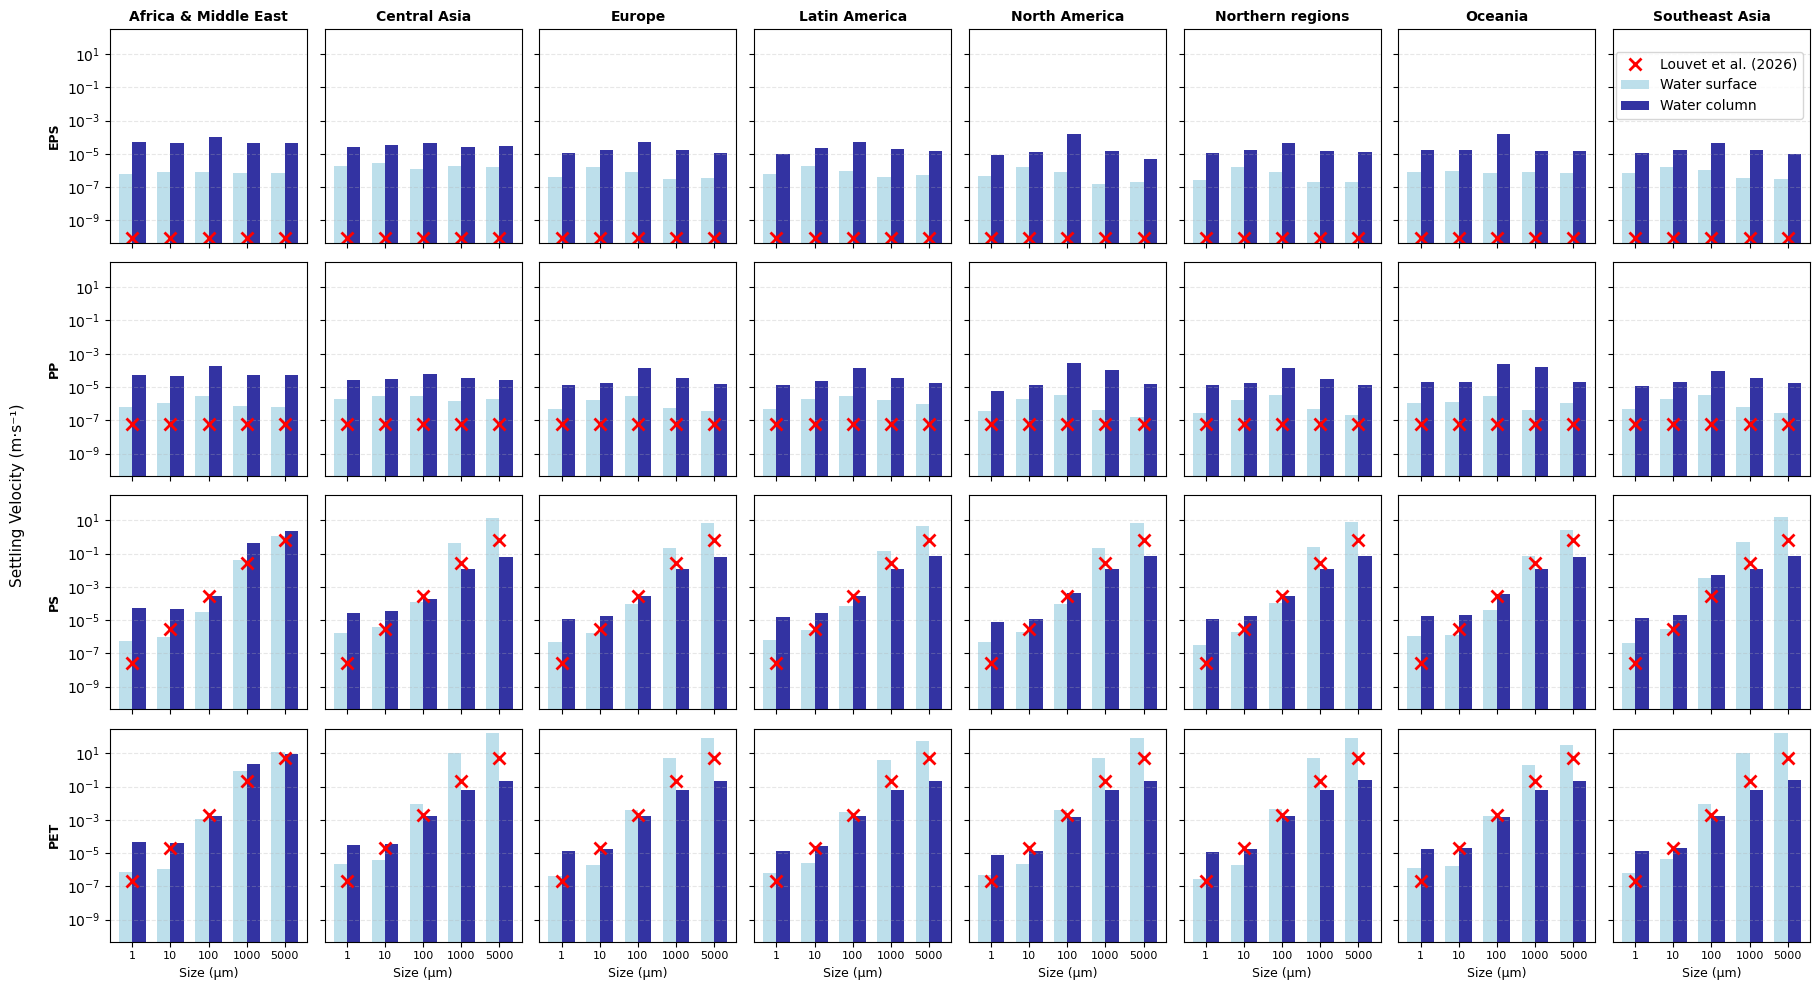

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ------------------------------
# Paths and file reading
# ------------------------------
file_path = "input/trackmpd_data/Velocities_all_weighted.xlsx"
path_graphs = "figures/"
sheet_name = "LongFormat"

os.makedirs(path_graphs, exist_ok=True)

# Filters
size_filter = [1, 10, 100, 1000, 5000]
shape_filter = ["Sphere"]
polymer_filter = ["EPS", "PP", "PS", "PET"]        # PP added
subcompartment_filter = ["sea", "deepocean"]

# ------------------------------
# Stokes’ law parameters (for PS and PET)
# ------------------------------
rho_water = 1000.0      # kg/m³
g = 9.81                # m/s²
mu = 0.001              # Pa·s (water at 20°C)

polymer_density = {
    "PS": 1050.0,       # kg/m³
    "PET": 1380.0,
    "EPS": None,        # special case: fixed value
    "PP": None          # special case: fixed value
}

# Fixed default velocities (m/s)
DEFAULT_VEL = {
    "EPS": 8.35e-11,
    "PP":  5.67e-8
}

def stokes_velocity(diameter_um, rho_p):
    """
    Compute Stokes settling velocity for a sphere.
    diameter_um : diameter in micrometres
    rho_p       : particle density (kg/m³)
    Returns velocity in m/s.
    """
    r = diameter_um * 1e-6 / 2.0          # radius in m
    v = (2/9) * (rho_p - rho_water) * g * (r**2) / mu
    return v

# ------------------------------
# Compute default velocities for each polymer & size
# ------------------------------
default_velocities = {}
for poly in polymer_filter:
    default_velocities[poly] = {}
    if poly in DEFAULT_VEL:          # EPS or PP
        for sz in size_filter:
            default_velocities[poly][sz] = DEFAULT_VEL[poly]
    else:                            # PS, PET
        rho_p = polymer_density[poly]
        for sz in size_filter:
            default_velocities[poly][sz] = stokes_velocity(sz, rho_p)

# ------------------------------
# Read data and apply filters
# ------------------------------
df = pd.read_excel(file_path, sheet_name=sheet_name)

df_filtered = df[
    (df['size'].isin(size_filter)) &
    (df['shape'].isin(shape_filter)) &
    (df['polymer'].isin(polymer_filter)) &
    (df['SubCompart'].isin(subcompartment_filter)) &
    (df['varName'] == 'VelInput')
]


# Regions in desired order
desired_order = ['Africa & Middle East', 'Central Asia', 'Europe', 'Latin America',
                 'North America', 'Northern regions', 'Oceania', 'Southeast Asia']
regions = [r for r in desired_order if r in df_filtered['region'].unique()]

polymers = polymer_filter
sizes = sorted(size_filter)
x_pos = np.arange(len(sizes))

# ------------------------------
# Determine global y‑axis limits (including default values)
# ------------------------------
all_measured = df_filtered['Waarde'].values
positive_measured = all_measured[all_measured > 0]

all_defaults = []
for poly in polymers:
    for sz in sizes:
        all_defaults.append(default_velocities[poly][sz])
all_defaults = np.array(all_defaults)

if len(positive_measured) > 0:
    y_min = min(positive_measured.min(), all_defaults.min())
    y_max = max(positive_measured.max(), all_defaults.max())
else:
    y_min = all_defaults.min()
    y_max = all_defaults.max()

# Add half order of magnitude padding
y_min = 10 ** (np.log10(y_min) - 0.25)
y_max = 10 ** (np.log10(y_max) + 0.25)

print(f"Global y-axis limits: {y_min:.2e} to {y_max:.2e}")
print(f"Number of data points: {len(df_filtered)}")
print(f"Regions found: {regions}")

# ------------------------------
# Create figure with subplots (now 4 rows)
# ------------------------------
fig, axes = plt.subplots(nrows=len(polymers), ncols=len(regions),
                         figsize=(20, 10), sharex=True, sharey=True)   # slightly larger

added_cross_legend = False
width = 0.35   # bar width

for i, polymer in enumerate(polymers):
    for j, region in enumerate(regions):
        ax = axes[i, j]

        # ---- Bar chart (sea vs deepocean) ----
        sea_values = []
        deepocean_values = []
        subset = df_filtered[
            (df_filtered['polymer'] == polymer) &
            (df_filtered['region'] == region)
        ].sort_values('size')

        if not subset.empty:
            values_by_size = {}
            for _, row in subset.iterrows():
                sz = row['size']
                subcomp = row['SubCompart']
                val = row['Waarde']
                if sz not in values_by_size:
                    values_by_size[sz] = {'sea': None, 'deepocean': None}
                values_by_size[sz][subcomp] = val

            for sz in sizes:
                if sz in values_by_size:
                    sea_values.append(values_by_size[sz].get('sea', 0))
                    deepocean_values.append(values_by_size[sz].get('deepocean', 0))
                else:
                    sea_values.append(0)
                    deepocean_values.append(0)

            # Plot bars
            ax.bar(x_pos - width/2, sea_values, width,
                   label='Water surface' if (i==0 and j==0) else "",
                   color='lightblue', alpha=0.8)
            ax.bar(x_pos + width/2, deepocean_values, width,
                   label='Water column' if (i==0 and j==0) else "",
                   color='darkblue', alpha=0.8)

        # ---- Add red crosses for default velocities ----
        for k, sz in enumerate(sizes):
            v_default = default_velocities[polymer][sz]
            ax.plot(x_pos[k], v_default, 'rx', markersize=8, markeredgewidth=2,
                    label='Louvet et al. (2026)' if not added_cross_legend else "")
            if not added_cross_legend:
                added_cross_legend = True

        # Axis formatting
        ax.set_yscale('log')
        ax.set_ylim(y_min, y_max)
        ax.set_xticks(x_pos)
        ax.set_xticklabels([str(s) for s in sizes], fontsize=8)
        ax.grid(True, axis='y', alpha=0.3, linestyle='--')

        if i == 0:
            ax.set_title(region, fontsize=10, fontweight='bold')
        if j == 0:
            ax.set_ylabel(f'{polymer}', fontsize=9, fontweight='bold')
        if i == len(polymers) - 1:
            ax.set_xlabel('Size (μm)', fontsize=9)

# Figure‑level labels and legend
fig.text(0.02, 0.5, 'Settling Velocity (m·s⁻¹)', va='center',
         rotation='vertical', fontsize=11)
fig.legend(loc='upper right', bbox_to_anchor=(0.92, 0.95), fontsize=10)

plt.tight_layout()
plt.subplots_adjust(left=0.07, right=0.92)
plt.savefig(os.path.join(path_graphs, 'Figure S.15.pdf'), bbox_inches='tight')
plt.show()